# 03 - Feature Engineering

## Détection de la fraude Mobile Money via Graph Learning dynamique

Ce notebook transforme les principaux enseignements issus de l'analyse exploratoire en variables exploitables par les futurs modèles de Machine Learning et de Graph Learning.

L'objectif n'est pas de multiplier les variables, mais de construire des features financièrement interprétables, compatibles avec la dimension temporelle de PaySim et respectant strictement la causalité.

## 1. Introduction et objectifs du Feature Engineering

L'analyse exploratoire réalisée dans le notebook `02_EDA.ipynb` a mis en évidence plusieurs caractéristiques importantes du problème de fraude.

Les principaux constats utiles au Feature Engineering sont les suivants :

- la fraude est extrêmement rare dans PaySim ;
- les transactions frauduleuses sont observées principalement sur les opérations `TRANSFER` et `CASH_OUT` ;
- les montants frauduleux sont généralement plus élevés et fortement asymétriques ;
- un comportement de vidage presque complet du compte source apparaît comme un signal particulièrement discriminant ;
- les soldes avant et après transaction sont fortement corrélés, ce qui motive la construction de variables décrivant leurs transformations ;
- les comptes sources sont très peu récurrents alors que certaines destinations reçoivent davantage de transactions ;
- la temporalité est essentielle et toute information comportementale doit être calculée uniquement à partir du passé ;
- le graphe transactionnel est extrêmement sparse et la future tâche de Graph Learning correspond à une classification temporelle des arêtes.

Le Feature Engineering sera donc organisé autour de quatre familles principales :

1. **features transactionnelles**, décrivant les propriétés de la transaction courante ;
2. **features temporelles**, décrivant sa position dans la chronologie simulée ;
3. **features comportementales historiques**, décrivant l'activité passée des comptes ;
4. **features relationnelles**, destinées notamment aux futurs modèles de Graph Learning.

Une attention particulière sera portée aux variables fortement liées au mécanisme de simulation PaySim, notamment les indicateurs de vidage du compte et les incohérences ou résidus de soldes. Elles seront conservées mais identifiées séparément afin de permettre ultérieurement une étude d'ablation.

La contrainte méthodologique principale du notebook est l'absence de **data leakage** : une transaction à l'instant \(t\) ne devra jamais utiliser une information provenant d'une transaction future.

Le notebook produira finalement deux représentations complémentaires :

- un dataset destiné aux modèles de Machine Learning classiques ;
- un dataset intermédiaire **Graph-ready** conservant la structure source-destination-temps nécessaire à la construction du graphe temporel.

### Principes méthodologiques

Chaque feature créée dans ce notebook devra répondre à une question comportementale ou financière identifiable.

Les transformations seront évaluées selon quatre critères :

- leur interprétabilité métier ;
- leur utilité potentielle pour la détection de fraude ;
- leur compatibilité avec une utilisation en production temporelle ;
- leur coût de calcul et leur consommation mémoire sur plus de six millions de transactions.

Les agrégations globales utilisant des observations futures seront exclues.

Les statistiques historiques seront calculées de manière causale, à l'aide de décalages temporels, de cumuls historiques ou d'états incrémentaux.

Le Feature Engineering sera réalisé progressivement afin de contrôler à chaque étape :

- la cohérence des nouvelles variables ;
- leur stabilité numérique ;
- leur consommation mémoire ;
- les risques de fuite d'information.

In [1]:
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42

## 2. Chargement, configuration et vérifications minimales

Le dataset PaySim contient plusieurs millions de transactions. Le chargement doit donc limiter autant que possible les conversions inutiles et les copies complètes du DataFrame.

Les variables monétaires sont conservées avec une précision suffisante, car certaines futures features compareront directement les montants et les soldes.

La variable `type` peut être représentée comme une catégorie, tandis que les labels binaires peuvent utiliser des entiers de petite taille.

Aucune transformation métier n'est réalisée à cette étape.

In [2]:
DATA_PATH = Path("../data/raw/paysim.csv")

print(f"Dataset : {DATA_PATH}")
print(f"Fichier disponible : {DATA_PATH.exists()}")

Dataset : ..\data\raw\paysim.csv
Fichier disponible : True


In [3]:
usecols = [
    "step",
    "type",
    "amount",
    "nameOrig",
    "oldbalanceOrg",
    "newbalanceOrig",
    "nameDest",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud",
    "isFlaggedFraud",
]

dtype_map = {
    "step": "int16",
    "type": "category",
    "amount": "float64",
    "nameOrig": "string",
    "oldbalanceOrg": "float64",
    "newbalanceOrig": "float64",
    "nameDest": "string",
    "oldbalanceDest": "float64",
    "newbalanceDest": "float64",
    "isFraud": "int8",
    "isFlaggedFraud": "int8",
}

In [4]:
df = pd.read_csv(
    DATA_PATH,
    usecols=usecols,
    dtype=dtype_map,
)

print("Dataset chargé.")

Dataset chargé.


In [5]:
print(f"Dimensions : {df.shape}")
print(f"Nombre de transactions : {len(df):,}")
print(f"Nombre de colonnes : {df.shape[1]}")

display(df.head())

Dimensions : (6362620, 11)
Nombre de transactions : 6,362,620
Nombre de colonnes : 11


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


In [6]:
dtype_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
})

display(dtype_summary)

,dtype,non_null
step,int16,6362620
type,category,6362620
amount,float64,6362620
nameOrig,string,6362620
oldbalanceOrg,float64,6362620
newbalanceOrig,float64,6362620
nameDest,string,6362620
oldbalanceDest,float64,6362620
newbalanceDest,float64,6362620
isFraud,int8,6362620


In [7]:
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
memory_gb = memory_mb / 1024

print(f"Mémoire utilisée : {memory_mb:,.2f} MB")
print(f"Mémoire utilisée : {memory_gb:,.2f} GB")

Mémoire utilisée : 497.35 MB
Mémoire utilisée : 0.49 GB


In [8]:
step_min = df["step"].min()
step_max = df["step"].max()
n_steps = df["step"].nunique()
is_chronological = df["step"].is_monotonic_increasing

print(f"Step minimum : {step_min}")
print(f"Step maximum : {step_max}")
print(f"Nombre de steps distincts : {n_steps}")
print(f"Ordre chronologique : {is_chronological}")

Step minimum : 1
Step maximum : 743
Nombre de steps distincts : 743
Ordre chronologique : True


In [9]:
fraud_count = int(df["isFraud"].sum())
fraud_rate = df["isFraud"].mean() * 100

print(f"Transactions frauduleuses : {fraud_count:,}")
print(f"Taux de fraude : {fraud_rate:.4f} %")

Transactions frauduleuses : 8,213
Taux de fraude : 0.1291 %


In [10]:
expected_columns = set(usecols)
loaded_columns = set(df.columns)

missing_columns = expected_columns - loaded_columns
unexpected_columns = loaded_columns - expected_columns

print(f"Colonnes manquantes : {missing_columns}")
print(f"Colonnes inattendues : {unexpected_columns}")

Colonnes manquantes : set()
Colonnes inattendues : set()


### Vérifications initiales

Le dataset chargé contient 6 362 620 transactions et 11 variables, conformément aux résultats obtenus lors de l'analyse exploratoire.

Les 8 213 transactions frauduleuses sont bien présentes, soit un taux de fraude de 0,1291 %. Cette vérification confirme que le fichier utilisé pour le Feature Engineering correspond au dataset étudié précédemment.

Les variables ont été chargées avec des types adaptés à leur utilisation future. Les montants et soldes sont conservés en `float64` afin de préserver la précision nécessaire aux calculs de ratios, variations et résidus de soldes.

La consommation mémoire du DataFrame est d'environ 0,49 GB, ce qui reste compatible avec les prochaines transformations, sous réserve de limiter les copies complètes et les structures intermédiaires volumineuses.

La variable temporelle `step` varie de 1 à 743 et le DataFrame est déjà ordonné chronologiquement. Aucun tri supplémentaire n'est donc nécessaire.

Cependant, plusieurs transactions peuvent appartenir au même `step`. Comme PaySim ne fournit pas d'ordre transactionnel plus fin à l'intérieur d'un step, les futures features historiques considéreront les transactions d'un même step comme contemporaines. Une transaction observée au step t ne pourra donc utiliser que des informations provenant des steps strictement antérieurs à t.

Cette convention constitue une règle centrale de prévention du data leakage pour la suite du notebook.

## 3. Définition des règles de Feature Engineering

Le Feature Engineering est organisé en plusieurs familles correspondant à des niveaux d'information différents.

### 3.1 Features transactionnelles

Les features transactionnelles décrivent uniquement la transaction courante et les états financiers directement associés à celle-ci.

Elles chercheront notamment à représenter :

- l'échelle du montant transféré ;
- le montant relativement au solde disponible ;
- les variations de soldes avant et après l'opération ;
- les situations de solde nul ;
- les opérations conduisant à un vidage du compte ;
- certaines interactions entre le type d'opération et les caractéristiques financières.

Ces variables ne nécessitent aucune information historique et peuvent donc être calculées directement à partir de la transaction courante.

### 3.2 Features temporelles

Les features temporelles décriront la position de la transaction dans la chronologie simulée de PaySim.

La variable `step` restera la référence temporelle principale.

Des transformations pourront notamment représenter :

- la position dans un cycle de 24 steps ;
- le jour simulé ;
- la périodicité à l'aide de représentations sinusoïdales et cosinusoïdales.

Ces transformations ne supposent pas qu'un step PaySim représente parfaitement une heure réelle. Elles décrivent uniquement la structure temporelle du simulateur.

### 3.3 Features comportementales historiques

Les features comportementales chercheront à caractériser l'activité passée des comptes.

Pour une transaction observée au step t, les statistiques historiques ne pourront utiliser que des transactions appartenant à des steps strictement inférieurs à t.

Pour l'émetteur, les informations étudiées pourront inclure :

- le nombre de transactions précédentes ;
- le volume précédemment envoyé ;
- le montant moyen historique ;
- le nombre de destinations déjà rencontrées ;
- le temps écoulé depuis la dernière émission.

Pour le destinataire, elles pourront inclure :

- le nombre de transactions précédemment reçues ;
- le volume précédemment reçu ;
- le montant moyen historique reçu ;
- le nombre de sources distinctes déjà observées ;
- le temps écoulé depuis la dernière réception.

Cette famille de variables est particulièrement importante pour les destinations, dont la récurrence est plus élevée dans PaySim.

### 3.4 Features relationnelles et Graph-ready

Les features relationnelles décriront progressivement la position historique des comptes dans le graphe transactionnel.

Elles pourront notamment représenter :

- le degré sortant historique ;
- le degré entrant historique ;
- le nombre de voisins sortants distincts ;
- le nombre de voisins entrants distincts ;
- le volume historiquement envoyé ;
- le volume historiquement reçu.

Ces variables seront calculées de manière temporelle et causale.

Elles pourront être utilisées comme variables explicatives dans les modèles classiques, mais également comme attributs historiques de nœuds lors de la future construction du graphe dynamique.

### 3.5 Convention temporelle et prévention du data leakage

La prévention du data leakage constitue une contrainte centrale du Feature Engineering.

Pour une transaction appartenant au step t :

\[
\text{historique disponible}(t)
=
\{\text{transactions dont le step} < t\}
\]

Les transactions appartenant au même step sont considérées comme contemporaines.

Cette convention est nécessaire car PaySim ne fournit pas de timestamp permettant d'établir un ordre fiable entre plusieurs transactions appartenant au même step.

Par conséquent, une simple utilisation de `shift()` ou de `cumsum()` suivant l'ordre des lignes pourrait être insuffisante : elle risquerait d'utiliser des transactions précédentes dans le DataFrame mais appartenant au même step.

Les futures statistiques historiques seront donc construites de façon à figer l'état historique au début de chaque step, puis à mettre cet état à jour uniquement après le traitement du step courant.

In [11]:
feature_plan = pd.DataFrame([
    {
        "family": "transaction",
        "examples": "log_amount, ratios, balance changes",
        "historical": False,
        "strict_past_required": False,
        "use_ml": True,
        "use_graph": True,
    },
    {
        "family": "temporal",
        "examples": "cycle_position, cycle_sin, cycle_cos, simulated_day",
        "historical": False,
        "strict_past_required": False,
        "use_ml": True,
        "use_graph": True,
    },
    {
        "family": "behavioral_origin",
        "examples": "previous count, volume, mean amount, last activity",
        "historical": True,
        "strict_past_required": True,
        "use_ml": True,
        "use_graph": True,
    },
    {
        "family": "behavioral_destination",
        "examples": "previous count, volume, sources, last activity",
        "historical": True,
        "strict_past_required": True,
        "use_ml": True,
        "use_graph": True,
    },
    {
        "family": "graph",
        "examples": "historical degree, neighbors, sent/received volume",
        "historical": True,
        "strict_past_required": True,
        "use_ml": True,
        "use_graph": True,
    },
])

display(feature_plan)

,family,examples,historical,strict_past_required,use_ml,use_graph
0,transaction,"log_amount, ratios, balance changes",False,False,True,True
1,temporal,"cycle_position, cycle_sin, cycle_cos, simulate...",False,False,True,True
2,behavioral_origin,"previous count, volume, mean amount, last acti...",True,True,True,True
3,behavioral_destination,"previous count, volume, sources, last activity",True,True,True,True
4,graph,"historical degree, neighbors, sent/received vo...",True,True,True,True


### 3.6 Features potentiellement spécifiques à PaySim

L'EDA a montré qu'un ensemble de variables liées au vidage du compte source possède un pouvoir discriminant particulièrement élevé.

Ces comportements peuvent refléter une logique réelle de fraude, mais leur fréquence dans PaySim semble également fortement liée au mécanisme utilisé par le simulateur pour générer certaines transactions frauduleuses.

Ces variables ne seront donc pas supprimées. Elles seront isolées dans une famille spécifique afin de permettre ultérieurement une étude d'ablation.

Deux ensembles seront distingués :

- **Core Features** : variables considérées comme relativement générales et transférables ;
- **PaySim-sensitive Features** : variables potentiellement fortement dépendantes du mécanisme de simulation.

Cette distinction permettra de comparer ultérieurement les performances avec et sans les signaux les plus spécifiques à PaySim.

In [12]:
core_feature_candidates = [
    "log_amount",
    "amount_to_oldbalance_ratio",
    "amount_to_dest_balance_ratio",
    "origin_balance_change",
    "destination_balance_change",
    "origin_zero_before",
    "origin_zero_after",
    "destination_zero_before",
    "destination_zero_after",
    "cycle_position",
    "cycle_sin",
    "cycle_cos",
    "simulated_day",
]

paysim_sensitive_candidates = [
    "origin_balance_residual",
    "destination_balance_residual",
    "origin_emptied",
    "amount_equals_oldbalance",
    "full_balance_transfer",
]

print(f"Core feature candidates : {len(core_feature_candidates)}")
print(f"PaySim-sensitive candidates : {len(paysim_sensitive_candidates)}")

Core feature candidates : 13
PaySim-sensitive candidates : 5


In [13]:
feature_engineering_rules = pd.DataFrame({
    "rule": [
        "Use current transaction information",
        "Use only steps strictly before t for historical features",
        "Treat transactions within the same step as contemporaneous",
        "Never derive predictors from isFraud",
        "Never compute target-based global statistics",
        "Do not use raw account IDs as classical categorical predictors",
        "Preserve account IDs for future graph construction",
        "Separate PaySim-sensitive features for ablation",
        "Prefer vectorized and memory-efficient operations",
    ],
    "required": [True] * 9,
})

display(feature_engineering_rules)

,rule,required
0,Use current transaction information,True
1,Use only steps strictly before t for historica...,True
2,Treat transactions within the same step as con...,True
3,Never derive predictors from isFraud,True
4,Never compute target-based global statistics,True
5,Do not use raw account IDs as classical catego...,True
6,Preserve account IDs for future graph construc...,True
7,Separate PaySim-sensitive features for ablation,True
8,Prefer vectorized and memory-efficient operations,True


## 4. Features liées au montant

L'EDA a montré que les montants des transactions sont fortement asymétriques et que les transactions frauduleuses présentent généralement des montants plus élevés.

Le montant brut reste une information importante, mais son échelle et sa distribution peuvent limiter son exploitation directe par certains modèles.

Trois transformations sont étudiées dans cette section :

- `log_amount`, qui réduit l'asymétrie de la distribution tout en conservant l'ordre des montants ;
- `amount_to_oldbalance_ratio`, qui mesure la taille de la transaction relativement au solde disponible du compte source ;
- `amount_to_dest_balance_ratio`, qui compare le montant transféré au solde précédent du destinataire.

Ces variables utilisent uniquement les informations disponibles dans la transaction courante. Elles ne nécessitent aucune information historique et ne présentent donc pas de risque de fuite temporelle.

Les ratios ne sont définis que lorsque le dénominateur est strictement positif. Les situations de soldes nuls seront représentées explicitement dans la section consacrée aux soldes.

In [14]:
# Transformer le montant
df["log_amount"] = np.log1p(df["amount"]).astype("float32")

print(df["log_amount"].dtype)
print(df["log_amount"].isna().sum())

float32
0


In [15]:
# Calculer le ratio avec le solde source
amount_to_origin = np.divide(
    df["amount"].to_numpy(),
    df["oldbalanceOrg"].to_numpy(),
    out=np.full(len(df), np.nan, dtype="float64"),
    where=df["oldbalanceOrg"].to_numpy() > 0,
)

df["amount_to_oldbalance_ratio"] = amount_to_origin.astype("float32")

del amount_to_origin
gc.collect()

200

In [16]:
# Calculer le ratio avec le solde destination
amount_to_destination = np.divide(
    df["amount"].to_numpy(),
    df["oldbalanceDest"].to_numpy(),
    out=np.full(len(df), np.nan, dtype="float64"),
    where=df["oldbalanceDest"].to_numpy() > 0,
)

df["amount_to_dest_balance_ratio"] = amount_to_destination.astype("float32")

del amount_to_destination
gc.collect()

0

In [17]:
# Sélectionner les nouvelles features
amount_features = [
    "log_amount",
    "amount_to_oldbalance_ratio",
    "amount_to_dest_balance_ratio",
]

amount_feature_control = pd.DataFrame({
    "dtype": df[amount_features].dtypes.astype(str),
    "missing": df[amount_features].isna().sum(),
    "infinite": [
        np.isinf(df[col].to_numpy()).sum()
        for col in amount_features
    ],
    "minimum": [
        df[col].min()
        for col in amount_features
    ],
    "maximum": [
        df[col].max()
        for col in amount_features
    ],
})

display(amount_feature_control)

,dtype,missing,infinite,minimum,maximum
log_amount,float32,0,0,0.0000,18.3421
amount_to_oldbalance_ratio,float32,2102449,0,0.0000,"3,925,475.5000"
amount_to_dest_balance_ratio,float32,2704388,0,0.0000,"5,542,638.5000"


In [18]:
# Vérifier les dénominateurs nuls
zero_balance_control = pd.DataFrame({
    "condition": [
        "oldbalanceOrg = 0",
        "oldbalanceDest = 0",
        "missing origin ratio",
        "missing destination ratio",
    ],
    "count": [
        (df["oldbalanceOrg"] == 0).sum(),
        (df["oldbalanceDest"] == 0).sum(),
        df["amount_to_oldbalance_ratio"].isna().sum(),
        df["amount_to_dest_balance_ratio"].isna().sum(),
    ],
})

zero_balance_control["percentage"] = (
    zero_balance_control["count"] / len(df) * 100
)

display(zero_balance_control)

,condition,count,percentage
0,oldbalanceOrg = 0,2102449,33.0438
1,oldbalanceDest = 0,2704388,42.5043
2,missing origin ratio,2102449,33.0438
3,missing destination ratio,2704388,42.5043


In [19]:
# Comparer les nouvelles features selon la cible
amount_comparison = (
    df.groupby("isFraud", observed=True)[amount_features]
    .agg(["median", "mean"])
    .T
)

amount_comparison.columns = [
    "legitimate",
    "fraud",
]

display(amount_comparison)

legitimate   fraud
log_amount                   median     11.2210 12.9978
                             mean       10.8382 12.8920
amount_to_oldbalance_ratio   median      0.7347  1.0000
                             mean      122.2727  0.9988
amount_to_dest_balance_ratio median      0.2110  0.9931
                             mean       10.2561 69.8954

In [20]:
# Calculer les quantiles
quantiles = [0.50, 0.75, 0.90, 0.95, 0.99]

ratio_quantiles = (
    df.groupby("isFraud", observed=True)[
        [
            "amount_to_oldbalance_ratio",
            "amount_to_dest_balance_ratio",
        ]
    ]
    .quantile(quantiles)
)

display(ratio_quantiles)

amount_to_oldbalance_ratio  amount_to_dest_balance_ratio
isFraud                                                                 
0       0.5000                      0.7347                        0.2110
        0.7500                      6.6847                        0.5664
        0.9000                     39.6323                        1.1786
        0.9500                    177.2671                        3.5847
        0.9900                  1,678.0222                       30.3637
1       0.5000                      1.0000                        0.9931
        0.7500                      1.0000                        5.7454
        0.9000                      1.0000                       26.3958
        0.9500                      1.0000                       67.6346
        0.9900                      1.0000                      575.8376

In [21]:
# Préparer les statistiques
log_amount_stats = (
    df.groupby("isFraud", observed=True)["log_amount"]
    .quantile([0.25, 0.50, 0.75])
    .unstack()
)

log_amount_stats.columns = ["Q1", "Median", "Q3"]

display(log_amount_stats)

,Q1,Median,Q3
isFraud,,,
0,9.5007,11.2210,12.2471
1,11.7527,12.9978,14.2328


In [22]:
# Vérifier la mémoire après création des features
memory_after_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
memory_after_gb = memory_after_mb / 1024

additional_memory_mb = memory_after_mb - memory_mb

print(f"Mémoire actuelle : {memory_after_mb:,.2f} MB")
print(f"Mémoire actuelle : {memory_after_gb:,.2f} GB")
print(f"Mémoire supplémentaire : {additional_memory_mb:,.2f} MB")

Mémoire actuelle : 570.16 MB
Mémoire actuelle : 0.56 GB
Mémoire supplémentaire : 72.81 MB


### Observation

Les trois features liées au montant ont été créées sans produire de valeurs infinies.

`log_amount` ne contient aucune valeur manquante et présente une distribution nettement décalée vers les valeurs élevées pour les fraudes. Sa médiane est d'environ 13,00 pour les transactions frauduleuses contre 11,22 pour les transactions légitimes.

Les ratios présentent des valeurs manquantes structurelles. Environ 33,04 % des transactions possèdent un `oldbalanceOrg` nul et 42,50 % un `oldbalanceDest` nul. Ces proportions correspondent exactement aux valeurs manquantes des ratios associés, confirmant qu'il ne s'agit pas de données manquantes accidentelles mais de ratios mathématiquement non définis.

Le ratio `amount_to_oldbalance_ratio` présente un comportement particulièrement marqué. Sa médiane vaut 1 pour les fraudes et ses quantiles P50 à P99 restent égaux à 1. Ce résultat indique que, lorsque le solde source est renseigné, une grande partie des fraudes correspond à un montant pratiquement égal au solde disponible.

À l'inverse, la distribution légitime de ce ratio possède une queue extrêmement lourde : sa médiane est d'environ 0,735 tandis que sa moyenne dépasse 122 et son maximum atteint plusieurs millions. La moyenne est donc peu représentative pour cette variable.

Le ratio `amount_to_dest_balance_ratio` présente également une séparation intéressante. Sa médiane est proche de 0,99 pour les fraudes contre 0,21 pour les transactions légitimes. Sa distribution reste toutefois fortement asymétrique, notamment pour les transactions frauduleuses.

### Interprétation

`log_amount` constitue une représentation plus stable de l'échelle des transactions et sera conservée comme Core Feature.

Les deux ratios apportent une information relative que le montant brut ne fournit pas directement. Ils sont donc conservés, mais leurs valeurs extrêmes devront être prises en compte lors du futur prétraitement des modèles.

Le comportement presque systématique de `amount_to_oldbalance_ratio` autour de 1 pour les fraudes montre toutefois que son pouvoir prédictif potentiel est fortement lié au pattern de vidage du compte observé dans PaySim. Bien que cette feature possède une interprétation financière générale, elle sera également incluse dans le groupe des variables à tester lors de l'étude d'ablation PaySim-sensitive.

### Décision

Les trois variables sont conservées :

- `log_amount` ;
- `amount_to_oldbalance_ratio` ;
- `amount_to_dest_balance_ratio`.

Les NaN des ratios sont conservés à ce stade et seront associés aux futurs indicateurs de soldes nuls.

Aucun clipping fondé sur des quantiles globaux n'est appliqué avant le split chronologique.

La création des trois colonnes supplémentaires augmente la consommation mémoire d'environ 72,81 MB, ce qui confirme la pertinence du stockage en `float32`.

In [23]:
# Mettre à jour les groupes de features
if "amount_to_oldbalance_ratio" in core_feature_candidates:
    core_feature_candidates.remove("amount_to_oldbalance_ratio")

if "amount_to_oldbalance_ratio" not in paysim_sensitive_candidates:
    paysim_sensitive_candidates.append("amount_to_oldbalance_ratio")

print(f"Core feature candidates : {len(core_feature_candidates)}")
print(f"PaySim-sensitive candidates : {len(paysim_sensitive_candidates)}")

Core feature candidates : 12
PaySim-sensitive candidates : 6


## 5. Features liées aux soldes

Les soldes avant et après transaction sont fortement corrélés dans PaySim. Plutôt que de dépendre uniquement de leurs valeurs brutes, cette section construit des variables décrivant la transformation financière produite par la transaction.

Trois dimensions sont étudiées :

1. la variation effective des soldes ;
2. la cohérence entre le montant de la transaction et les soldes observés ;
3. les situations particulières de soldes nuls ou de vidage du compte.

Les features liées au vidage du compte seront considérées avec une vigilance particulière car l'EDA a montré qu'elles sont fortement associées au mécanisme de génération des fraudes dans PaySim.

In [24]:
# Calculer les variations de soldes
df["origin_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
).astype("float32")

df["destination_balance_change"] = (
    df["newbalanceDest"] - df["oldbalanceDest"]
).astype("float32")

In [25]:
# Calculer les résidus de soldes
df["origin_balance_residual"] = (
    df["oldbalanceOrg"]
    - df["amount"]
    - df["newbalanceOrig"]
).astype("float32")

df["destination_balance_residual"] = (
    df["oldbalanceDest"]
    + df["amount"]
    - df["newbalanceDest"]
).astype("float32")

In [26]:
# Créer les indicateurs de soldes nuls
df["origin_zero_before"] = (
    df["oldbalanceOrg"] == 0
).astype("int8")

df["origin_zero_after"] = (
    df["newbalanceOrig"] == 0
).astype("int8")

df["destination_zero_before"] = (
    df["oldbalanceDest"] == 0
).astype("int8")

df["destination_zero_after"] = (
    df["newbalanceDest"] == 0
).astype("int8")

In [27]:
# Définir la tolérance monétaire
BALANCE_TOLERANCE = 0.01

# Identifier les comptes vidés
df["origin_emptied"] = (
    (df["oldbalanceOrg"] > 0)
    & (df["newbalanceOrig"] == 0)
).astype("int8")

# Identifier les montants égaux au solde
df["amount_equals_oldbalance"] = (
    (df["oldbalanceOrg"] > 0)
    & np.isclose(
        df["amount"],
        df["oldbalanceOrg"],
        rtol=0.0,
        atol=BALANCE_TOLERANCE,
    )
).astype("int8")

# Identifier les transferts du solde complet
df["full_balance_transfer"] = (
    (df["origin_emptied"] == 1)
    & (df["amount_equals_oldbalance"] == 1)
).astype("int8")

In [28]:
# Sélectionner les features de soldes
balance_features = [
    "origin_balance_change",
    "destination_balance_change",
    "origin_balance_residual",
    "destination_balance_residual",
    "origin_zero_before",
    "origin_zero_after",
    "destination_zero_before",
    "destination_zero_after",
    "origin_emptied",
    "amount_equals_oldbalance",
    "full_balance_transfer",
]

balance_feature_control = pd.DataFrame({
    "dtype": df[balance_features].dtypes.astype(str),
    "missing": df[balance_features].isna().sum(),
    "infinite": [
        np.isinf(df[col].to_numpy()).sum()
        for col in balance_features
    ],
    "minimum": [
        df[col].min()
        for col in balance_features
    ],
    "maximum": [
        df[col].max()
        for col in balance_features
    ],
})

display(balance_feature_control)

,dtype,missing,infinite,minimum,maximum
origin_balance_change,float32,0,0,"-1,915,267.8750","10,000,000.0000"
destination_balance_change,float32,0,0,"-13,060,826.0000","105,687,840.0000"
origin_balance_residual,float32,0,0,"-92,445,520.0000",0.0100
destination_balance_residual,float32,0,0,"-75,885,728.0000","13,191,234.0000"
origin_zero_before,int8,0,0,0.0000,1.0000
origin_zero_after,int8,0,0,0.0000,1.0000
destination_zero_before,int8,0,0,0.0000,1.0000
destination_zero_after,int8,0,0,0.0000,1.0000
origin_emptied,int8,0,0,0.0000,1.0000
amount_equals_oldbalance,int8,0,0,0.0000,1.0000


In [39]:
# Résumer les indicateurs binaires
binary_balance_summary = pd.DataFrame({
    "feature": binary_balance_features,
    "count": [
        int(df[col].sum())
        for col in binary_balance_features
    ],
})

binary_balance_summary["percentage"] = (
    binary_balance_summary["count"] / len(df) * 100
)

display(binary_balance_summary)

,feature,count,percentage
0,origin_zero_before,2102449,33.0438
1,origin_zero_after,3609566,56.7308
2,destination_zero_before,2704388,42.5043
3,destination_zero_after,2439433,38.3401
4,origin_emptied,1520581,23.8987
5,amount_equals_oldbalance,8019,0.1260
6,full_balance_transfer,8008,0.1259


In [40]:
# Comparer les indicateurs selon la cible
balance_fraud_summary = []

for feature in binary_balance_features:
    mask = df[feature] == 1

    total = int(mask.sum())
    frauds = int(df.loc[mask, "isFraud"].sum())

    fraud_rate = (
        frauds / total * 100
        if total > 0
        else np.nan
    )

    fraud_coverage = (
        frauds / df["isFraud"].sum() * 100
    )

    balance_fraud_summary.append({
        "feature": feature,
        "transactions": total,
        "frauds": frauds,
        "fraud_rate_pct": fraud_rate,
        "fraud_coverage_pct": fraud_coverage,
    })

balance_fraud_summary = pd.DataFrame(balance_fraud_summary)

display(balance_fraud_summary)

,feature,transactions,frauds,fraud_rate_pct,fraud_coverage_pct
0,origin_zero_before,2102449,41,0.0020,0.4992
1,origin_zero_after,3609566,8053,0.2231,98.0519
2,destination_zero_before,2704388,5351,0.1979,65.1528
3,destination_zero_after,2439433,4091,0.1677,49.8113
4,origin_emptied,1520581,8012,0.5269,97.5527
5,amount_equals_oldbalance,8019,8018,99.9875,97.6257
6,full_balance_transfer,8008,8008,100.0000,97.5040


In [41]:
# Comparer les résidus selon la cible
residual_features = [
    "origin_balance_residual",
    "destination_balance_residual",
]

residual_comparison = (
    df.groupby("isFraud", observed=True)[residual_features]
    .agg(["median", "mean"])
    .T
)

residual_comparison.columns = [
    "legitimate",
    "fraud",
]

display(residual_comparison)

legitimate        fraud
origin_balance_residual      median  -69,049.3125       0.0000
                             mean   -201,338.5469 -10,692.3252
destination_balance_residual median    3,500.6799   2,231.4600
                             mean     54,692.2305 732,509.3125

In [42]:
# Calculer les quantiles des résidus
residual_quantiles = (
    df.groupby("isFraud", observed=True)[residual_features]
    .quantile([0.25, 0.50, 0.75, 0.95, 0.99])
)

display(residual_quantiles)

origin_balance_residual  destination_balance_residual
isFraud                                                              
0       0.2500            -249,953.4297                        0.0000
        0.5000             -69,049.3125                    3,500.6799
        0.7500              -3,034.3051                   29,259.8047
        0.9500                   0.0000                  455,576.5156
        0.9900                   0.0000                  788,640.3437
1       0.2500                   0.0000                        0.0000
        0.5000                   0.0000                    2,231.4600
        0.7500                   0.0000                  442,722.0000
        0.9500                   0.0000                4,555,771.3000
        0.9900                   0.0000               10,000,000.0000

In [43]:
# Vérifier la mémoire
memory_balance_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
memory_balance_gb = memory_balance_mb / 1024

balance_added_mb = memory_balance_mb - memory_after_mb

print(f"Mémoire actuelle : {memory_balance_mb:,.2f} MB")
print(f"Mémoire actuelle : {memory_balance_gb:,.2f} GB")
print(
    f"Mémoire ajoutée par la Section 5 : "
    f"{balance_added_mb:,.2f} MB"
)

Mémoire actuelle : 709.72 MB
Mémoire actuelle : 0.69 GB
Mémoire ajoutée par la Section 5 : 139.56 MB


### Observation

Les features liées aux soldes ont été créées sans générer de valeurs manquantes ou infinies.

Les soldes nuls sont fréquents dans PaySim. Environ 33,04 % des transactions présentent un solde source initial nul, tandis que 56,73 % se terminent avec un solde source nul. Les indicateurs correspondants apportent donc une information explicite complémentaire aux ratios créés précédemment.

Cependant, leur relation avec la fraude varie fortement.

`origin_zero_before` est très peu associé à la fraude : seulement 41 transactions frauduleuses présentent ce comportement, soit environ 0,50 % de l'ensemble des fraudes.

À l'inverse, `origin_zero_after` couvre environ 98,05 % des fraudes, mais concerne plus de 3,6 millions de transactions. Son taux de fraude reste donc faible, autour de 0,22 %. De même, `origin_emptied` couvre environ 97,55 % des fraudes, mais apparaît dans plus de 1,5 million de transactions.

Le comportement devient beaucoup plus discriminant lorsque le montant est comparé au solde initial. Parmi les 8 019 transactions pour lesquelles le montant est approximativement égal au solde source, 8 018 sont frauduleuses.

Le signal le plus extrême est `full_balance_transfer`. Les 8 008 transactions satisfaisant simultanément les conditions de vidage du compte et d'égalité entre montant et solde initial sont toutes frauduleuses dans PaySim. Cette seule feature couvre environ 97,50 % de l'ensemble des fraudes.

Les résidus de soldes confirment également la particularité du mécanisme de simulation. Pour `origin_balance_residual`, les quantiles observés chez les transactions frauduleuses sont nuls de Q25 jusqu'à P99, indiquant une cohérence presque systématique entre le montant transféré et la variation du solde source.

### Interprétation

Les transformations de soldes apportent des informations comportementales plus explicites que les soldes bruts.

Cependant, les résultats montrent également que certaines de ces variables reproduisent très fortement le mécanisme utilisé par PaySim pour générer les fraudes. En particulier, `amount_equals_oldbalance`, `full_balance_transfer` et `origin_balance_residual` possèdent un pouvoir discriminant anormalement élevé.

Ces features peuvent représenter des comportements financièrement plausibles, mais leur transférabilité vers des transactions Mobile Money réelles ne peut pas être supposée.

### Décision

Les features de soldes sont conservées pour les expérimentations.

Les variables suivantes restent explicitement classées comme PaySim-sensitive :

- `amount_to_oldbalance_ratio` ;
- `origin_balance_residual` ;
- `destination_balance_residual` ;
- `origin_emptied` ;
- `amount_equals_oldbalance` ;
- `full_balance_transfer`.

Les performances des futurs modèles devront être comparées avec et sans cette famille de variables afin d'évaluer leur dépendance au mécanisme de simulation.

Aucune de ces features ne sera utilisée comme règle déterministe de fraude.

## 6. Features liées au type de transaction

Le type d'opération constitue une caractéristique transactionnelle importante.

L'EDA a montré que les fraudes observées dans PaySim appartiennent aux catégories `TRANSFER` et `CASH_OUT`. Cette association ne doit cependant pas être interprétée comme une règle déterministe : la majorité des transactions de ces catégories restent légitimes.

La variable catégorielle `type` sera donc conservée pour les futurs modèles.

Deux indicateurs binaires sont également créés pour identifier explicitement les opérations `TRANSFER` et `CASH_OUT`. Ils pourront faciliter l'interprétation de certaines interactions financières, notamment avec le montant et les comportements de vidage du compte.

Ces variables utilisent uniquement les informations de la transaction courante et ne présentent pas de risque de fuite temporelle.

In [44]:
# Créer les indicateurs de type
df["is_transfer"] = (
    df["type"] == "TRANSFER"
).astype("int8")

df["is_cash_out"] = (
    df["type"] == "CASH_OUT"
).astype("int8")

In [45]:
# Vérifier les indicateurs
type_feature_summary = pd.DataFrame({
    "feature": [
        "is_transfer",
        "is_cash_out",
    ],
    "count": [
        int(df["is_transfer"].sum()),
        int(df["is_cash_out"].sum()),
    ],
})

type_feature_summary["percentage"] = (
    type_feature_summary["count"] / len(df) * 100
)

display(type_feature_summary)

,feature,count,percentage
0,is_transfer,532909,8.3756
1,is_cash_out,2237500,35.1663


In [46]:
# Comparer les types selon la cible
type_fraud_summary = (
    df.groupby("type", observed=True)
    .agg(
        transactions=("isFraud", "size"),
        frauds=("isFraud", "sum"),
    )
    .reset_index()
)

type_fraud_summary["fraud_rate_pct"] = (
    type_fraud_summary["frauds"]
    / type_fraud_summary["transactions"]
    * 100
)

type_fraud_summary["fraud_coverage_pct"] = (
    type_fraud_summary["frauds"]
    / df["isFraud"].sum()
    * 100
)

display(type_fraud_summary)

,type,transactions,frauds,fraud_rate_pct,fraud_coverage_pct
0,CASH_IN,1399284,0,0.0000,0.0000
1,CASH_OUT,2237500,4116,0.1840,50.1157
2,DEBIT,41432,0,0.0000,0.0000
3,PAYMENT,2151495,0,0.0000,0.0000
4,TRANSFER,532909,4097,0.7688,49.8843


In [47]:
# Étudier le montant selon le type
type_amount_summary = (
    df.groupby(
        ["type", "isFraud"],
        observed=True,
    )["log_amount"]
    .agg(["count", "median", "mean"])
    .reset_index()
)

display(type_amount_summary)

,type,isFraud,count,median,mean
0,CASH_IN,0,1399284,11.8736,11.6478
1,CASH_OUT,0,2233384,11.8978,11.6774
2,CASH_OUT,1,4116,12.9843,12.8599
3,DEBIT,0,41432,8.0229,7.9063
4,PAYMENT,0,2151495,9.1573,8.9730
5,TRANSFER,0,528812,13.0950,12.9702
6,TRANSFER,1,4097,13.0074,12.9243


In [48]:
# Étudier le vidage du compte selon le type
type_balance_summary = (
    df.groupby(
        ["type", "isFraud"],
        observed=True,
    )
    .agg(
        transactions=("isFraud", "size"),
        origin_emptied=("origin_emptied", "sum"),
        amount_equals_oldbalance=(
            "amount_equals_oldbalance",
            "sum",
        ),
        full_balance_transfer=(
            "full_balance_transfer",
            "sum",
        ),
    )
    .reset_index()
)

display(type_balance_summary)

,type,isFraud,transactions,origin_emptied,amount_equals_oldbalance,full_balance_transfer
0,CASH_IN,0,1399284,0,0,0
1,CASH_OUT,0,2233384,955334,0,0
2,CASH_OUT,1,4116,4078,4075,4075
3,DEBIT,0,41432,5628,0,0
4,PAYMENT,0,2151495,326879,1,0
5,TRANSFER,0,528812,224728,0,0
6,TRANSFER,1,4097,3934,3943,3933


In [49]:
# Calculer les taux conditionnels
type_balance_rates = type_balance_summary.copy()

for col in [
    "origin_emptied",
    "amount_equals_oldbalance",
    "full_balance_transfer",
]:
    type_balance_rates[f"{col}_pct"] = (
        type_balance_rates[col]
        / type_balance_rates["transactions"]
        * 100
    )

display(
    type_balance_rates[
        [
            "type",
            "isFraud",
            "transactions",
            "origin_emptied_pct",
            "amount_equals_oldbalance_pct",
            "full_balance_transfer_pct",
        ]
    ]
)

,type,isFraud,transactions,origin_emptied_pct,amount_equals_oldbalance_pct,full_balance_transfer_pct
0,CASH_IN,0,1399284,0.0000,0.0000,0.0000
1,CASH_OUT,0,2233384,42.7752,0.0000,0.0000
2,CASH_OUT,1,4116,99.0768,99.0039,99.0039
3,DEBIT,0,41432,13.5837,0.0000,0.0000
4,PAYMENT,0,2151495,15.1931,0.0000,0.0000
5,TRANSFER,0,528812,42.4968,0.0000,0.0000
6,TRANSFER,1,4097,96.0215,96.2412,95.9971


In [50]:
# Vérifier la mémoire
memory_type_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
memory_type_gb = memory_type_mb / 1024

type_added_mb = memory_type_mb - memory_balance_mb

print(f"Mémoire actuelle : {memory_type_mb:,.2f} MB")
print(f"Mémoire actuelle : {memory_type_gb:,.2f} GB")
print(
    f"Mémoire ajoutée par la Section 6 : "
    f"{type_added_mb:,.2f} MB"
)

Mémoire actuelle : 721.86 MB
Mémoire actuelle : 0.70 GB
Mémoire ajoutée par la Section 6 : 12.14 MB


### Observation

Les catégories `TRANSFER` et `CASH_OUT` représentent respectivement environ 8,38 % et 35,17 % des transactions.

Toutes les fraudes sont observées dans ces deux catégories, avec une répartition presque équilibrée : 4 116 fraudes pour `CASH_OUT` et 4 097 pour `TRANSFER`.

Cependant, les taux de fraude restent faibles au sein de ces catégories : environ 0,18 % pour `CASH_OUT` et 0,77 % pour `TRANSFER`. Le type de transaction ne constitue donc pas à lui seul une règle de détection.

L'analyse conditionnelle des montants apporte une nuance importante. Pour `CASH_OUT`, les transactions frauduleuses présentent un `log_amount` médian nettement supérieur aux transactions légitimes. En revanche, pour `TRANSFER`, les médianes sont très proches. L'association globale entre montant élevé et fraude dépend donc en partie de la catégorie transactionnelle.

Le pattern de vidage complet du compte apparaît dans les deux types frauduleux. Environ 99,0 % des fraudes `CASH_OUT` et 96,0 % des fraudes `TRANSFER` satisfont la condition `full_balance_transfer`.

Les 8 008 transactions précédemment identifiées comme `full_balance_transfer` se répartissent entre 4 075 `CASH_OUT` frauduleux et 3 933 `TRANSFER` frauduleux.

### Interprétation

Le type de transaction apporte un contexte essentiel à l'interprétation des autres variables.

Les résultats montrent notamment que le pouvoir discriminant du montant n'est pas uniforme entre les catégories. Une interaction existe donc conceptuellement entre le type d'opération et les caractéristiques financières.

Cependant, la création systématique de variables d'interaction explicites n'est pas nécessaire à ce stade. Les modèles non linéaires pourront apprendre ces relations directement, tandis que les interactions utiles aux modèles linéaires pourront être évaluées lors du benchmark.

### Décision

La variable catégorielle `type` est conservée comme représentation principale du type de transaction.

Les indicateurs `is_transfer` et `is_cash_out` sont également conservés dans le dataset intermédiaire pour leur interprétabilité et leur possible utilisation comme edge features.

Ils ne seront toutefois pas utilisés simultanément avec un One-Hot Encoding complet de `type` dans les modèles pour lesquels cette duplication serait inutile.

Aucune feature supplémentaire de type `type × full_balance_transfer` ou `type × log_amount` n'est créée à ce stade.

## 7. Features temporelles statiques

La variable `step` représente l'ordre temporel principal des transactions PaySim et sera conservée telle quelle.

Afin de permettre aux modèles de représenter différentes dimensions de cette temporalité, plusieurs transformations statiques sont également créées.

Un cycle de 24 steps est utilisé pour définir :

- `cycle_position`, correspondant à la position de la transaction dans le cycle ;
- `cycle_sin` et `cycle_cos`, fournissant une représentation cyclique continue ;
- `simulated_day`, correspondant au bloc de 24 steps auquel appartient la transaction.

Ces transformations décrivent la structure temporelle du simulateur. Elles ne doivent pas être interprétées comme des heures ou des jours calendaires réels.

Toutes ces variables sont calculées uniquement à partir du timestamp courant et ne présentent aucun risque de data leakage.

In [51]:
# Créer la position dans le cycle
df["cycle_position"] = (
    (df["step"] - 1) % 24
).astype("int8")

In [52]:
# Créer le jour simulé
df["simulated_day"] = (
    ((df["step"] - 1) // 24) + 1
).astype("int16")

In [53]:
# Calculer l'angle du cycle
cycle_angle = (
    2
    * np.pi
    * df["cycle_position"].to_numpy()
    / 24
)

# Créer les représentations cycliques
df["cycle_sin"] = np.sin(cycle_angle).astype("float32")
df["cycle_cos"] = np.cos(cycle_angle).astype("float32")

del cycle_angle
gc.collect()

190

In [54]:
# Sélectionner les features temporelles
static_temporal_features = [
    "step",
    "cycle_position",
    "cycle_sin",
    "cycle_cos",
    "simulated_day",
]

temporal_feature_control = pd.DataFrame({
    "dtype": df[static_temporal_features].dtypes.astype(str),
    "missing": df[static_temporal_features].isna().sum(),
    "infinite": [
        np.isinf(df[col].to_numpy()).sum()
        for col in static_temporal_features
    ],
    "minimum": [
        df[col].min()
        for col in static_temporal_features
    ],
    "maximum": [
        df[col].max()
        for col in static_temporal_features
    ],
    "unique": [
        df[col].nunique()
        for col in static_temporal_features
    ],
})

display(temporal_feature_control)

,dtype,missing,infinite,minimum,maximum,unique
step,int16,0,0,1.0000,743.0000,743
cycle_position,int8,0,0,0.0000,23.0000,24
cycle_sin,float32,0,0,-1.0000,1.0000,14
cycle_cos,float32,0,0,-1.0000,1.0000,14
simulated_day,int16,0,0,1.0000,31.0000,31


In [55]:
# Vérifier quelques positions temporelles
sample_steps = [
    1,
    2,
    23,
    24,
    25,
    48,
    49,
    df["step"].max(),
]

temporal_mapping_check = (
    df.loc[
        df["step"].isin(sample_steps),
        static_temporal_features,
    ]
    .drop_duplicates(subset="step")
    .sort_values("step")
)

display(temporal_mapping_check)

,step,cycle_position,cycle_sin,cycle_cos,simulated_day
0,1,0,0.0000,1.0000,1
2708,2,1,0.2588,0.9659,1
564895,23,22,-0.5000,0.8660,1
571039,24,23,-0.2588,0.9659,1
574255,25,0,0.0000,1.0000,2
1023800,48,23,-0.2588,0.9659,2
1029493,49,0,0.0000,1.0000,3
6362612,743,22,-0.5000,0.8660,31


In [56]:
# Vérifier l'encodage cyclique
cycle_norm = (
    df["cycle_sin"].astype("float64") ** 2
    + df["cycle_cos"].astype("float64") ** 2
)

print(
    "Écart maximal à 1 :",
    np.abs(cycle_norm - 1).max(),
)

del cycle_norm
gc.collect()

Écart maximal à 1 : 3.422854177870249e-08


180

In [57]:
# Comparer la fraude selon la position du cycle
cycle_fraud_summary = (
    df.groupby(
        "cycle_position",
        observed=True,
    )
    .agg(
        transactions=("isFraud", "size"),
        frauds=("isFraud", "sum"),
    )
    .reset_index()
)

cycle_fraud_summary["fraud_rate_pct"] = (
    cycle_fraud_summary["frauds"]
    / cycle_fraud_summary["transactions"]
    * 100
)

display(cycle_fraud_summary)

,cycle_position,transactions,frauds,fraud_rate_pct
0,0,27111,358,1.3205
1,1,9018,372,4.1251
2,2,2007,326,16.2431
3,3,1241,274,22.0790
4,4,1641,366,22.3035
5,5,3420,358,10.4678
6,6,8988,328,3.6493
7,7,26915,368,1.3673
8,8,283518,341,0.1203
9,9,425729,375,0.0881


In [58]:
# Comparer les fraudes par jour simulé
day_fraud_summary = (
    df.groupby(
        "simulated_day",
        observed=True,
    )
    .agg(
        transactions=("isFraud", "size"),
        frauds=("isFraud", "sum"),
    )
    .reset_index()
)

day_fraud_summary["fraud_rate_pct"] = (
    day_fraud_summary["frauds"]
    / day_fraud_summary["transactions"]
    * 100
)

display(day_fraud_summary)

,simulated_day,transactions,frauds,fraud_rate_pct
0,1,574255,271,0.0472
1,2,455238,309,0.0679
2,3,1070,310,28.9720
3,4,28240,262,0.9278
4,5,9789,252,2.5743
5,6,441005,228,0.0517
6,7,420583,272,0.0647
7,8,449637,278,0.0618
8,9,417919,255,0.0610
9,10,392945,282,0.0718


In [59]:
# Vérifier la mémoire
memory_temporal_mb = (
    df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

memory_temporal_gb = memory_temporal_mb / 1024

temporal_added_mb = (
    memory_temporal_mb - memory_type_mb
)

print(
    f"Mémoire actuelle : "
    f"{memory_temporal_mb:,.2f} MB"
)

print(
    f"Mémoire actuelle : "
    f"{memory_temporal_gb:,.2f} GB"
)

print(
    "Mémoire ajoutée par la Section 7 : "
    f"{temporal_added_mb:,.2f} MB"
)

Mémoire actuelle : 788.61 MB
Mémoire actuelle : 0.77 GB
Mémoire ajoutée par la Section 7 : 66.75 MB


In [60]:
# Identifier les features temporelles sensibles à PaySim
temporal_paysim_sensitive = [
    "cycle_position",
    "cycle_sin",
    "cycle_cos",
    "simulated_day",
]

# Mettre à jour les groupes
for feature in temporal_paysim_sensitive:
    if feature in core_feature_candidates:
        core_feature_candidates.remove(feature)

    if feature not in paysim_sensitive_candidates:
        paysim_sensitive_candidates.append(feature)

print(
    f"Core feature candidates : "
    f"{len(core_feature_candidates)}"
)

print(
    f"PaySim-sensitive candidates : "
    f"{len(paysim_sensitive_candidates)}"
)

Core feature candidates : 8
PaySim-sensitive candidates : 10


### Observation

Les transformations temporelles ont été créées sans valeurs manquantes ou infinies.

`cycle_position` prend correctement les 24 positions comprises entre 0 et 23, tandis que `simulated_day` couvre 31 périodes simulées. Le mapping entre `step`, position cyclique et jour simulé est cohérent sur l'ensemble des points contrôlés.

Les représentations trigonométriques sont également numériquement stables. L'écart maximal observé pour la relation `cycle_sin² + cycle_cos² = 1` est de l'ordre de 10^-8, ce qui correspond uniquement aux effets de précision du stockage en `float32`.

L'analyse ciblée montre cependant une forte hétérogénéité de l'activité et du taux de fraude selon la position dans le cycle. Certaines positions contenant peu de transactions présentent des taux de fraude très élevés, alors que les positions correspondant aux périodes de forte activité présentent des taux beaucoup plus faibles.

Une hétérogénéité similaire apparaît entre les jours simulés. Parmi les périodes observées, certaines journées possèdent un volume transactionnel très faible tout en conservant plusieurs centaines de fraudes, entraînant localement des taux de fraude très supérieurs au taux global.

### Interprétation

Les transformations cycliques permettent aux modèles de représenter correctement la périodicité du timestamp PaySim et ne présentent aucun risque de fuite temporelle.

Toutefois, les différences importantes observées selon les positions du cycle et les jours simulés indiquent que ces features peuvent capturer des propriétés spécifiques au scénario temporel utilisé par PaySim.

Elles peuvent donc améliorer fortement les performances sur ce dataset sans garantir une transférabilité équivalente vers un système Mobile Money réel.

### Décision

`step` reste la variable temporelle de référence pour l'ordre chronologique et la future construction du graphe dynamique.

Les variables `cycle_position`, `cycle_sin`, `cycle_cos` et `simulated_day` sont conservées, mais elles sont désormais classées comme PaySim-sensitive et seront incluses dans l'étude d'ablation.

Aucune information temporelle future n'est utilisée dans ces transformations.

## 8. Préparation du split chronologique

La dimension temporelle constitue une contrainte centrale du protocole expérimental.

Un split aléatoire permettrait à des transactions futures de se retrouver dans l'ensemble d'entraînement alors que des transactions antérieures seraient utilisées pour l'évaluation. Une telle configuration serait incompatible avec le scénario réel de détection, dans lequel un modèle apprend à partir du passé afin de prédire des événements futurs.

Le dataset sera donc séparé chronologiquement en trois périodes successives :

\[
Train \rightarrow Validation \rightarrow Test
\]

Les frontières du split devront respecter les `step` complets. Deux transactions appartenant au même step ne devront jamais être séparées entre deux ensembles.

Avant de fixer les frontières définitives, plusieurs configurations seront comparées en fonction :

- du nombre de transactions ;
- du nombre de fraudes ;
- du taux de fraude ;
- de la couverture temporelle ;
- de la stabilité des volumes autour des frontières.

Les features historiques des futures sections continueront à respecter la causalité. Pour une transaction du Validation ou du Test, l'historique pourra inclure les transactions réellement observées dans les périodes précédentes, mais jamais les transactions futures.

In [61]:
# Agréger les transactions par step
step_profile = (
    df.groupby("step", observed=True)
    .agg(
        transactions=("isFraud", "size"),
        frauds=("isFraud", "sum"),
    )
    .reset_index()
    .sort_values("step")
)

# Calculer le taux de fraude
step_profile["fraud_rate_pct"] = (
    step_profile["frauds"]
    / step_profile["transactions"]
    * 100
)

# Calculer les cumuls temporels
step_profile["cumulative_transactions"] = (
    step_profile["transactions"].cumsum()
)

step_profile["cumulative_frauds"] = (
    step_profile["frauds"].cumsum()
)

step_profile["cumulative_transaction_pct"] = (
    step_profile["cumulative_transactions"]
    / step_profile["transactions"].sum()
    * 100
)

step_profile["cumulative_fraud_pct"] = (
    step_profile["cumulative_frauds"]
    / step_profile["frauds"].sum()
    * 100
)

display(step_profile.head())
display(step_profile.tail())

,step,transactions,frauds,fraud_rate_pct,cumulative_transactions,cumulative_frauds,cumulative_transaction_pct,cumulative_fraud_pct
0,1,2708,16,0.5908,2708,16,0.0426,0.1948
1,2,1014,8,0.7890,3722,24,0.0585,0.2922
2,3,552,4,0.7246,4274,28,0.0672,0.3409
3,4,565,10,1.7699,4839,38,0.0761,0.4627
4,5,665,6,0.9023,5504,44,0.0865,0.5357


,step,transactions,frauds,fraud_rate_pct,cumulative_transactions,cumulative_frauds,cumulative_transaction_pct,cumulative_fraud_pct
738,739,10,10,100.0000,6362570,8163,99.9992,99.3912
739,740,6,6,100.0000,6362576,8169,99.9993,99.4643
740,741,22,22,100.0000,6362598,8191,99.9997,99.7321
741,742,14,14,100.0000,6362612,8205,99.9999,99.9026
742,743,8,8,100.0000,6362620,8213,100.0000,100.0000


In [62]:
# Résumer le profil des steps
step_distribution_summary = (
    step_profile[
        [
            "transactions",
            "frauds",
            "fraud_rate_pct",
        ]
    ]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

display(step_distribution_summary)

,transactions,frauds,fraud_rate_pct
count,743.0000,743.0000,743.0000
mean,"8,563.4186",11.0538,43.9253
std,"13,388.6932",4.9986,48.9562
min,2.0000,0.0000,0.0000
25%,12.0000,8.0000,0.0749
50%,529.0000,10.0000,1.9157
75%,"12,317.0000",14.0000,100.0000
90%,"31,833.0000",18.0000,100.0000
95%,"36,885.7000",20.0000,100.0000
99%,"45,115.1000",26.0000,100.0000


In [63]:
# Chercher le step le plus proche d'une proportion cumulée
def find_cutoff_step(profile, fraction):
    target = (
        profile["transactions"].sum()
        * fraction
    )

    distance = (
        profile["cumulative_transactions"]
        - target
    ).abs()

    idx = distance.idxmin()

    return int(
        profile.loc[idx, "step"]
    )


# Définir les configurations candidates
split_candidates = {
    "70_15_15": (0.70, 0.85),
    "75_12.5_12.5": (0.75, 0.875),
    "80_10_10": (0.80, 0.90),
}

candidate_boundaries = []

for name, (
    train_fraction,
    train_val_fraction,
) in split_candidates.items():

    train_end = find_cutoff_step(
        step_profile,
        train_fraction,
    )

    val_end = find_cutoff_step(
        step_profile,
        train_val_fraction,
    )

    candidate_boundaries.append({
        "candidate": name,
        "train_end_step": train_end,
        "validation_end_step": val_end,
        "test_start_step": val_end + 1,
    })

candidate_boundaries = pd.DataFrame(
    candidate_boundaries
)

display(candidate_boundaries)

,candidate,train_end_step,validation_end_step,test_start_step
0,70_15_15,323,377,378
1,75_12.5_12.5,334,392,393
2,80_10_10,354,398,399


In [64]:
# Résumer une partition temporelle
def summarize_period(
    profile,
    start_step,
    end_step,
    split_name,
    candidate_name,
):
    mask = (
        (profile["step"] >= start_step)
        & (profile["step"] <= end_step)
    )

    period = profile.loc[mask]

    transactions = int(
        period["transactions"].sum()
    )

    frauds = int(
        period["frauds"].sum()
    )

    fraud_rate = (
        frauds / transactions * 100
        if transactions > 0
        else np.nan
    )

    return {
        "candidate": candidate_name,
        "split": split_name,
        "step_start": start_step,
        "step_end": end_step,
        "n_steps": int(
            end_step - start_step + 1
        ),
        "transactions": transactions,
        "transaction_pct": (
            transactions / len(df) * 100
        ),
        "frauds": frauds,
        "fraud_pct": (
            frauds / df["isFraud"].sum() * 100
        ),
        "fraud_rate_pct": fraud_rate,
    }


# Comparer les candidats
candidate_results = []

max_step = int(df["step"].max())

for _, row in candidate_boundaries.iterrows():

    candidate = row["candidate"]
    train_end = int(
        row["train_end_step"]
    )
    val_end = int(
        row["validation_end_step"]
    )

    candidate_results.append(
        summarize_period(
            step_profile,
            1,
            train_end,
            "Train",
            candidate,
        )
    )

    candidate_results.append(
        summarize_period(
            step_profile,
            train_end + 1,
            val_end,
            "Validation",
            candidate,
        )
    )

    candidate_results.append(
        summarize_period(
            step_profile,
            val_end + 1,
            max_step,
            "Test",
            candidate,
        )
    )

candidate_split_summary = pd.DataFrame(
    candidate_results
)

display(candidate_split_summary)

,candidate,split,step_start,step_end,n_steps,transactions,transaction_pct,frauds,fraud_pct,fraud_rate_pct
0,70_15_15,Train,1,323,323,4463587,70.1533,3643,44.3565,0.0816
1,70_15_15,Validation,324,377,54,943289,14.8255,560,6.8185,0.0594
2,70_15_15,Test,378,743,366,955744,15.0212,4010,48.8250,0.4196
3,75_12.5_12.5,Train,1,334,334,4771387,74.9909,3745,45.5984,0.0785
4,75_12.5_12.5,Validation,335,392,58,792406,12.4541,638,7.7682,0.0805
5,75_12.5_12.5,Test,393,743,351,798827,12.5550,3830,46.6334,0.4795
6,80_10_10,Train,1,354,354,5069097,79.6700,3955,48.1554,0.0780
7,80_10_10,Validation,355,398,44,656800,10.3228,494,6.0149,0.0752
8,80_10_10,Test,399,743,345,636723,10.0072,3764,45.8298,0.5912


In [65]:
# Inspecter les steps autour des frontières
boundary_steps = set()

for _, row in candidate_boundaries.iterrows():

    for cutoff in [
        int(row["train_end_step"]),
        int(row["validation_end_step"]),
    ]:

        for step_value in range(
            max(1, cutoff - 2),
            min(max_step, cutoff + 2) + 1,
        ):
            boundary_steps.add(step_value)

boundary_check = (
    step_profile.loc[
        step_profile["step"].isin(
            sorted(boundary_steps)
        ),
        [
            "step",
            "transactions",
            "frauds",
            "fraud_rate_pct",
            "cumulative_transaction_pct",
            "cumulative_fraud_pct",
        ],
    ]
    .sort_values("step")
)

display(boundary_check)

,step,transactions,frauds,fraud_rate_pct,cumulative_transaction_pct,cumulative_fraud_pct
320,321,17768,8,0.0450,69.2569,44.0399
321,322,27147,16,0.0589,69.6836,44.2347
322,323,29884,10,0.0335,70.1533,44.3565
323,324,29430,10,0.0340,70.6158,44.4783
324,325,27901,10,0.0358,71.0543,44.6000
331,332,36156,6,0.0166,74.5733,45.4523
332,333,14553,8,0.0550,74.8021,45.5497
333,334,12016,4,0.0333,74.9909,45.5984
334,335,10456,4,0.0383,75.1553,45.6471
335,336,2932,18,0.6139,75.2013,45.8663


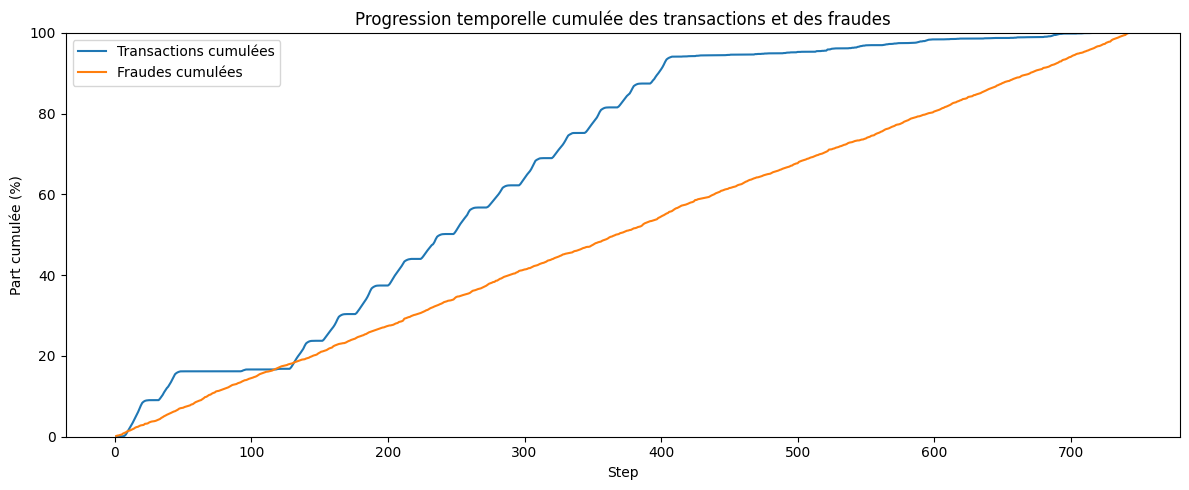

In [66]:
# Visualiser les distributions cumulées
fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    step_profile["step"],
    step_profile[
        "cumulative_transaction_pct"
    ],
    label="Transactions cumulées",
)

ax.plot(
    step_profile["step"],
    step_profile[
        "cumulative_fraud_pct"
    ],
    label="Fraudes cumulées",
)

ax.set_title(
    "Progression temporelle cumulée "
    "des transactions et des fraudes"
)

ax.set_xlabel("Step")
ax.set_ylabel(
    "Part cumulée (%)"
)

ax.set_ylim(0, 100)

ax.legend()

plt.tight_layout()
plt.show()

In [67]:
# Compter les fraudes par type et candidat
candidate_type_results = []

for _, row in candidate_boundaries.iterrows():

    candidate = row["candidate"]

    train_end = int(
        row["train_end_step"]
    )

    val_end = int(
        row["validation_end_step"]
    )

    periods = {
        "Train": (
            1,
            train_end,
        ),
        "Validation": (
            train_end + 1,
            val_end,
        ),
        "Test": (
            val_end + 1,
            max_step,
        ),
    }

    for split_name, (
        start_step,
        end_step,
    ) in periods.items():

        mask = (
            (df["step"] >= start_step)
            & (df["step"] <= end_step)
            & (df["isFraud"] == 1)
        )

        counts = (
            df.loc[mask, "type"]
            .value_counts()
        )

        candidate_type_results.append({
            "candidate": candidate,
            "split": split_name,
            "cash_out_frauds": int(
                counts.get(
                    "CASH_OUT",
                    0,
                )
            ),
            "transfer_frauds": int(
                counts.get(
                    "TRANSFER",
                    0,
                )
            ),
        })

candidate_fraud_type_summary = pd.DataFrame(
    candidate_type_results
)

display(candidate_fraud_type_summary)

,candidate,split,cash_out_frauds,transfer_frauds
0,70_15_15,Train,1831,1812
1,70_15_15,Validation,280,280
2,70_15_15,Test,2005,2005
3,75_12.5_12.5,Train,1882,1863
4,75_12.5_12.5,Validation,319,319
5,75_12.5_12.5,Test,1915,1915
6,80_10_10,Train,1987,1968
7,80_10_10,Validation,247,247
8,80_10_10,Test,1882,1882


### Observation

Les transactions et les fraudes présentent des dynamiques temporelles sensiblement différentes.

La majorité du volume transactionnel est concentrée dans les premières centaines de steps, tandis que les fraudes continuent de s'accumuler tout au long de la chronologie. Ainsi, un ensemble contenant environ 75 % des transactions ne contient qu'environ 46 % des fraudes.

Trois configurations chronologiques ont été comparées : 70/15/15, 75/12,5/12,5 et 80/10/10.

La configuration 75/12,5/12,5 fournit le meilleur compromis. Elle produit :

- un Train de 4 771 387 transactions et 3 745 fraudes ;
- une Validation de 792 406 transactions et 638 fraudes ;
- un Test de 798 827 transactions et 3 830 fraudes.

Les taux de fraude du Train et de la Validation sont proches, respectivement environ 0,0785 % et 0,0805 %, ce qui fournit une base cohérente pour la sélection des modèles.

Le Test présente en revanche un taux de fraude nettement supérieur, autour de 0,4795 %. Ce changement de distribution correspond à la dynamique temporelle réelle du simulateur et n'est pas corrigé artificiellement.

Les deux catégories frauduleuses restent bien représentées. La Validation contient 319 fraudes `CASH_OUT` et 319 fraudes `TRANSFER`, tandis que le Test contient 1 915 observations frauduleuses de chaque type.

### Interprétation

Un split aléatoire masquerait une partie importante de la non-stationnarité temporelle de PaySim.

Le split chronologique retenu impose au modèle d'apprendre sur une période passée relativement stable avant d'être évalué sur une période future présentant un changement important du taux de fraude.

Cette configuration constitue donc une évaluation plus réaliste de la capacité de généralisation temporelle du modèle.

Le nombre de steps diffère fortement entre les ensembles car les frontières sont déterminées à partir du volume cumulé de transactions et non d'intervalles temporels de même longueur.

### Décision

Le split chronologique définitif est :

- **Train : steps 1 à 334** ;
- **Validation : steps 335 à 392** ;
- **Test : steps 393 à 743**.

Les transactions appartenant à un même step restent toujours dans le même ensemble.

Les futures features historiques seront calculées de manière causale. Les transactions de Validation et de Test pourront utiliser l'activité réellement observée dans les steps antérieurs, mais aucune information provenant du futur ou de la cible ne sera utilisée.

In [68]:
# Définir les frontières temporelles
TRAIN_END_STEP = 334
VALIDATION_END_STEP = 392

# Récupérer les steps
step_values = df["step"].to_numpy(copy=False)

# Initialiser les codes du split
split_codes = np.full(
    len(df),
    2,
    dtype="int8",
)

# Affecter le Train
split_codes[
    step_values <= TRAIN_END_STEP
] = 0

# Affecter la Validation
validation_mask = (
    (step_values > TRAIN_END_STEP)
    & (step_values <= VALIDATION_END_STEP)
)

split_codes[validation_mask] = 1

# Créer la variable catégorielle
df["split"] = pd.Categorical.from_codes(
    split_codes,
    categories=[
        "Train",
        "Validation",
        "Test",
    ],
    ordered=True,
)

del split_codes
del validation_mask
gc.collect()

258

In [69]:
# Résumer le split définitif
final_split_summary = (
    df.groupby(
        "split",
        observed=True,
    )
    .agg(
        step_start=("step", "min"),
        step_end=("step", "max"),
        transactions=("isFraud", "size"),
        frauds=("isFraud", "sum"),
    )
    .reset_index()
)

final_split_summary["transaction_pct"] = (
    final_split_summary["transactions"]
    / len(df)
    * 100
)

final_split_summary["fraud_rate_pct"] = (
    final_split_summary["frauds"]
    / final_split_summary["transactions"]
    * 100
)

final_split_summary["fraud_share_pct"] = (
    final_split_summary["frauds"]
    / df["isFraud"].sum()
    * 100
)

display(final_split_summary)

,split,step_start,step_end,transactions,frauds,transaction_pct,fraud_rate_pct,fraud_share_pct
0,Train,1,334,4771387,3745,74.9909,0.0785,45.5984
1,Validation,335,392,792406,638,12.4541,0.0805,7.7682
2,Test,393,743,798827,3830,12.5550,0.4795,46.6334


In [70]:
# Vérifier les frontières temporelles
assert (
    df.loc[
        df["split"] == "Train",
        "step",
    ].max()
    <
    df.loc[
        df["split"] == "Validation",
        "step",
    ].min()
)

assert (
    df.loc[
        df["split"] == "Validation",
        "step",
    ].max()
    <
    df.loc[
        df["split"] == "Test",
        "step",
    ].min()
)

# Vérifier qu'un step n'appartient qu'à un split
max_splits_per_step = (
    df.groupby(
        "step",
        observed=True,
    )["split"]
    .nunique()
    .max()
)

assert max_splits_per_step == 1

# Vérifier les volumes
assert len(df) == 6_362_620
assert int(df["isFraud"].sum()) == 8_213

print("Split chronologique validé.")

Split chronologique validé.


## 9. Features comportementales historiques

Les features comportementales décrivent l'activité d'un compte avant la transaction courante.

Contrairement aux transformations précédentes, elles nécessitent la consultation d'un historique transactionnel. Leur construction doit donc respecter strictement la causalité.

Pour une transaction appartenant au step \(t\), seules les transactions appartenant à des steps strictement inférieurs à \(t\) sont considérées comme historiques.

Avant de calculer les cumuls, il est nécessaire de vérifier si un même compte peut intervenir plusieurs fois au sein d'un même step. Si cette situation existe, une simple opération `cumcount`, `cumsum` ou `shift` suivant l'ordre des lignes introduirait une fuite intra-step.

Un diagnostic est donc réalisé séparément pour les émetteurs et les destinataires avant de choisir l'implémentation causale la plus efficace.

In [71]:
# Identifier les répétitions source-step
origin_step_duplicate_mask = df.duplicated(
    subset=[
        "nameOrig",
        "step",
    ],
    keep=False,
)

origin_same_step_rows = int(
    origin_step_duplicate_mask.sum()
)

origin_same_step_pct = (
    origin_same_step_rows
    / len(df)
    * 100
)

print(
    "Lignes appartenant à un "
    "origin-step répété :",
    f"{origin_same_step_rows:,}",
)

print(
    "Part du dataset :",
    f"{origin_same_step_pct:.6f} %",
)

Lignes appartenant à un origin-step répété : 94
Part du dataset : 0.001477 %


In [72]:
# Étudier les groupes source-step répétés
origin_duplicate_groups = (
    df.loc[
        origin_step_duplicate_mask,
        [
            "nameOrig",
            "step",
        ],
    ]
    .groupby(
        [
            "nameOrig",
            "step",
        ],
        sort=False,
    )
    .size()
)

print(
    "Nombre de groupes origin-step répétés :",
    f"{len(origin_duplicate_groups):,}",
)

print(
    "Maximum de transactions pour "
    "un même origin-step :",
    int(origin_duplicate_groups.max())
    if len(origin_duplicate_groups) > 0
    else 1,
)

Nombre de groupes origin-step répétés : 47
Maximum de transactions pour un même origin-step : 2


In [73]:
# Libérer les objets temporaires
del origin_step_duplicate_mask
del origin_duplicate_groups
gc.collect()

160

In [74]:
# Identifier les répétitions destination-step
destination_step_duplicate_mask = df.duplicated(
    subset=[
        "nameDest",
        "step",
    ],
    keep=False,
)

destination_same_step_rows = int(
    destination_step_duplicate_mask.sum()
)

destination_same_step_pct = (
    destination_same_step_rows
    / len(df)
    * 100
)

print(
    "Lignes appartenant à un "
    "destination-step répété :",
    f"{destination_same_step_rows:,}",
)

print(
    "Part du dataset :",
    f"{destination_same_step_pct:.6f} %",
)

Lignes appartenant à un destination-step répété : 565,581
Part du dataset : 8.889121 %


In [75]:
# Étudier les groupes destination-step répétés
destination_duplicate_groups = (
    df.loc[
        destination_step_duplicate_mask,
        [
            "nameDest",
            "step",
        ],
    ]
    .groupby(
        [
            "nameDest",
            "step",
        ],
        sort=False,
    )
    .size()
)

print(
    "Nombre de groupes destination-step répétés :",
    f"{len(destination_duplicate_groups):,}",
)

print(
    "Maximum de transactions pour "
    "un même destination-step :",
    int(destination_duplicate_groups.max())
    if len(destination_duplicate_groups) > 0
    else 1,
)

Nombre de groupes destination-step répétés : 249,148
Maximum de transactions pour un même destination-step : 32


In [76]:
# Libérer les objets temporaires
del destination_step_duplicate_mask
del destination_duplicate_groups
gc.collect()

9

In [77]:
# Résumer les répétitions intra-step
same_step_summary = pd.DataFrame({
    "entity": [
        "origin",
        "destination",
    ],
    "repeated_rows": [
        origin_same_step_rows,
        destination_same_step_rows,
    ],
    "percentage": [
        origin_same_step_pct,
        destination_same_step_pct,
    ],
})

display(same_step_summary)

,entity,repeated_rows,percentage
0,origin,94,0.0015
1,destination,565581,8.8891


### 9.1 Stratégie de calcul causal

Le diagnostic des répétitions intra-step montre une forte asymétrie entre les deux côtés de la transaction.

Les émetteurs sont presque toujours uniques à l'intérieur d'un step : seulement 94 lignes appartiennent à un groupe `source-step` répété, soit environ 0,0015 % du dataset.

À l'inverse, 565 581 transactions appartiennent à un groupe `destination-step` répété, soit environ 8,89 % du dataset. Une même destination peut recevoir jusqu'à 32 transactions au cours d'un même step.

Une simple utilisation de `cumcount`, `cumsum` ou `shift` suivant l'ordre des lignes ne garantirait donc pas la causalité, particulièrement côté destination.

Pour les cumuls, la stratégie suivante est utilisée :

\[
Historical(entity,t)
=
Cumulative(entity,t)
-
Cumulative(entity,t\_current)
\]

Cette différence élimine toutes les transactions appartenant au step courant et conserve uniquement les événements de steps strictement antérieurs.

Côté source, la très faible récurrence permet en complément de limiter certains calculs aux seuls comptes apparaissant plusieurs fois, afin de réduire le coût mémoire.

In [81]:
# Identifier les sources récurrentes
origin_recurrent_mask = df.duplicated(
    subset="nameOrig",
    keep=False,
)

origin_recurrent_rows = int(
    origin_recurrent_mask.sum()
)

origin_recurrent_pct = (
    origin_recurrent_rows
    / len(df)
    * 100
)

print(
    "Lignes avec une source récurrente :",
    f"{origin_recurrent_rows:,}",
)

print(
    "Part du dataset :",
    f"{origin_recurrent_pct:.6f} %",
)

Lignes avec une source récurrente : 18,611
Part du dataset : 0.292505 %


In [82]:
# Extraire les sources récurrentes
origin_history = df.loc[
    origin_recurrent_mask,
    [
        "nameOrig",
        "nameDest",
        "step",
        "amount",
    ],
].copy()

print(
    "Dimensions du sous-ensemble source :",
    origin_history.shape,
)

Dimensions du sous-ensemble source : (18611, 4)


In [83]:
# Initialiser les features source
df["orig_prev_transactions"] = np.zeros(
    len(df),
    dtype="int16",
)

df["orig_prev_volume"] = np.zeros(
    len(df),
    dtype="float32",
)

df["orig_prev_mean_amount"] = np.full(
    len(df),
    np.nan,
    dtype="float32",
)

df["orig_time_since_last"] = np.full(
    len(df),
    np.nan,
    dtype="float32",
)

In [84]:
# Compter les transactions précédentes
origin_total_before = (
    origin_history
    .groupby(
        "nameOrig",
        sort=False,
    )
    .cumcount()
)

origin_same_step_before = (
    origin_history
    .groupby(
        [
            "nameOrig",
            "step",
        ],
        sort=False,
    )
    .cumcount()
)

origin_history[
    "orig_prev_transactions"
] = (
    origin_total_before
    - origin_same_step_before
).astype("int16")

del origin_total_before
del origin_same_step_before
gc.collect()

406

In [85]:
# Calculer le volume historique source
origin_total_volume = (
    origin_history
    .groupby(
        "nameOrig",
        sort=False,
    )["amount"]
    .cumsum()
)

origin_step_volume = (
    origin_history
    .groupby(
        [
            "nameOrig",
            "step",
        ],
        sort=False,
    )["amount"]
    .cumsum()
)

origin_history[
    "orig_prev_volume"
] = (
    origin_total_volume
    - origin_step_volume
).astype("float32")

del origin_total_volume
del origin_step_volume
gc.collect()

0

In [86]:
# Calculer le montant moyen historique
origin_counts = (
    origin_history[
        "orig_prev_transactions"
    ].to_numpy()
)

origin_volumes = (
    origin_history[
        "orig_prev_volume"
    ].to_numpy()
)

origin_mean = np.divide(
    origin_volumes,
    origin_counts,
    out=np.full(
        len(origin_history),
        np.nan,
        dtype="float32",
    ),
    where=origin_counts > 0,
)

origin_history[
    "orig_prev_mean_amount"
] = origin_mean

del origin_counts
del origin_volumes
del origin_mean
gc.collect()

0

In [87]:
# Récupérer le step précédent
origin_prev_step = (
    origin_history
    .groupby(
        "nameOrig",
        sort=False,
    )["step"]
    .shift()
)

# Ignorer les transactions du même step
origin_prev_step = origin_prev_step.where(
    origin_prev_step
    < origin_history["step"]
)

# Propager le dernier step strictement antérieur
origin_prev_step = (
    origin_prev_step
    .groupby(
        origin_history["nameOrig"],
        sort=False,
    )
    .ffill()
)

# Calculer le temps depuis la dernière transaction
origin_history[
    "orig_time_since_last"
] = (
    origin_history["step"]
    - origin_prev_step
).astype("float32")

del origin_prev_step
gc.collect()

0

In [88]:
# Reporter les features source
origin_history_features = [
    "orig_prev_transactions",
    "orig_prev_volume",
    "orig_prev_mean_amount",
    "orig_time_since_last",
]

df.loc[
    origin_history.index,
    origin_history_features,
] = origin_history[
    origin_history_features
]

del origin_history
del origin_recurrent_mask
gc.collect()

0

In [89]:
# Compter les transactions précédentes destination
dest_total_before = (
    df.groupby(
        "nameDest",
        sort=False,
    )
    .cumcount()
)

dest_same_step_before = (
    df.groupby(
        [
            "nameDest",
            "step",
        ],
        sort=False,
    )
    .cumcount()
)

df["dest_prev_transactions"] = (
    dest_total_before
    - dest_same_step_before
).astype("int16")

del dest_total_before
del dest_same_step_before
gc.collect()

0

In [90]:
# Calculer le volume historique destination
dest_total_volume = (
    df.groupby(
        "nameDest",
        sort=False,
    )["amount"]
    .cumsum()
)

dest_step_volume = (
    df.groupby(
        [
            "nameDest",
            "step",
        ],
        sort=False,
    )["amount"]
    .cumsum()
)

df["dest_prev_volume"] = (
    dest_total_volume
    - dest_step_volume
).astype("float32")

del dest_total_volume
del dest_step_volume
gc.collect()

0

In [91]:
# Calculer le montant moyen historique destination
dest_counts = (
    df["dest_prev_transactions"]
    .to_numpy()
)

dest_volumes = (
    df["dest_prev_volume"]
    .to_numpy()
)

dest_mean = np.divide(
    dest_volumes,
    dest_counts,
    out=np.full(
        len(df),
        np.nan,
        dtype="float32",
    ),
    where=dest_counts > 0,
)

df["dest_prev_mean_amount"] = dest_mean

del dest_counts
del dest_volumes
del dest_mean
gc.collect()

0

In [92]:
# Récupérer le step précédent destination
dest_prev_step = (
    df.groupby(
        "nameDest",
        sort=False,
    )["step"]
    .shift()
)

# Retirer les observations du même step
dest_prev_step = dest_prev_step.where(
    dest_prev_step < df["step"]
)

# Propager le dernier step strictement antérieur
dest_prev_step = (
    dest_prev_step
    .groupby(
        df["nameDest"],
        sort=False,
    )
    .ffill()
)

# Calculer le temps depuis la dernière réception
df["dest_time_since_last"] = (
    df["step"]
    - dest_prev_step
).astype("float32")

del dest_prev_step
gc.collect()

0

In [93]:
# Identifier la première occurrence de chaque paire
new_pair = ~df.duplicated(
    subset=[
        "nameOrig",
        "nameDest",
    ],
    keep="first",
)

new_pair = new_pair.astype("int8")

In [94]:
# Compter les nouvelles sources cumulées
dest_unique_total = (
    new_pair
    .groupby(
        df["nameDest"],
        sort=False,
    )
    .cumsum()
)

dest_unique_step = (
    new_pair
    .groupby(
        [
            df["nameDest"],
            df["step"],
        ],
        sort=False,
    )
    .cumsum()
)

df["dest_prev_unique_sources"] = (
    dest_unique_total
    - dest_unique_step
).astype("int16")

del dest_unique_total
del dest_unique_step
gc.collect()

0

In [95]:
# Identifier les sources récurrentes
origin_recurrent_mask = df.duplicated(
    subset="nameOrig",
    keep=False,
)

# Initialiser la feature
df["orig_prev_unique_destinations"] = np.zeros(
    len(df),
    dtype="int16",
)

# Extraire les lignes récurrentes
origin_unique_history = df.loc[
    origin_recurrent_mask,
    [
        "nameOrig",
        "nameDest",
        "step",
    ],
].copy()

# Identifier les nouvelles relations
origin_new_pair = ~origin_unique_history.duplicated(
    subset=[
        "nameOrig",
        "nameDest",
    ],
    keep="first",
)

origin_new_pair = origin_new_pair.astype(
    "int8"
)

In [96]:
# Compter les destinations uniques précédentes
origin_unique_total = (
    origin_new_pair
    .groupby(
        origin_unique_history[
            "nameOrig"
        ],
        sort=False,
    )
    .cumsum()
)

origin_unique_step = (
    origin_new_pair
    .groupby(
        [
            origin_unique_history[
                "nameOrig"
            ],
            origin_unique_history[
                "step"
            ],
        ],
        sort=False,
    )
    .cumsum()
)

origin_unique_history[
    "orig_prev_unique_destinations"
] = (
    origin_unique_total
    - origin_unique_step
).astype("int16")

# Reporter les résultats
df.loc[
    origin_unique_history.index,
    "orig_prev_unique_destinations",
] = origin_unique_history[
    "orig_prev_unique_destinations"
]

del origin_unique_total
del origin_unique_step
del origin_unique_history
del origin_new_pair
del origin_recurrent_mask
del new_pair
gc.collect()

0

In [97]:
# Sélectionner les features comportementales
behavioral_features = [
    "orig_prev_transactions",
    "orig_prev_volume",
    "orig_prev_mean_amount",
    "orig_prev_unique_destinations",
    "orig_time_since_last",
    "dest_prev_transactions",
    "dest_prev_volume",
    "dest_prev_mean_amount",
    "dest_prev_unique_sources",
    "dest_time_since_last",
]

behavioral_feature_control = pd.DataFrame({
    "dtype": df[
        behavioral_features
    ].dtypes.astype(str),

    "missing": df[
        behavioral_features
    ].isna().sum(),

    "minimum": [
        df[col].min()
        for col in behavioral_features
    ],

    "maximum": [
        df[col].max()
        for col in behavioral_features
    ],
})

display(
    behavioral_feature_control
)

,dtype,missing,minimum,maximum
orig_prev_transactions,int16,0,0.0000,2.0000
orig_prev_volume,float32,0,0.0000,"46,211,920.0000"
orig_prev_mean_amount,float32,6353354,0.5200,"46,211,920.0000"
orig_prev_unique_destinations,int16,0,0.0000,2.0000
orig_time_since_last,float32,6353354,1.0000,704.0000
dest_prev_transactions,int16,0,0.0000,112.0000
dest_prev_volume,float32,0,0.0000,"357,277,440.0000"
dest_prev_mean_amount,float32,2769903,0.0000,"39,920,572.0000"
dest_prev_unique_sources,int16,0,0.0000,112.0000
dest_time_since_last,float32,2769903,1.0000,681.0000


In [98]:
# Identifier les destination-step répétés
dest_repeat_mask = df.duplicated(
    subset=[
        "nameDest",
        "step",
    ],
    keep=False,
)

dest_causal_check = (
    df.loc[
        dest_repeat_mask,
        [
            "nameDest",
            "step",
            "dest_prev_transactions",
            "dest_prev_volume",
            "dest_prev_mean_amount",
            "dest_prev_unique_sources",
            "dest_time_since_last",
        ],
    ]
    .groupby(
        [
            "nameDest",
            "step",
        ],
        sort=False,
    )
    .nunique(
        dropna=False
    )
    .max()
)

display(dest_causal_check)

del dest_repeat_mask
gc.collect()

dest_prev_transactions      1
dest_prev_volume            2
dest_prev_mean_amount       2
dest_prev_unique_sources    1
dest_time_since_last        1
dtype: int64

160

In [99]:
# Identifier les origin-step répétés
origin_repeat_mask = df.duplicated(
    subset=[
        "nameOrig",
        "step",
    ],
    keep=False,
)

origin_causal_check = (
    df.loc[
        origin_repeat_mask,
        [
            "nameOrig",
            "step",
            "orig_prev_transactions",
            "orig_prev_volume",
            "orig_prev_mean_amount",
            "orig_prev_unique_destinations",
            "orig_time_since_last",
        ],
    ]
    .groupby(
        [
            "nameOrig",
            "step",
        ],
        sort=False,
    )
    .nunique(
        dropna=False
    )
    .max()
)

display(origin_causal_check)

del origin_repeat_mask
gc.collect()

orig_prev_transactions           1
orig_prev_volume                 1
orig_prev_mean_amount            1
orig_prev_unique_destinations    1
orig_time_since_last             1
dtype: int64

169

In [100]:
# Vérifier le premier step
step_one_control = pd.DataFrame({
    "feature": behavioral_features,
    "non_zero_or_available": [
        (
            df.loc[
                df["step"] == 1,
                col,
            ]
            .fillna(0)
            .ne(0)
            .sum()
        )
        for col in behavioral_features
    ],
})

display(step_one_control)

,feature,non_zero_or_available
0,orig_prev_transactions,0
1,orig_prev_volume,0
2,orig_prev_mean_amount,0
3,orig_prev_unique_destinations,0
4,orig_time_since_last,0
5,dest_prev_transactions,0
6,dest_prev_volume,0
7,dest_prev_mean_amount,0
8,dest_prev_unique_sources,0
9,dest_time_since_last,0


In [101]:
# Comparer les principales features
behavioral_comparison_features = [
    "orig_prev_transactions",
    "orig_prev_volume",
    "orig_time_since_last",
    "dest_prev_transactions",
    "dest_prev_volume",
    "dest_prev_unique_sources",
    "dest_time_since_last",
]

behavioral_comparison = (
    df.groupby(
        "isFraud",
        observed=True,
    )[
        behavioral_comparison_features
    ]
    .median()
    .T
)

behavioral_comparison.columns = [
    "legitimate",
    "fraud",
]

display(
    behavioral_comparison
)

,legitimate,fraud
orig_prev_transactions,0.0000,0.0000
orig_prev_volume,0.0000,0.0000
orig_time_since_last,140.0000,241.5000
dest_prev_transactions,1.0000,0.0000
dest_prev_volume,"207,513.3750",0.0000
dest_prev_unique_sources,1.0000,0.0000
dest_time_since_last,16.0000,50.0000


In [102]:
# Mesurer l'absence d'historique
history_availability = pd.DataFrame({
    "condition": [
        "No previous origin transaction",
        "No previous destination transaction",
    ],
    "count": [
        (
            df["orig_prev_transactions"]
            == 0
        ).sum(),
        (
            df["dest_prev_transactions"]
            == 0
        ).sum(),
    ],
})

history_availability["percentage"] = (
    history_availability["count"]
    / len(df)
    * 100
)

display(
    history_availability
)

,condition,count,percentage
0,No previous origin transaction,6353354,99.8544
1,No previous destination transaction,2769903,43.5340


In [103]:
# Vérifier la mémoire
memory_behavioral_mb = (
    df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

memory_behavioral_gb = (
    memory_behavioral_mb / 1024
)

behavioral_added_mb = (
    memory_behavioral_mb
    - memory_temporal_mb
)

print(
    f"Mémoire actuelle : "
    f"{memory_behavioral_mb:,.2f} MB"
)

print(
    f"Mémoire actuelle : "
    f"{memory_behavioral_gb:,.2f} GB"
)

print(
    "Mémoire ajoutée par la Section 9 : "
    f"{behavioral_added_mb:,.2f} MB"
)

Mémoire actuelle : 988.84 MB
Mémoire actuelle : 0.97 GB
Mémoire ajoutée par la Section 9 : 200.24 MB


In [104]:
# Identifier les destination-step répétés
dest_repeat_mask = df.duplicated(
    subset=[
        "nameDest",
        "step",
    ],
    keep=False,
)

# Extraire uniquement les lignes concernées
dest_repeat_check = df.loc[
    dest_repeat_mask,
    [
        "nameDest",
        "step",
        "dest_prev_transactions",
        "dest_prev_volume",
        "dest_prev_mean_amount",
        "dest_prev_unique_sources",
        "dest_time_since_last",
    ],
].copy()

print(
    "Lignes contrôlées :",
    f"{len(dest_repeat_check):,}",
)

Lignes contrôlées : 565,581


In [105]:
# Mesurer les variations intra-step
dest_numeric_spread = (
    dest_repeat_check
    .groupby(
        [
            "nameDest",
            "step",
        ],
        sort=False,
    )
    .agg(
        volume_min=(
            "dest_prev_volume",
            "min",
        ),
        volume_max=(
            "dest_prev_volume",
            "max",
        ),
        mean_min=(
            "dest_prev_mean_amount",
            "min",
        ),
        mean_max=(
            "dest_prev_mean_amount",
            "max",
        ),
    )
)

dest_numeric_spread[
    "volume_spread"
] = (
    dest_numeric_spread["volume_max"]
    - dest_numeric_spread["volume_min"]
)

dest_numeric_spread[
    "mean_spread"
] = (
    dest_numeric_spread["mean_max"]
    - dest_numeric_spread["mean_min"]
)

print(
    "Écart maximal volume :",
    dest_numeric_spread[
        "volume_spread"
    ].max(),
)

print(
    "Écart maximal moyenne :",
    dest_numeric_spread[
        "mean_spread"
    ].max(),
)

Écart maximal volume : 1.0
Écart maximal moyenne : 0.125


In [106]:
# Compter les groupes présentant un écart
volume_diff_groups = int(
    (
        dest_numeric_spread[
            "volume_spread"
        ] > 0
    ).sum()
)

mean_diff_groups = int(
    (
        dest_numeric_spread[
            "mean_spread"
        ] > 0
    ).sum()
)

print(
    "Groupes avec différence de volume :",
    f"{volume_diff_groups:,}",
)

print(
    "Groupes avec différence de moyenne :",
    f"{mean_diff_groups:,}",
)

Groupes avec différence de volume : 55
Groupes avec différence de moyenne : 47


In [107]:
# Sélectionner le premier step
step_one_mask = df["step"] == 1

# Vérifier les features nulles
step_one_zero_features = [
    "orig_prev_transactions",
    "orig_prev_volume",
    "orig_prev_unique_destinations",
    "dest_prev_transactions",
    "dest_prev_volume",
    "dest_prev_unique_sources",
]

step_one_nan_features = [
    "orig_prev_mean_amount",
    "orig_time_since_last",
    "dest_prev_mean_amount",
    "dest_time_since_last",
]

step_one_strict_control = pd.DataFrame({
    "feature": (
        step_one_zero_features
        + step_one_nan_features
    ),
    "expected": (
        ["zero"]
        * len(step_one_zero_features)
        + ["NaN"]
        * len(step_one_nan_features)
    ),
    "valid": [
        bool(
            (
                df.loc[
                    step_one_mask,
                    col,
                ] == 0
            ).all()
        )
        for col in step_one_zero_features
    ]
    + [
        bool(
            df.loc[
                step_one_mask,
                col,
            ].isna().all()
        )
        for col in step_one_nan_features
    ],
})

display(step_one_strict_control)

,feature,expected,valid
0,orig_prev_transactions,zero,True
1,orig_prev_volume,zero,True
2,orig_prev_unique_destinations,zero,True
3,dest_prev_transactions,zero,True
4,dest_prev_volume,zero,True
5,dest_prev_unique_sources,zero,True
6,orig_prev_mean_amount,NaN,True
7,orig_time_since_last,NaN,True
8,dest_prev_mean_amount,NaN,True
9,dest_time_since_last,NaN,True


In [108]:
# Mesurer l'absence d'historique source par classe
origin_no_history_by_class = (
    df["orig_prev_transactions"]
    .eq(0)
    .groupby(
        df["isFraud"],
        observed=True,
    )
    .mean()
    * 100
)

# Mesurer l'absence d'historique destination par classe
dest_no_history_by_class = (
    df["dest_prev_transactions"]
    .eq(0)
    .groupby(
        df["isFraud"],
        observed=True,
    )
    .mean()
    * 100
)

history_by_class = pd.DataFrame({
    "origin_no_history_pct":
        origin_no_history_by_class,

    "destination_no_history_pct":
        dest_no_history_by_class,
})

history_by_class.index = [
    "Legitimate",
    "Fraud",
]

display(history_by_class)

,origin_no_history_pct,destination_no_history_pct
Legitimate,99.8545,43.5085
Fraud,99.7808,63.2656


In [109]:
# Identifier les destination-step répétés
dest_repeat_mask = df.duplicated(
    subset=[
        "nameDest",
        "step",
    ],
    keep=False,
)

# Extraire les valeurs historiques répétées
dest_repeat_history = df.loc[
    dest_repeat_mask,
    [
        "nameDest",
        "step",
        "dest_prev_transactions",
        "dest_prev_volume",
    ],
].copy()

# Récupérer le même historique pour tout le step
dest_repeat_history[
    "dest_prev_volume"
] = (
    dest_repeat_history
    .groupby(
        [
            "nameDest",
            "step",
        ],
        sort=False,
    )["dest_prev_volume"]
    .transform("first")
)

# Reporter les volumes corrigés
df.loc[
    dest_repeat_history.index,
    "dest_prev_volume",
] = dest_repeat_history[
    "dest_prev_volume"
]

In [110]:
# Récupérer les compteurs
repeat_counts = (
    dest_repeat_history[
        "dest_prev_transactions"
    ].to_numpy()
)

repeat_volumes = (
    dest_repeat_history[
        "dest_prev_volume"
    ].to_numpy()
)

# Recalculer la moyenne
repeat_mean = np.divide(
    repeat_volumes,
    repeat_counts,
    out=np.full(
        len(dest_repeat_history),
        np.nan,
        dtype="float32",
    ),
    where=repeat_counts > 0,
)

# Reporter la moyenne corrigée
df.loc[
    dest_repeat_history.index,
    "dest_prev_mean_amount",
] = repeat_mean

del repeat_counts
del repeat_volumes
del repeat_mean
del dest_repeat_history
gc.collect()

180

In [111]:
# Vérifier la causalité destination
dest_repeat_mask = df.duplicated(
    subset=[
        "nameDest",
        "step",
    ],
    keep=False,
)

dest_causal_check = (
    df.loc[
        dest_repeat_mask,
        [
            "nameDest",
            "step",
            "dest_prev_transactions",
            "dest_prev_volume",
            "dest_prev_mean_amount",
            "dest_prev_unique_sources",
            "dest_time_since_last",
        ],
    ]
    .groupby(
        [
            "nameDest",
            "step",
        ],
        sort=False,
    )
    .nunique(
        dropna=False
    )
    .max()
)

display(dest_causal_check)

del dest_repeat_mask
gc.collect()

dest_prev_transactions      1
dest_prev_volume            1
dest_prev_mean_amount       1
dest_prev_unique_sources    1
dest_time_since_last        1
dtype: int64

0

### Observation

Les features comportementales historiques confirment la forte asymétrie entre les comptes sources et destinations observée lors de l'EDA.

Environ 99,85 % des transactions ne disposent d'aucun historique côté source. Les compteurs et volumes historiques de l'émetteur sont donc nuls pour la très grande majorité des observations, aussi bien légitimes que frauduleuses.

La situation est différente côté destination. Environ 43,53 % des transactions légitimes ne disposent d'aucun historique de destination, contre 63,27 % des transactions frauduleuses.

Les médianes confirment cette différence : la transaction légitime typique possède déjà une transaction et une source distincte dans l'historique de la destination, alors que la transaction frauduleuse typique arrive sur une destination sans historique antérieur.

Les contrôles du premier step confirment également la causalité du calcul : toutes les variables cumulatives sont nulles au début de la chronologie, tandis que les moyennes et temps depuis la dernière activité sont correctement non définis.

Le contrôle intra-step côté source montre que toutes les transactions contemporaines partagent exactement le même historique.

Côté destination, de très faibles différences numériques ont initialement été détectées pour les volumes et moyennes historiques dans un nombre limité de groupes. L'écart maximal observé était de 1 unité sur le volume et 0,125 sur la moyenne. Ces différences provenaient de la précision des opérations cumulatives en virgule flottante et non d'une utilisation d'informations futures. Les valeurs ont été homogénéisées au niveau `destination-step` afin que toutes les transactions contemporaines utilisent strictement le même état historique.

### Interprétation

L'historique de l'émetteur possède une couverture extrêmement limitée dans PaySim en raison de la très faible récurrence des comptes sources.

À l'inverse, l'historique de la destination constitue une source d'information comportementale beaucoup plus exploitable. Les fraudes sont notamment plus souvent dirigées vers des destinations qui n'avaient encore reçu aucune transaction antérieure.

Ce comportement peut être pertinent pour la détection de fraude et pour la future représentation graphe, où il décrit la maturité historique du nœud destination au moment de la transaction.

### Décision

Les dix features comportementales historiques sont conservées.

Les variables côté destination seront considérées comme particulièrement importantes pour les futurs modèles :

- `dest_prev_transactions` ;
- `dest_prev_volume` ;
- `dest_prev_mean_amount` ;
- `dest_prev_unique_sources` ;
- `dest_time_since_last`.

Les features source sont également conservées afin de maintenir une représentation symétrique et compatible avec le futur Graph Learning, même si leur couverture historique est très faible dans PaySim.

Toutes les features historiques respectent la convention temporelle selon laquelle seules les transactions appartenant à des steps strictement antérieurs sont disponibles.

## 10. Features d'activité récente

Les statistiques cumulatives décrivent l'ensemble de l'historique disponible, mais elles ne distinguent pas nécessairement une activité ancienne d'une activité récente.

Dans un système transactionnel, la récence peut constituer un signal comportemental important. Une destination ayant reçu une transaction quelques steps auparavant ne présente pas le même profil qu'une destination inactive depuis une longue période.

La construction exacte de compteurs et volumes glissants sur plusieurs fenêtres temporelles serait cependant coûteuse sur plus de six millions de transactions et plusieurs millions d'identifiants.

Une approche plus légère est donc privilégiée dans ce notebook : exploiter directement le temps depuis la dernière activité déjà calculé de manière causale.

Une fenêtre de 24 steps est étudiée, car elle correspond à un cycle complet dans la structure temporelle de PaySim.

Cette fenêtre reste spécifique à l'échelle temporelle du simulateur et sera donc interprétée avec prudence.

In [112]:
# Identifier une activité source récente
df["orig_active_last_24"] = (
    df["orig_time_since_last"].le(24)
).astype("int8")

In [114]:
# Identifier une activité destination récente
df["dest_active_last_24"] = (
    df["dest_time_since_last"].le(24)
).astype("int8")

In [115]:
# Sélectionner les features récentes
recent_activity_features = [
    "orig_active_last_24",
    "dest_active_last_24",
]

recent_activity_control = pd.DataFrame({
    "dtype": df[
        recent_activity_features
    ].dtypes.astype(str),

    "missing": df[
        recent_activity_features
    ].isna().sum(),

    "minimum": [
        df[col].min()
        for col in recent_activity_features
    ],

    "maximum": [
        df[col].max()
        for col in recent_activity_features
    ],

    "count_active": [
        int(df[col].sum())
        for col in recent_activity_features
    ],
})

recent_activity_control[
    "active_pct"
] = (
    recent_activity_control[
        "count_active"
    ]
    / len(df)
    * 100
)

display(recent_activity_control)

,dtype,missing,minimum,maximum,count_active,active_pct
orig_active_last_24,int8,0,0,1,1105,0.0174
dest_active_last_24,int8,0,0,1,2354216,37.0007


In [116]:
# Comparer l'activité récente selon la cible
recent_activity_by_class = (
    df.groupby(
        "isFraud",
        observed=True,
    )[recent_activity_features]
    .mean()
    .mul(100)
    .T
)

recent_activity_by_class.columns = [
    "legitimate_pct",
    "fraud_pct",
]

recent_activity_by_class[
    "difference_points"
] = (
    recent_activity_by_class[
        "fraud_pct"
    ]
    - recent_activity_by_class[
        "legitimate_pct"
    ]
)

display(recent_activity_by_class)

,legitimate_pct,fraud_pct,difference_points
orig_active_last_24,0.0174,0.0244,0.0070
dest_active_last_24,37.0323,12.5533,-24.4791


In [117]:
# Sélectionner les destinations avec historique
dest_history_mask = (
    df["dest_prev_transactions"] > 0
)

dest_recent_given_history = (
    df.loc[
        dest_history_mask,
    ]
    .groupby(
        "isFraud",
        observed=True,
    )["dest_active_last_24"]
    .agg(
        [
            "count",
            "mean",
        ]
    )
)

dest_recent_given_history[
    "recent_pct"
] = (
    dest_recent_given_history[
        "mean"
    ]
    * 100
)

display(
    dest_recent_given_history[
        [
            "count",
            "recent_pct",
        ]
    ]
)

,count,recent_pct
isFraud,,
0,3589700,65.5538
1,3017,34.1730


In [118]:
# Comparer la récence destination avec historique
dest_recency_quantiles = (
    df.loc[
        dest_history_mask
    ]
    .groupby(
        "isFraud",
        observed=True,
    )["dest_time_since_last"]
    .quantile(
        [
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
        ]
    )
)

display(dest_recency_quantiles)

isFraud        
0        0.2500     3.0000
         0.5000    16.0000
         0.7500    38.0000
         0.9000    85.0000
         0.9500   122.0000
1        0.2500    15.0000
         0.5000    50.0000
         0.7500   152.0000
         0.9000   277.0000
         0.9500   331.0000
Name: dest_time_since_last, dtype: float64

### Limite des fenêtres glissantes exactes

Des variables telles que le nombre de transactions ou le volume reçu au cours des 24 derniers steps pourraient théoriquement enrichir la représentation comportementale.

Cependant, leur calcul exact nécessite de maintenir une fenêtre temporelle pour plusieurs millions de comptes et de couples compte-step. Une implémentation naïve avec `groupby().rolling()` créerait des structures intermédiaires très volumineuses sur PaySim.

Afin de préserver un pipeline reproductible et raisonnablement efficace en mémoire, ces agrégations ne sont pas calculées dans le DataFrame principal à ce stade.

La récence est représentée par `time_since_last` et par les indicateurs d'activité sur les 24 derniers steps. Des compteurs et volumes glissants pourront être ajoutés ultérieurement dans un pipeline incrémental ou directement dans le traitement des événements du graphe dynamique, où l'état des nœuds sera mis à jour chronologiquement.

In [120]:
# Documenter les features récentes
recent_feature_metadata = pd.DataFrame({
    "feature": [
        "orig_active_last_24",
        "dest_active_last_24",
    ],
    "uses_current_transaction": [
        False,
        False,
    ],
    "uses_strict_past": [
        True,
        True,
    ],
    "uses_target": [
        False,
        False,
    ],
    "temporal_leakage_risk": [
        "No",
        "No",
    ],
    "paysim_sensitive": [
        True,
        True,
    ],
})

display(recent_feature_metadata)

,feature,uses_current_transaction,uses_strict_past,uses_target,temporal_leakage_risk,paysim_sensitive
0,orig_active_last_24,False,True,False,No,True
1,dest_active_last_24,False,True,False,No,True


In [121]:
# Ajouter les features récentes
for feature in recent_activity_features:
    if feature not in paysim_sensitive_candidates:
        paysim_sensitive_candidates.append(
            feature
        )

print(
    "PaySim-sensitive candidates :",
    len(
        paysim_sensitive_candidates
    ),
)

PaySim-sensitive candidates : 12


In [122]:
# Vérifier la mémoire
memory_recent_mb = (
    df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

memory_recent_gb = (
    memory_recent_mb / 1024
)

recent_added_mb = (
    memory_recent_mb
    - memory_behavioral_mb
)

print(
    f"Mémoire actuelle : "
    f"{memory_recent_mb:,.2f} MB"
)

print(
    f"Mémoire actuelle : "
    f"{memory_recent_gb:,.2f} GB"
)

print(
    "Mémoire ajoutée par la Section 10 : "
    f"{recent_added_mb:,.2f} MB"
)

Mémoire actuelle : 1,000.98 MB
Mémoire actuelle : 0.98 GB
Mémoire ajoutée par la Section 10 : 12.14 MB


In [123]:
# Retirer la feature source peu informative
df.drop(
    columns=["orig_active_last_24"],
    inplace=True,
)

# Mettre à jour la liste
recent_activity_features = [
    "dest_active_last_24",
]

if (
    "orig_active_last_24"
    in paysim_sensitive_candidates
):
    paysim_sensitive_candidates.remove(
        "orig_active_last_24"
    )

print(
    "Recent activity features :",
    recent_activity_features,
)

print(
    "PaySim-sensitive candidates :",
    len(paysim_sensitive_candidates),
)

Recent activity features : ['dest_active_last_24']
PaySim-sensitive candidates : 11


### Observation

L'activité récente présente des comportements très différents entre les comptes sources et destinations.

Seulement 1 105 transactions, soit environ 0,017 % du dataset, concernent un émetteur ayant déjà été actif au cours des 24 steps précédents. Les proportions sont quasiment identiques entre transactions légitimes et frauduleuses. Cette feature possède donc une couverture trop faible pour apporter une information comportementale significative.

La situation est différente côté destination. Environ 37,01 % des transactions concernent une destination active au cours des 24 steps précédents.

Cette proportion atteint environ 37,03 % pour les transactions légitimes, contre seulement 12,55 % pour les fraudes.

La différence persiste même lorsque seules les destinations disposant déjà d'un historique sont considérées. Parmi celles-ci, environ 65,55 % des transactions légitimes concernent une destination active récemment, contre seulement 34,17 % des transactions frauduleuses.

Les quantiles de `dest_time_since_last` confirment également cette différence. La médiane est de 16 steps pour les transactions légitimes contre 50 steps pour les fraudes. Aux troisième quartiles, ces valeurs atteignent respectivement 38 et 152 steps.

### Interprétation

Dans PaySim, les transactions frauduleuses sont plus fréquemment dirigées vers des destinations nouvelles ou vers des destinations dont la dernière activité est relativement ancienne.

La récence de la destination constitue donc une information comportementale plus pertinente que la récence de l'émetteur.

La variable continue `dest_time_since_last` conserve l'information temporelle la plus complète, tandis que `dest_active_last_24` fournit une représentation binaire facilement interprétable.

### Décision

`orig_active_last_24` n'est pas retenue comme feature finale en raison de sa couverture extrêmement faible et de sa forte redondance avec `orig_time_since_last`.

`dest_active_last_24` est conservée.

Le seuil de 24 steps étant directement lié à l'échelle temporelle de PaySim, cette feature est classée comme PaySim-sensitive et sera incluse dans la future étude d'ablation.

Les compteurs et volumes glissants exacts ne sont pas calculés dans ce notebook en raison de leur coût mémoire sur plusieurs millions d'identifiants. Ils pourront être intégrés ultérieurement dans un pipeline événementiel incrémental pour le Dynamic Graph Learning.

## 11. Features relationnelles Graph-ready

Le futur graphe transactionnel sera orienté et temporel.

Chaque transaction pourra être représentée comme une arête :

\[
(source,\ destination,\ timestamp,\ edge\ features,\ label)
\]

Les statistiques comportementales construites précédemment possèdent déjà une interprétation directement relationnelle.

Avant une transaction au step \(t\) :

- le nombre de transactions précédemment émises par la source correspond à son degré sortant historique ;
- le nombre de transactions précédemment reçues par la destination correspond à son degré entrant historique ;
- le nombre de destinations distinctes précédemment observées correspond au nombre de voisins sortants historiques ;
- le nombre de sources distinctes précédemment observées correspond au nombre de voisins entrants historiques ;
- les volumes cumulés envoyés ou reçus représentent l'activité financière historique des nœuds.

Ces informations respectent déjà la contrainte temporelle `step < t`.

Afin d'éviter de dupliquer des colonnes sur plus de six millions de transactions, les concepts Graph-ready seront associés aux features comportementales existantes par un mapping logique plutôt que par la création de nouvelles copies.

In [124]:
# Définir le mapping Graph-ready
graph_feature_mapping = {
    "historical_out_degree":
        "orig_prev_transactions",

    "historical_in_degree":
        "dest_prev_transactions",

    "historical_unique_out_neighbors":
        "orig_prev_unique_destinations",

    "historical_unique_in_neighbors":
        "dest_prev_unique_sources",

    "historical_sent_volume":
        "orig_prev_volume",

    "historical_received_volume":
        "dest_prev_volume",
}

In [125]:
# Afficher le mapping
graph_feature_map = pd.DataFrame({
    "graph_concept":
        list(graph_feature_mapping.keys()),

    "existing_feature":
        list(graph_feature_mapping.values()),
})

display(graph_feature_map)

,graph_concept,existing_feature
0,historical_out_degree,orig_prev_transactions
1,historical_in_degree,dest_prev_transactions
2,historical_unique_out_neighbors,orig_prev_unique_destinations
3,historical_unique_in_neighbors,dest_prev_unique_sources
4,historical_sent_volume,orig_prev_volume
5,historical_received_volume,dest_prev_volume


In [126]:
# Définir les features relationnelles
graph_features = list(
    graph_feature_mapping.values()
)

print(
    "Nombre de features Graph-ready :",
    len(graph_features),
)

print(graph_features)

Nombre de features Graph-ready : 6
['orig_prev_transactions', 'dest_prev_transactions', 'orig_prev_unique_destinations', 'dest_prev_unique_sources', 'orig_prev_volume', 'dest_prev_volume']


In [127]:
# Définir les attributs temporels de nœuds
graph_temporal_node_features = [
    "orig_time_since_last",
    "dest_time_since_last",
]

print(
    graph_temporal_node_features
)

['orig_time_since_last', 'dest_time_since_last']


In [128]:
# Définir les edge features
graph_edge_features = [
    "amount",
    "log_amount",
    "type",
    "origin_balance_change",
    "destination_balance_change",
    "origin_zero_before",
    "origin_zero_after",
    "destination_zero_before",
    "destination_zero_after",
]

In [129]:
# Définir les edge features sensibles à PaySim
graph_paysim_sensitive_features = [
    "amount_to_oldbalance_ratio",
    "origin_balance_residual",
    "destination_balance_residual",
    "origin_emptied",
    "amount_equals_oldbalance",
    "full_balance_transfer",
    "cycle_position",
    "cycle_sin",
    "cycle_cos",
    "simulated_day",
    "dest_active_last_24",
]

In [130]:
# Documenter les features relationnelles
graph_feature_metadata = pd.DataFrame([
    {
        "feature":
            "orig_prev_transactions",
        "graph_role":
            "source historical out-degree",
        "strict_past":
            True,
    },
    {
        "feature":
            "dest_prev_transactions",
        "graph_role":
            "destination historical in-degree",
        "strict_past":
            True,
    },
    {
        "feature":
            "orig_prev_unique_destinations",
        "graph_role":
            "source historical unique neighbors",
        "strict_past":
            True,
    },
    {
        "feature":
            "dest_prev_unique_sources",
        "graph_role":
            "destination historical unique neighbors",
        "strict_past":
            True,
    },
    {
        "feature":
            "orig_prev_volume",
        "graph_role":
            "source historical sent volume",
        "strict_past":
            True,
    },
    {
        "feature":
            "dest_prev_volume",
        "graph_role":
            "destination historical received volume",
        "strict_past":
            True,
    },
    {
        "feature":
            "orig_time_since_last",
        "graph_role":
            "source temporal activity",
        "strict_past":
            True,
    },
    {
        "feature":
            "dest_time_since_last",
        "graph_role":
            "destination temporal activity",
        "strict_past":
            True,
    },
])

display(graph_feature_metadata)

,feature,graph_role,strict_past
0,orig_prev_transactions,source historical out-degree,True
1,dest_prev_transactions,destination historical in-degree,True
2,orig_prev_unique_destinations,source historical unique neighbors,True
3,dest_prev_unique_sources,destination historical unique neighbors,True
4,orig_prev_volume,source historical sent volume,True
5,dest_prev_volume,destination historical received volume,True
6,orig_time_since_last,source temporal activity,True
7,dest_time_since_last,destination temporal activity,True


In [131]:
# Vérifier les colonnes Graph-ready
required_graph_columns = (
    [
        "nameOrig",
        "nameDest",
        "step",
        "isFraud",
    ]
    + graph_features
    + graph_temporal_node_features
    + graph_edge_features
    + graph_paysim_sensitive_features
)

missing_graph_columns = sorted(
    set(required_graph_columns)
    - set(df.columns)
)

print(
    "Colonnes Graph-ready manquantes :",
    missing_graph_columns,
)

Colonnes Graph-ready manquantes : []


In [132]:
# Vérifier les relations structurelles
out_degree_check = (
    df["orig_prev_unique_destinations"]
    <= df["orig_prev_transactions"]
).all()

in_degree_check = (
    df["dest_prev_unique_sources"]
    <= df["dest_prev_transactions"]
).all()

print(
    "Voisins sortants <= degré sortant :",
    out_degree_check,
)

print(
    "Voisins entrants <= degré entrant :",
    in_degree_check,
)

Voisins sortants <= degré sortant : True
Voisins entrants <= degré entrant : True


In [133]:
# Vérifier l'état initial du graphe
graph_step_one_control = pd.DataFrame({
    "feature": graph_features,
    "sum_at_step_1": [
        df.loc[
            df["step"] == 1,
            feature,
        ]
        .fillna(0)
        .sum()
        for feature in graph_features
    ],
})

display(graph_step_one_control)

,feature,sum_at_step_1
0,orig_prev_transactions,0.0000
1,dest_prev_transactions,0.0000
2,orig_prev_unique_destinations,0.0000
3,dest_prev_unique_sources,0.0000
4,orig_prev_volume,0.0000
5,dest_prev_volume,0.0000


In [134]:
# Comparer les degrés historiques
graph_degree_comparison = (
    df.groupby(
        "isFraud",
        observed=True,
    )[
        [
            "orig_prev_transactions",
            "dest_prev_transactions",
            "orig_prev_unique_destinations",
            "dest_prev_unique_sources",
        ]
    ]
    .median()
    .T
)

graph_degree_comparison.columns = [
    "legitimate",
    "fraud",
]

display(graph_degree_comparison)

,legitimate,fraud
orig_prev_transactions,0.0000,0.0000
dest_prev_transactions,1.0000,0.0000
orig_prev_unique_destinations,0.0000,0.0000
dest_prev_unique_sources,1.0000,0.0000


In [135]:
# Vérifier la mémoire
memory_graph_mb = (
    df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

memory_graph_gb = (
    memory_graph_mb / 1024
)

print(
    f"Mémoire actuelle : "
    f"{memory_graph_mb:,.2f} MB"
)

print(
    f"Mémoire actuelle : "
    f"{memory_graph_gb:,.2f} GB"
)

Mémoire actuelle : 994.91 MB
Mémoire actuelle : 0.97 GB


### Observation

Les principales informations relationnelles nécessaires au futur Graph Learning sont déjà contenues dans les features comportementales historiques.

Le nombre de transactions précédemment émises par une source correspond à son degré sortant historique, tandis que le nombre de transactions précédemment reçues par une destination représente son degré entrant historique.

De même, les nombres de contreparties distinctes correspondent aux nombres de voisins historiques, et les volumes cumulés décrivent l'activité financière passée des nœuds.

Les contrôles structurels confirment que le nombre de voisins uniques reste toujours inférieur ou égal au degré correspondant.

Au premier step, toutes les statistiques relationnelles historiques sont nulles, ce qui correspond à un graphe ne contenant encore aucune arête passée.

Les médianes montrent également une forte asymétrie entre les deux extrémités de la transaction. Les comptes sources présentent un degré historique médian nul pour les deux classes. En revanche, la destination d'une transaction légitime possède typiquement un degré entrant historique et un nombre de voisins entrants égaux à 1, contre 0 pour les transactions frauduleuses.

### Interprétation

Les résultats confirment que l'information structurelle historique est beaucoup plus exploitable côté destination que côté source dans PaySim.

Les fraudes sont plus fréquemment associées à des destinations encore peu intégrées au réseau transactionnel au moment où la transaction apparaît.

Ces variables constituent des attributs temporels naturels des nœuds pour la future tâche de classification temporelle des arêtes.

### Décision

Aucune nouvelle colonne de degré ou de voisinage n'est créée, afin d'éviter de dupliquer des features déjà présentes sur plus de six millions de transactions.

Un mapping logique est conservé entre les concepts Graph Learning et les variables physiques du dataset.

Le mapping numérique des nœuds et la construction des tenseurs seront réalisés ultérieurement dans `05_graph_construction.ipynb`.

## 12. Audit systématique du data leakage

La performance d'un modèle de fraude peut être artificiellement élevée lorsqu'une variable contient directement ou indirectement une information qui ne serait pas disponible au moment réel de la décision.

Un audit explicite des features est donc réalisé avant la constitution des datasets finaux.

Trois catégories de risque sont distinguées :

1. **target leakage**, lorsqu'une variable utilise directement ou indirectement `isFraud` ;
2. **temporal leakage**, lorsqu'une feature historique utilise des événements appartenant au futur ou au même step ;
3. **proxy leakage**, lorsqu'une variable constitue un raccourci artificiel vers la cible ou vers une décision déjà produite par le simulateur.

Les identifiants bruts des comptes sont également exclus des modèles Machine Learning classiques afin d'éviter leur utilisation comme variables catégorielles à très haute cardinalité.

Ils seront néanmoins conservés pour la construction du graphe.

In [136]:
# Définir les features de transaction
current_transaction_features = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "log_amount",
    "amount_to_dest_balance_ratio",
    "origin_balance_change",
    "destination_balance_change",
    "origin_zero_before",
    "origin_zero_after",
    "destination_zero_before",
    "destination_zero_after",
]

# Définir les indicateurs de type
type_features = [
    "type",
    "is_transfer",
    "is_cash_out",
]

# Définir les features sensibles à PaySim
paysim_sensitive_features = [
    "amount_to_oldbalance_ratio",
    "origin_balance_residual",
    "destination_balance_residual",
    "origin_emptied",
    "amount_equals_oldbalance",
    "full_balance_transfer",
    "cycle_position",
    "cycle_sin",
    "cycle_cos",
    "simulated_day",
    "dest_active_last_24",
]

# Définir les features historiques
historical_features = [
    "orig_prev_transactions",
    "orig_prev_volume",
    "orig_prev_mean_amount",
    "orig_prev_unique_destinations",
    "orig_time_since_last",
    "dest_prev_transactions",
    "dest_prev_volume",
    "dest_prev_mean_amount",
    "dest_prev_unique_sources",
    "dest_time_since_last",
]

# Définir les colonnes de structure
structural_columns = [
    "nameOrig",
    "nameDest",
    "step",
    "split",
]

# Définir les colonnes interdites comme prédicteurs
forbidden_predictors = [
    "isFraud",
    "isFlaggedFraud",
]

In [137]:
# Initialiser le registre
feature_audit_rows = []


def register_features(
    features,
    family,
    information_source,
    temporal_rule,
    ml_status,
    graph_use,
    paysim_sensitive=False,
):
    for feature in features:
        feature_audit_rows.append({
            "feature": feature,
            "family": family,
            "information_source": information_source,
            "temporal_rule": temporal_rule,
            "uses_target": False,
            "ml_status": ml_status,
            "graph_use": graph_use,
            "paysim_sensitive": paysim_sensitive,
        })

In [138]:
# Enregistrer les features transactionnelles
register_features(
    current_transaction_features,
    family="transaction",
    information_source="current transaction",
    temporal_rule="current only",
    ml_status="keep",
    graph_use=True,
)

# Enregistrer le type
register_features(
    ["type"],
    family="categorical",
    information_source="current transaction",
    temporal_rule="current only",
    ml_status="keep",
    graph_use=True,
)

# Enregistrer les indicateurs de type
register_features(
    [
        "is_transfer",
        "is_cash_out",
    ],
    family="categorical indicator",
    information_source="current transaction",
    temporal_rule="current only",
    ml_status="conditional",
    graph_use=True,
)

# Enregistrer les features sensibles
register_features(
    paysim_sensitive_features,
    family="PaySim-sensitive",
    information_source="current or simulated time",
    temporal_rule="current only or strict past",
    ml_status="ablation",
    graph_use=True,
    paysim_sensitive=True,
)

# Enregistrer les features historiques
register_features(
    historical_features,
    family="behavioral / relational",
    information_source="historical transactions",
    temporal_rule="step < t",
    ml_status="keep",
    graph_use=True,
)

In [139]:
# Enregistrer le timestamp
feature_audit_rows.append({
    "feature": "step",
    "family": "timestamp",
    "information_source": "current timestamp",
    "temporal_rule": "current only",
    "uses_target": False,
    "ml_status": "metadata by default",
    "graph_use": True,
    "paysim_sensitive": False,
})

In [140]:
# Créer le tableau d'audit
feature_audit = pd.DataFrame(
    feature_audit_rows
)

display(feature_audit)

,feature,family,information_source,temporal_rule,uses_target,ml_status,graph_use,paysim_sensitive
0,amount,transaction,current transaction,current only,False,keep,True,False
1,oldbalanceOrg,transaction,current transaction,current only,False,keep,True,False
2,newbalanceOrig,transaction,current transaction,current only,False,keep,True,False
3,oldbalanceDest,transaction,current transaction,current only,False,keep,True,False
4,newbalanceDest,transaction,current transaction,current only,False,keep,True,False
5,log_amount,transaction,current transaction,current only,False,keep,True,False
6,amount_to_dest_balance_ratio,transaction,current transaction,current only,False,keep,True,False
7,origin_balance_change,transaction,current transaction,current only,False,keep,True,False
8,destination_balance_change,transaction,current transaction,current only,False,keep,True,False
9,origin_zero_before,transaction,current transaction,current only,False,keep,True,False


In [141]:
# Vérifier les features auditées
audited_features = set(
    feature_audit["feature"]
)

missing_audited_features = sorted(
    audited_features
    - set(df.columns)
)

print(
    "Features auditées manquantes :",
    missing_audited_features,
)

Features auditées manquantes : []


In [142]:
# Sélectionner les candidats ML
ml_feature_candidates = (
    feature_audit.loc[
        feature_audit["ml_status"].isin(
            [
                "keep",
                "conditional",
                "ablation",
            ]
        ),
        "feature",
    ]
    .tolist()
)

print(
    "Nombre de candidats ML :",
    len(ml_feature_candidates),
)

Nombre de candidats ML : 37


In [143]:
# Définir les colonnes interdites en ML
forbidden_ml_columns = {
    "isFraud",
    "isFlaggedFraud",
    "nameOrig",
    "nameDest",
    "split",
}

forbidden_found = sorted(
    forbidden_ml_columns
    .intersection(
        ml_feature_candidates
    )
)

print(
    "Colonnes interdites trouvées :",
    forbidden_found,
)

Colonnes interdites trouvées : []


### Cas particulier de `isFlaggedFraud`

`isFlaggedFraud` n'est pas utilisée comme variable explicative.

Cette colonne représente un mécanisme de détection ou de signalement déjà intégré dans le simulateur. L'utiliser comme prédicteur reviendrait à fournir au modèle une décision externe potentiellement fortement liée au phénomène que l'on cherche précisément à prédire.

Elle est donc conservée uniquement comme variable descriptive du dataset brut et exclue de toutes les matrices ML et Graph Learning.

In [145]:
# Vérifier l'exclusion du flag
assert (
    "isFlaggedFraud"
    not in ml_feature_candidates
)

assert (
    "isFraud"
    not in ml_feature_candidates
)

print(
    "Cible et flag exclus des prédicteurs."
)

Cible et flag exclus des prédicteurs.


In [146]:
# Vérifier l'exclusion des identifiants en ML
raw_identifiers = {
    "nameOrig",
    "nameDest",
}

identifier_leakage = sorted(
    raw_identifiers.intersection(
        ml_feature_candidates
    )
)

print(
    "Identifiants bruts utilisés en ML :",
    identifier_leakage,
)

Identifiants bruts utilisés en ML : []


In [147]:
# Rechercher les noms potentiellement suspects
suspicious_feature_names = [
    feature
    for feature in ml_feature_candidates
    if (
        "fraud" in feature.lower()
        or "flag" in feature.lower()
        or "target" in feature.lower()
    )
]

print(
    "Noms suspects parmi les prédicteurs :",
    suspicious_feature_names,
)

Noms suspects parmi les prédicteurs : []


In [148]:
# Vérifier la règle temporelle
historical_audit = (
    feature_audit.loc[
        feature_audit[
            "feature"
        ].isin(
            historical_features
        ),
        [
            "feature",
            "temporal_rule",
            "uses_target",
        ],
    ]
)

display(historical_audit)

,feature,temporal_rule,uses_target
27,orig_prev_transactions,step < t,False
28,orig_prev_volume,step < t,False
29,orig_prev_mean_amount,step < t,False
30,orig_prev_unique_destinations,step < t,False
31,orig_time_since_last,step < t,False
32,dest_prev_transactions,step < t,False
33,dest_prev_volume,step < t,False
34,dest_prev_mean_amount,step < t,False
35,dest_prev_unique_sources,step < t,False
36,dest_time_since_last,step < t,False


In [149]:
# Vérifier le split chronologique
split_temporal_ok = (
    df.loc[
        df["split"] == "Train",
        "step",
    ].max()
    <
    df.loc[
        df["split"] == "Validation",
        "step",
    ].min()
    <
    df.loc[
        df["split"] == "Test",
        "step",
    ].min()
)

# Vérifier le premier step
first_step_history_ok = bool(
    step_one_strict_control[
        "valid"
    ].all()
)

# Vérifier la causalité intra-step
origin_same_step_ok = bool(
    (
        origin_causal_check
        == 1
    ).all()
)

destination_same_step_ok = bool(
    (
        dest_causal_check
        == 1
    ).all()
)

# Vérifier la cible
target_excluded_ok = (
    "isFraud"
    not in ml_feature_candidates
)

# Vérifier le flag
flag_excluded_ok = (
    "isFlaggedFraud"
    not in ml_feature_candidates
)

# Vérifier les identifiants
identifiers_excluded_ok = (
    len(identifier_leakage) == 0
)

In [150]:
# Résumer l'audit du leakage
leakage_audit_summary = pd.DataFrame({
    "check": [
        "Target excluded from predictors",
        "isFlaggedFraud excluded",
        "Raw account IDs excluded from ML",
        "Chronological split respected",
        "No historical information at step 1",
        "Source same-step causality respected",
        "Destination same-step causality respected",
        "All audited features exist",
    ],
    "passed": [
        target_excluded_ok,
        flag_excluded_ok,
        identifiers_excluded_ok,
        split_temporal_ok,
        first_step_history_ok,
        origin_same_step_ok,
        destination_same_step_ok,
        len(missing_audited_features) == 0,
    ],
})

display(leakage_audit_summary)

,check,passed
0,Target excluded from predictors,True
1,isFlaggedFraud excluded,True
2,Raw account IDs excluded from ML,True
3,Chronological split respected,True
4,No historical information at step 1,True
5,Source same-step causality respected,True
6,Destination same-step causality respected,True
7,All audited features exist,True


In [151]:
# Valider l'audit complet
assert leakage_audit_summary[
    "passed"
].all(), (
    "Au moins un contrôle "
    "de leakage a échoué."
)

print(
    "Audit du data leakage validé."
)

Audit du data leakage validé.


### Résultat de l'audit

L'audit systématique du data leakage valide l'ensemble des contrôles méthodologiques définis pour le Feature Engineering.

Au total, 37 variables candidates ont été identifiées pour les futurs modèles Machine Learning. Toutes les features enregistrées dans le registre sont présentes dans le DataFrame.

Aucune variable interdite n'apparaît parmi les prédicteurs. En particulier :

- `isFraud` est exclusivement conservée comme cible ;
- `isFlaggedFraud` est exclue des variables explicatives ;
- `nameOrig` et `nameDest` ne sont pas utilisés comme variables catégorielles classiques ;
- les identifiants restent uniquement disponibles pour la future construction du graphe.

Les features comportementales et relationnelles utilisent toutes la règle temporelle `step < t` et aucune d'entre elles n'exploite la cible.

Les contrôles du split chronologique, du premier step et de la causalité intra-step côté source et destination sont tous validés.

### Interprétation

Le pipeline de Feature Engineering respecte la séparation entre informations disponibles au moment de la transaction et informations futures.

La construction des statistiques historiques au niveau du step permet notamment d'éviter qu'une transaction contemporaine soit considérée comme appartenant au passé simplement en raison de son ordre dans le DataFrame.

L'exclusion explicite de `isFlaggedFraud` réduit également le risque de proxy leakage lié au mécanisme de détection déjà présent dans PaySim.

### Décision

L'audit anti-leakage est validé.

Les 37 variables candidates peuvent poursuivre les étapes de contrôle, de sélection et de préparation des datasets finaux.

Les features PaySim-sensitive resteront isolées afin de permettre une évaluation avec et sans les signaux potentiellement spécifiques au simulateur.

## 13. Analyse ciblée des nouvelles features

Les principales familles de features ont déjà été analysées lors de leur création.

Cette section ne cherche donc pas à reproduire l'EDA, mais à fournir une vue consolidée d'un petit nombre de variables représentatives afin de vérifier leur cohérence finale.

La sélection couvre plusieurs dimensions :

- échelle de la transaction ;
- relation entre montant et solde ;
- transformation des soldes ;
- comportement de vidage ;
- historique de la destination ;
- structure relationnelle ;
- récence de l'activité.

Une attention particulière reste portée aux features identifiées comme PaySim-sensitive.

In [152]:
# Sélectionner les features continues représentatives
representative_continuous_features = [
    "log_amount",
    "amount_to_oldbalance_ratio",
    "origin_balance_residual",
    "destination_balance_residual",
    "dest_prev_transactions",
    "dest_prev_volume",
    "dest_prev_unique_sources",
    "dest_time_since_last",
]

# Sélectionner les features binaires représentatives
representative_binary_features = [
    "origin_zero_after",
    "origin_emptied",
    "amount_equals_oldbalance",
    "full_balance_transfer",
    "dest_active_last_24",
]

In [153]:
# Vérifier la stabilité numérique
representative_numeric_features = (
    representative_continuous_features
    + representative_binary_features
)

feature_stability_summary = pd.DataFrame({
    "dtype": df[
        representative_numeric_features
    ].dtypes.astype(str),

    "missing": df[
        representative_numeric_features
    ].isna().sum(),

    "infinite": [
        np.isinf(
            df[col].to_numpy()
        ).sum()
        for col in representative_numeric_features
    ],

    "minimum": [
        df[col].min()
        for col in representative_numeric_features
    ],

    "maximum": [
        df[col].max()
        for col in representative_numeric_features
    ],
})

feature_stability_summary[
    "missing_pct"
] = (
    feature_stability_summary["missing"]
    / len(df)
    * 100
)

display(feature_stability_summary)

,dtype,missing,infinite,minimum,maximum,missing_pct
log_amount,float32,0,0,0.0000,18.3421,0.0000
amount_to_oldbalance_ratio,float32,2102449,0,0.0000,"3,925,475.5000",33.0438
origin_balance_residual,float32,0,0,"-92,445,520.0000",0.0100,0.0000
destination_balance_residual,float32,0,0,"-75,885,728.0000","13,191,234.0000",0.0000
dest_prev_transactions,int16,0,0,0.0000,112.0000,0.0000
dest_prev_volume,float32,0,0,0.0000,"357,277,440.0000",0.0000
dest_prev_unique_sources,int16,0,0,0.0000,112.0000,0.0000
dest_time_since_last,float32,2769903,0,1.0000,681.0000,43.5340
origin_zero_after,int8,0,0,0.0000,1.0000,0.0000
origin_emptied,int8,0,0,0.0000,1.0000,0.0000


In [154]:
# Comparer les distributions par classe
continuous_class_summary = (
    df.groupby(
        "isFraud",
        observed=True,
    )[
        representative_continuous_features
    ]
    .quantile(
        [
            0.25,
            0.50,
            0.75,
        ]
    )
)

display(continuous_class_summary)

log_amount  amount_to_oldbalance_ratio  \
isFraud                                                  
0       0.2500      9.5007                      0.0743   
        0.5000     11.2210                      0.7347   
        0.7500     12.2471                      6.6847   
1       0.2500     11.7527                      1.0000   
        0.5000     12.9978                      1.0000   
        0.7500     14.2328                      1.0000   

                origin_balance_residual  destination_balance_residual  \
isFraud                                                                 
0       0.2500            -249,953.4297                        0.0000   
        0.5000             -69,049.3125                    3,500.6799   
        0.7500              -3,034.3051                   29,259.8047   
1       0.2500                   0.0000                        0.0000   
        0.5000                   0.0000                    2,231.4600   
        0.7500                   0.0000                  442,722.0000   

                dest_prev_transactions  dest_prev_volume  \
isFraud                                                    
0       0.2500                  0.0000            0.0000   
        0.5000                  1.0000      207,513.3750   
        0.7500                  7.0000    1,518,292.0000   
1       0.2500                  0.0000            0.0000   
        0.5000                  0.0000            0.0000   
        0.7500                  2.0000      388,357.3438   

                dest_prev_unique_sources  dest_time_since_last  
isFraud                                                         
0       0.2500                    0.0000                3.0000  
        0.5000                    1.0000               16.0000  
        0.7500                    7.0000               38.0000  
1       0.2500                    0.0000               15.0000  
        0.5000                    0.0000               50.0000  
        0.7500                    2.0000              152.0000

In [155]:
# Extraire les médianes
continuous_median_summary = (
    df.groupby(
        "isFraud",
        observed=True,
    )[
        representative_continuous_features
    ]
    .median()
    .T
)

continuous_median_summary.columns = [
    "legitimate_median",
    "fraud_median",
]

display(continuous_median_summary)

,legitimate_median,fraud_median
log_amount,11.2210,12.9978
amount_to_oldbalance_ratio,0.7347,1.0000
origin_balance_residual,"-69,049.3125",0.0000
destination_balance_residual,"3,500.6799","2,231.4600"
dest_prev_transactions,1.0000,0.0000
dest_prev_volume,"207,513.3750",0.0000
dest_prev_unique_sources,1.0000,0.0000
dest_time_since_last,16.0000,50.0000


In [156]:
# Comparer les features binaires
binary_class_summary = (
    df.groupby(
        "isFraud",
        observed=True,
    )[
        representative_binary_features
    ]
    .mean()
    .mul(100)
    .T
)

binary_class_summary.columns = [
    "legitimate_pct",
    "fraud_pct",
]

binary_class_summary[
    "difference_points"
] = (
    binary_class_summary[
        "fraud_pct"
    ]
    - binary_class_summary[
        "legitimate_pct"
    ]
)

display(binary_class_summary)

,legitimate_pct,fraud_pct,difference_points
origin_zero_after,56.6774,98.0519,41.3745
origin_emptied,23.8035,97.5527,73.7492
amount_equals_oldbalance,0.0000,97.6257,97.6257
full_balance_transfer,0.0000,97.5040,97.5040
dest_active_last_24,37.0323,12.5533,-24.4791


In [157]:
# Identifier les features présentes
core_available = [
    feature
    for feature in core_feature_candidates
    if feature in df.columns
]

paysim_sensitive_available = [
    feature
    for feature in paysim_sensitive_candidates
    if feature in df.columns
]

feature_group_summary = pd.DataFrame({
    "group": [
        "Core candidates",
        "PaySim-sensitive candidates",
    ],
    "count": [
        len(core_available),
        len(paysim_sensitive_available),
    ],
    "features": [
        ", ".join(core_available),
        ", ".join(paysim_sensitive_available),
    ],
})

display(feature_group_summary)

,group,count,features
0,Core candidates,8,"log_amount, amount_to_dest_balance_ratio, orig..."
1,PaySim-sensitive candidates,11,"origin_balance_residual, destination_balance_r..."


In [158]:
# Vérifier les valeurs manquantes historiques
historical_missing_summary = pd.DataFrame({
    "feature": [
        "orig_prev_mean_amount",
        "orig_time_since_last",
        "dest_prev_mean_amount",
        "dest_time_since_last",
    ],
    "missing": [
        df[
            "orig_prev_mean_amount"
        ].isna().sum(),

        df[
            "orig_time_since_last"
        ].isna().sum(),

        df[
            "dest_prev_mean_amount"
        ].isna().sum(),

        df[
            "dest_time_since_last"
        ].isna().sum(),
    ],
})

historical_missing_summary[
    "missing_pct"
] = (
    historical_missing_summary[
        "missing"
    ]
    / len(df)
    * 100
)

display(historical_missing_summary)

,feature,missing,missing_pct
0,orig_prev_mean_amount,6353354,99.8544
1,orig_time_since_last,6353354,99.8544
2,dest_prev_mean_amount,2769903,43.5340
3,dest_time_since_last,2769903,43.5340


In [159]:
# Vérifier la cohérence des NaN historiques
historical_missing_checks = pd.DataFrame({
    "check": [
        (
            "Origin mean missing iff "
            "no previous transaction"
        ),
        (
            "Origin recency missing iff "
            "no previous transaction"
        ),
        (
            "Destination mean missing iff "
            "no previous transaction"
        ),
        (
            "Destination recency missing iff "
            "no previous transaction"
        ),
    ],
    "passed": [
        bool(
            df[
                "orig_prev_mean_amount"
            ].isna().equals(
                df[
                    "orig_prev_transactions"
                ].eq(0)
            )
        ),
        bool(
            df[
                "orig_time_since_last"
            ].isna().equals(
                df[
                    "orig_prev_transactions"
                ].eq(0)
            )
        ),
        bool(
            df[
                "dest_prev_mean_amount"
            ].isna().equals(
                df[
                    "dest_prev_transactions"
                ].eq(0)
            )
        ),
        bool(
            df[
                "dest_time_since_last"
            ].isna().equals(
                df[
                    "dest_prev_transactions"
                ].eq(0)
            )
        ),
    ],
})

display(historical_missing_checks)

,check,passed
0,Origin mean missing iff no previous transaction,True
1,Origin recency missing iff no previous transac...,True
2,Destination mean missing iff no previous trans...,True
3,Destination recency missing iff no previous tr...,True


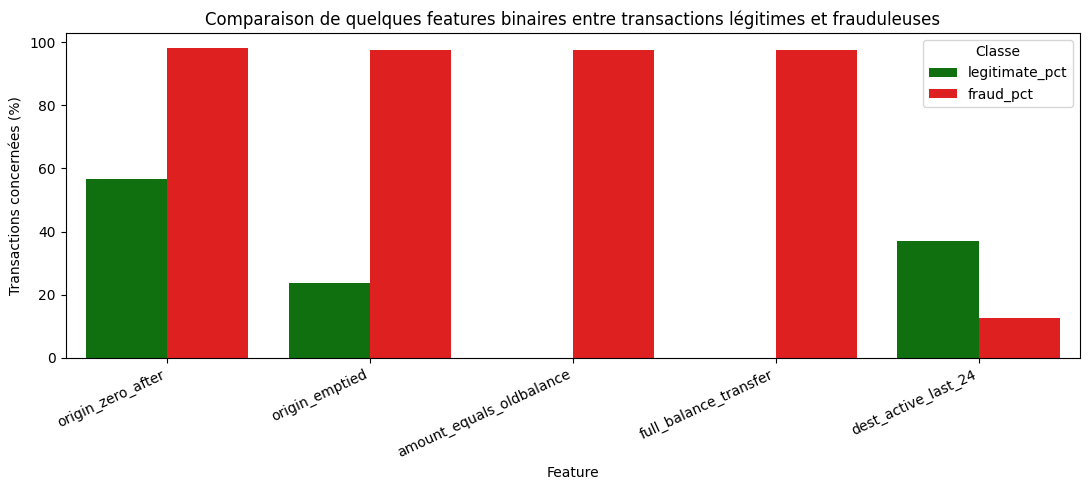

In [160]:
# Préparer les données du graphique
binary_plot_data = (
    binary_class_summary[
        [
            "legitimate_pct",
            "fraud_pct",
        ]
    ]
    .reset_index()
    .rename(
        columns={
            "index": "feature",
        }
    )
)

binary_plot_long = (
    binary_plot_data
    .melt(
        id_vars="feature",
        var_name="class",
        value_name="percentage",
    )
)

plt.figure(
    figsize=(11, 5)
)

sns.barplot(
    data=binary_plot_long,
    x="feature",
    y="percentage",
    hue="class",
    palette={
        "legitimate_pct": "green",
        "fraud_pct": "red",
    },
)

plt.title(
    "Comparaison de quelques features binaires "
    "entre transactions légitimes et frauduleuses"
)

plt.xlabel("Feature")
plt.ylabel("Transactions concernées (%)")

plt.xticks(
    rotation=25,
    ha="right",
)

plt.legend(
    title="Classe"
)

plt.tight_layout()
plt.show()

In [161]:
# Vérifier la mémoire
memory_analysis_mb = (
    df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

memory_analysis_gb = (
    memory_analysis_mb / 1024
)

print(
    f"Mémoire actuelle : "
    f"{memory_analysis_mb:,.2f} MB"
)

print(
    f"Mémoire actuelle : "
    f"{memory_analysis_gb:,.2f} GB"
)

Mémoire actuelle : 994.91 MB
Mémoire actuelle : 0.97 GB


### Observation

L'analyse consolidée confirme la stabilité et la cohérence des principales features construites.

Aucune valeur infinie n'est observée dans les variables représentatives. Les valeurs manquantes restantes sont structurelles : elles correspondent soit à un dénominateur nul pour certains ratios, soit à l'absence d'historique transactionnel.

`log_amount` conserve une séparation claire entre les classes, avec une médiane d'environ 11,22 pour les transactions légitimes contre 13,00 pour les fraudes.

Le ratio `amount_to_oldbalance_ratio` présente un comportement beaucoup plus spécifique : les trois quartiles étudiés sont égaux à 1 pour les fraudes, alors que la distribution légitime est beaucoup plus dispersée.

Le résidu du solde source présente également un signal particulièrement fort. Ses quartiles sont nuls pour les transactions frauduleuses, contrairement aux transactions légitimes.

Les features comportementales de destination fournissent un signal différent. Les transactions frauduleuses présentent généralement moins de transactions, moins de volume et moins de sources historiques côté destination. Leur temps depuis la dernière activité est également plus élevé.

Les indicateurs binaires confirment enfin le caractère particulier des features liées au vidage du compte. `amount_equals_oldbalance` et `full_balance_transfer` concernent environ 97,6 % et 97,5 % des fraudes, alors qu'elles sont pratiquement absentes des transactions légitimes.

### Interprétation

Les nouvelles features couvrent deux catégories de signaux distinctes.

Les variables comportementales et relationnelles, particulièrement côté destination, décrivent la maturité et la récence du compte dans l'historique transactionnel.

À l'inverse, certaines transformations de soldes présentent un pouvoir discriminant exceptionnellement élevé qui semble fortement lié au mécanisme de génération de PaySim.

Cette distinction justifie la séparation entre un ensemble de features générales et un ensemble PaySim-sensitive.

### Décision

Les principales transformations sont considérées comme numériquement stables.

Les NaN historiques sont conservés comme valeurs structurelles représentant l'absence d'historique et seront traités explicitement dans le futur pipeline ML.

Les features comportementales de destination sont conservées comme signaux importants.

Les features fortement associées au mécanisme de vidage du compte restent disponibles mais devront faire l'objet d'une étude d'ablation avant toute conclusion sur les performances du modèle.

## 14. Multicolinéarité et redondance

Le Feature Engineering a volontairement conservé plusieurs représentations complémentaires d'un même phénomène.

Cette stratégie est utile pour les modèles non linéaires et pour l'interprétation, mais elle peut également introduire des redondances importantes, particulièrement pour les modèles linéaires.

Cette section distingue trois situations :

- les relations mathématiquement déterministes entre plusieurs features ;
- les redondances structurelles liées à la représentation du graphe ou de la temporalité ;
- les fortes corrélations empiriques observées dans les données.

Aucune variable n'est supprimée automatiquement.

Les résultats serviront à définir ultérieurement des matrices adaptées aux différents modèles et à éviter notamment une multicolinéarité excessive dans les modèles linéaires.

Afin de ne pas utiliser la distribution future pour guider les décisions de sélection, les corrélations empiriques sont estimées uniquement sur l'ensemble Train.

In [162]:
# Vérifier les relations entre les soldes
origin_residual_error = np.abs(
    df["origin_balance_residual"].astype("float64")
    - (
        df["origin_balance_change"].astype("float64")
        - df["amount"]
    )
)

destination_residual_error = np.abs(
    df["destination_balance_residual"].astype("float64")
    - (
        df["amount"]
        - df["destination_balance_change"].astype("float64")
    )
)

print(
    "Écart maximal relation source :",
    origin_residual_error.max(),
)

print(
    "Écart maximal relation destination :",
    destination_residual_error.max(),
)

del origin_residual_error
del destination_residual_error
gc.collect()

Écart maximal relation source : 3.730000004172325
Écart maximal relation destination : 5.319999992847443


590

In [163]:
# Vérifier les relations binaires
origin_emptied_expected = (
    (df["oldbalanceOrg"] > 0)
    & (df["newbalanceOrig"] == 0)
)

full_balance_expected = (
    (df["origin_emptied"] == 1)
    & (df["amount_equals_oldbalance"] == 1)
)

dest_recent_expected = (
    df["dest_time_since_last"].le(24)
)

deterministic_binary_checks = pd.DataFrame({
    "relation": [
        "origin_emptied definition",
        "full_balance_transfer definition",
        "dest_active_last_24 definition",
    ],
    "passed": [
        bool(
            (
                df["origin_emptied"].astype(bool)
                == origin_emptied_expected
            ).all()
        ),
        bool(
            (
                df["full_balance_transfer"].astype(bool)
                == full_balance_expected
            ).all()
        ),
        bool(
            (
                df["dest_active_last_24"].astype(bool)
                == dest_recent_expected
            ).all()
        ),
    ],
})

display(deterministic_binary_checks)

del origin_emptied_expected
del full_balance_expected
del dest_recent_expected
gc.collect()

,relation,passed
0,origin_emptied definition,True
1,full_balance_transfer definition,True
2,dest_active_last_24 definition,True


4051

In [164]:
# Reconstruire le step
reconstructed_step = (
    (df["simulated_day"].astype("int32") - 1)
    * 24
    + df["cycle_position"].astype("int32")
    + 1
)

step_reconstruction_ok = bool(
    (
        reconstructed_step
        == df["step"].astype("int32")
    ).all()
)

print(
    "Step reconstructible depuis "
    "simulated_day + cycle_position :",
    step_reconstruction_ok,
)

del reconstructed_step
gc.collect()

Step reconstructible depuis simulated_day + cycle_position : True


160

In [165]:
# Mesurer la redondance degré-voisins
degree_neighbor_redundancy = pd.DataFrame({
    "pair": [
        (
            "orig_prev_transactions vs "
            "orig_prev_unique_destinations"
        ),
        (
            "dest_prev_transactions vs "
            "dest_prev_unique_sources"
        ),
    ],
    "equal_rows": [
        int(
            (
                df["orig_prev_transactions"]
                == df["orig_prev_unique_destinations"]
            ).sum()
        ),
        int(
            (
                df["dest_prev_transactions"]
                == df["dest_prev_unique_sources"]
            ).sum()
        ),
    ],
})

degree_neighbor_redundancy[
    "equal_pct"
] = (
    degree_neighbor_redundancy[
        "equal_rows"
    ]
    / len(df)
    * 100
)

display(degree_neighbor_redundancy)

,pair,equal_rows,equal_pct
0,orig_prev_transactions vs orig_prev_unique_des...,6362620,100.0000
1,dest_prev_transactions vs dest_prev_unique_sou...,6362620,100.0000


In [166]:
# Calculer les chevauchements
amount_equal_count = int(
    df["amount_equals_oldbalance"].sum()
)

origin_emptied_count = int(
    df["origin_emptied"].sum()
)

full_balance_count = int(
    df["full_balance_transfer"].sum()
)

pattern_overlap_summary = pd.DataFrame({
    "relation": [
        (
            "full_balance among "
            "amount_equals_oldbalance"
        ),
        (
            "full_balance among "
            "origin_emptied"
        ),
        (
            "amount_equals_oldbalance among "
            "full_balance"
        ),
        (
            "origin_emptied among "
            "full_balance"
        ),
    ],
    "percentage": [
        (
            full_balance_count
            / amount_equal_count
            * 100
        ),
        (
            full_balance_count
            / origin_emptied_count
            * 100
        ),
        100.0 if full_balance_count > 0 else np.nan,
        100.0 if full_balance_count > 0 else np.nan,
    ],
})

display(pattern_overlap_summary)

,relation,percentage
0,full_balance among amount_equals_oldbalance,99.8628
1,full_balance among origin_emptied,0.5266
2,amount_equals_oldbalance among full_balance,100.0000
3,origin_emptied among full_balance,100.0000


In [167]:
# Sélectionner les features de corrélation
correlation_features = [
    "amount",
    "log_amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "origin_balance_change",
    "destination_balance_change",
    "origin_balance_residual",
    "destination_balance_residual",
    "amount_to_oldbalance_ratio",
    "amount_to_dest_balance_ratio",
    "dest_prev_transactions",
    "dest_prev_volume",
    "dest_prev_mean_amount",
    "dest_prev_unique_sources",
    "dest_time_since_last",
]

In [169]:
# Sélectionner uniquement le Train
train_indices = df.index[
    df["split"] == "Train"
]

CORRELATION_SAMPLE_SIZE = min(
    500_000,
    len(train_indices),
)

# Échantillonner les indices
rng = np.random.default_rng(
    RANDOM_STATE
)

correlation_indices = rng.choice(
    train_indices.to_numpy(),
    size=CORRELATION_SAMPLE_SIZE,
    replace=False,
)

correlation_sample = df.loc[
    correlation_indices,
    correlation_features,
].copy()

print(
    "Taille de l'échantillon :",
    correlation_sample.shape,
)

Taille de l'échantillon : (500000, 17)


In [170]:
# Calculer la matrice de corrélation
correlation_matrix = (
    correlation_sample
    .corr(
        method="pearson",
    )
)

display(
    correlation_matrix.round(3)
)

,amount,log_amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,origin_balance_change,destination_balance_change,origin_balance_residual,destination_balance_residual,amount_to_oldbalance_ratio,amount_to_dest_balance_ratio,dest_prev_transactions,dest_prev_volume,dest_prev_mean_amount,dest_prev_unique_sources,dest_time_since_last
amount,1.0000,0.3550,-0.0070,-0.0090,0.3810,0.5610,0.0470,0.8510,-0.9830,-0.2250,0.0720,0.0120,0.1430,0.2910,0.2420,0.1430,0.0010
log_amount,0.3550,1.0000,0.1050,0.1100,0.2420,0.2770,-0.1460,0.2360,-0.3790,0.0440,0.0410,0.0160,0.3860,0.2890,0.0780,0.3860,-0.0190
oldbalanceOrg,-0.0070,0.1050,1.0000,0.9990,0.0690,0.0410,-0.2670,-0.0770,-0.0420,0.1330,-0.0130,-0.0050,0.1320,0.0910,0.0090,0.1320,-0.0260
newbalanceOrig,-0.0090,0.1100,0.9990,1.0000,0.0700,0.0410,-0.3070,-0.0830,-0.0480,0.1410,-0.0130,-0.0050,0.1350,0.0930,0.0090,0.1350,-0.0260
oldbalanceDest,0.3810,0.2420,0.0690,0.0700,1.0000,0.9680,-0.0540,0.2990,-0.3880,-0.0380,0.0030,-0.0060,0.4680,0.8200,0.5790,0.4680,-0.0760
newbalanceDest,0.5610,0.2770,0.0410,0.0410,0.9680,1.0000,-0.0090,0.5270,-0.5580,-0.2180,0.0170,-0.0030,0.4380,0.7860,0.5700,0.4380,-0.0670
origin_balance_change,0.0470,-0.1460,-0.2670,-0.3070,-0.0540,-0.0090,1.0000,0.1490,0.1390,-0.2130,-0.0050,0.0040,-0.1060,-0.0730,-0.0090,-0.1060,0.0110
destination_balance_change,0.8510,0.2360,-0.0770,-0.0830,0.2990,0.5270,0.1490,1.0000,-0.8160,-0.7030,0.0520,0.0110,0.0820,0.2130,0.2100,0.0820,0.0030
origin_balance_residual,-0.9830,-0.3790,-0.0420,-0.0480,-0.3880,-0.5580,0.1390,-0.8160,1.0000,0.1830,-0.0710,-0.0120,-0.1620,-0.3020,-0.2420,-0.1620,0.0000
destination_balance_residual,-0.2250,0.0440,0.1330,0.1410,-0.0380,-0.2180,-0.2130,-0.7030,0.1830,1.0000,-0.0140,-0.0040,0.0420,-0.0010,-0.0520,0.0420,-0.0030


In [171]:
# Extraire les paires fortement corrélées
correlation_pairs = []

columns = correlation_matrix.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        value = correlation_matrix.iloc[
            i,
            j,
        ]

        if (
            pd.notna(value)
            and abs(value) >= 0.90
        ):
            correlation_pairs.append({
                "feature_1": columns[i],
                "feature_2": columns[j],
                "correlation": value,
            })

high_correlation_pairs = (
    pd.DataFrame(
        correlation_pairs
    )
)

if not high_correlation_pairs.empty:
    high_correlation_pairs[
        "abs_correlation"
    ] = (
        high_correlation_pairs[
            "correlation"
        ].abs()
    )

    high_correlation_pairs = (
        high_correlation_pairs
        .sort_values(
            "abs_correlation",
            ascending=False,
        )
        .drop(
            columns="abs_correlation"
        )
        .reset_index(
            drop=True
        )
    )

display(high_correlation_pairs)

,feature_1,feature_2,correlation
0,dest_prev_transactions,dest_prev_unique_sources,1.0000
1,oldbalanceOrg,newbalanceOrig,0.9991
2,amount,origin_balance_residual,-0.9826
3,oldbalanceDest,newbalanceDest,0.9685


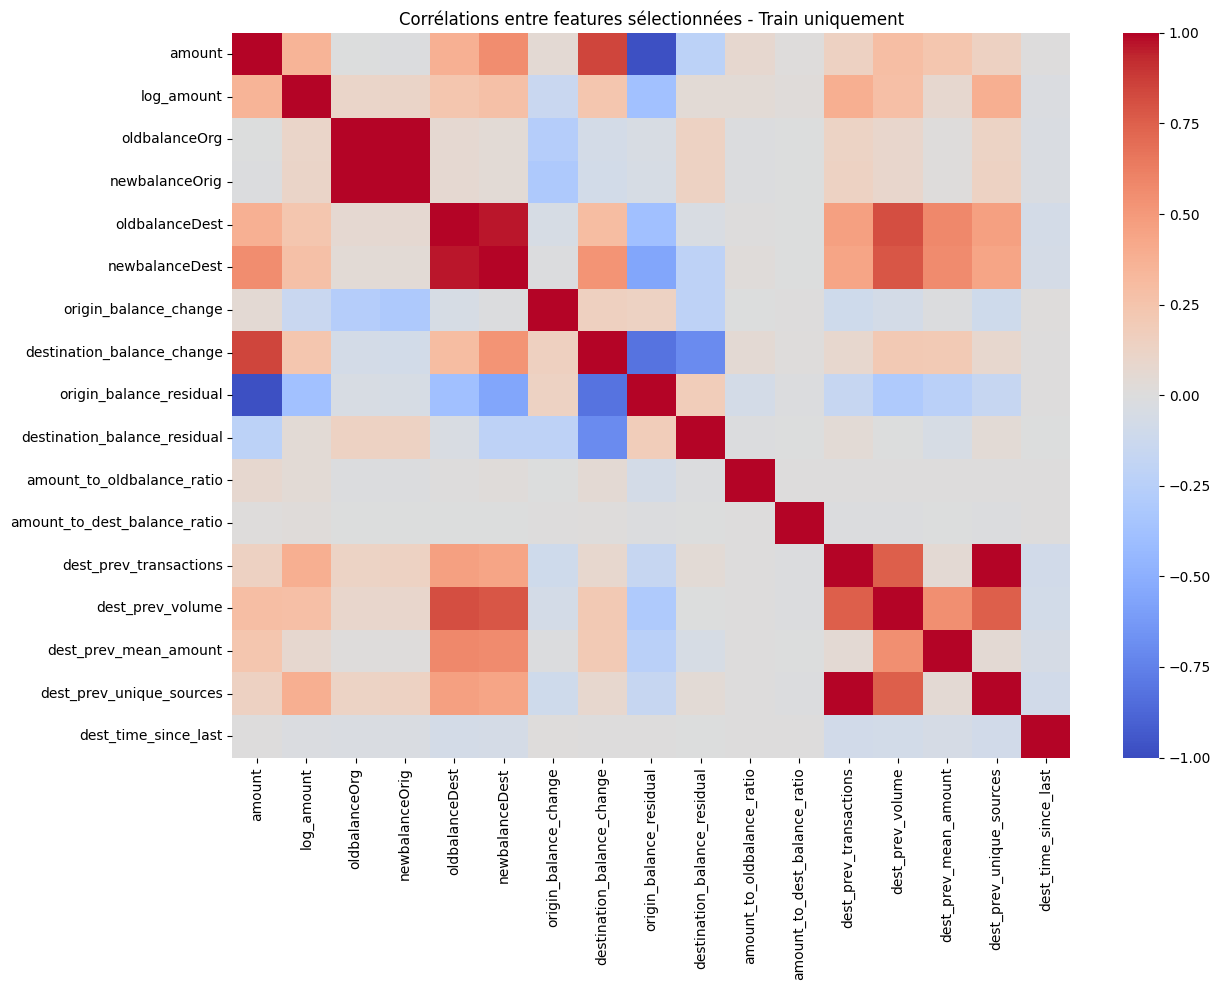

In [172]:
# Visualiser les corrélations
plt.figure(
    figsize=(13, 10)
)

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title(
    "Corrélations entre features sélectionnées "
    "- Train uniquement"
)

plt.tight_layout()
plt.show()

In [173]:
# Sélectionner les indicateurs binaires
binary_redundancy_features = [
    "origin_zero_after",
    "origin_emptied",
    "amount_equals_oldbalance",
    "full_balance_transfer",
    "dest_active_last_24",
]

binary_redundancy_matrix = (
    df.loc[
        df["split"] == "Train",
        binary_redundancy_features,
    ]
    .corr()
)

display(
    binary_redundancy_matrix.round(3)
)

,origin_zero_after,origin_emptied,amount_equals_oldbalance,full_balance_transfer,dest_active_last_24
origin_zero_after,1.0000,0.4860,0.0240,0.0240,0.0590
origin_emptied,0.4860,1.0000,0.0500,0.0500,0.0010
amount_equals_oldbalance,0.0240,0.0500,1.0000,0.9990,-0.0110
full_balance_transfer,0.0240,0.0500,0.9990,1.0000,-0.0110
dest_active_last_24,0.0590,0.0010,-0.0110,-0.0110,1.0000


In [174]:
# Documenter les redondances
redundancy_registry = pd.DataFrame([
    {
        "features":
            (
                "amount + origin_balance_change + "
                "origin_balance_residual"
            ),
        "relationship":
            "deterministic linear relation",
        "action":
            "review for linear models",
    },
    {
        "features":
            (
                "amount + destination_balance_change + "
                "destination_balance_residual"
            ),
        "relationship":
            "deterministic linear relation",
        "action":
            "review for linear models",
    },
    {
        "features":
            (
                "step + simulated_day + "
                "cycle_position"
            ),
        "relationship":
            "deterministic temporal relation",
        "action":
            "avoid redundant use in linear models",
    },
    {
        "features":
            (
                "cycle_position + cycle_sin + "
                "cycle_cos"
            ),
        "relationship":
            "deterministic transformation",
        "action":
            "model-dependent representation",
    },
    {
        "features":
            (
                "dest_time_since_last + "
                "dest_active_last_24"
            ),
        "relationship":
            "threshold transformation",
        "action":
            "keep only if useful by model type",
    },
    {
        "features":
            (
                "orig_prev_transactions + "
                "orig_prev_unique_destinations"
            ),
        "relationship":
            "potential structural redundancy",
        "action":
            "quantify in PaySim",
    },
    {
        "features":
            (
                "dest_prev_transactions + "
                "dest_prev_unique_sources"
            ),
        "relationship":
            "potential structural redundancy",
        "action":
            "quantify in PaySim",
    },
    {
        "features":
            (
                "origin_emptied + "
                "amount_equals_oldbalance + "
                "full_balance_transfer"
            ),
        "relationship":
            "nested PaySim-sensitive patterns",
        "action":
            "ablation and redundancy review",
    },
])

display(redundancy_registry)

,features,relationship,action
0,amount + origin_balance_change + origin_balanc...,deterministic linear relation,review for linear models
1,amount + destination_balance_change + destinat...,deterministic linear relation,review for linear models
2,step + simulated_day + cycle_position,deterministic temporal relation,avoid redundant use in linear models
3,cycle_position + cycle_sin + cycle_cos,deterministic transformation,model-dependent representation
4,dest_time_since_last + dest_active_last_24,threshold transformation,keep only if useful by model type
5,orig_prev_transactions + orig_prev_unique_dest...,potential structural redundancy,quantify in PaySim
6,dest_prev_transactions + dest_prev_unique_sources,potential structural redundancy,quantify in PaySim
7,origin_emptied + amount_equals_oldbalance + fu...,nested PaySim-sensitive patterns,ablation and redundancy review


In [175]:
# Libérer les objets temporaires volumineux
del correlation_sample
del correlation_indices
del train_indices
gc.collect()

160

In [176]:
# Vérifier la mémoire
memory_redundancy_mb = (
    df.memory_usage(deep=True).sum()
    / (1024 ** 2)
)

memory_redundancy_gb = (
    memory_redundancy_mb / 1024
)

print(
    f"Mémoire actuelle : "
    f"{memory_redundancy_mb:,.2f} MB"
)

print(
    f"Mémoire actuelle : "
    f"{memory_redundancy_gb:,.2f} GB"
)

Mémoire actuelle : 994.91 MB
Mémoire actuelle : 0.97 GB


### Observation

L'analyse des redondances met en évidence plusieurs relations importantes entre les features construites.

Les relations déterministes liées aux soldes sont correctement vérifiées. Les faibles écarts numériques observés, inférieurs à quelques unités pour des variables atteignant plusieurs dizaines de millions, proviennent du stockage des transformations en `float32`.

Les soldes avant et après transaction restent fortement corrélés dans l'ensemble Train. La corrélation atteint environ 0,999 entre `oldbalanceOrg` et `newbalanceOrig`, et 0,968 entre `oldbalanceDest` et `newbalanceDest`.

Une redondance structurelle exacte apparaît également dans les features Graph-ready. `orig_prev_transactions` est identique à `orig_prev_unique_destinations` sur l'ensemble du dataset, tandis que `dest_prev_transactions` est identique à `dest_prev_unique_sources`. Dans PaySim, le degré historique et le nombre de voisins historiques apportent donc la même information.

Les patterns de vidage montrent également une forte redondance. Environ 99,86 % des transactions satisfaisant `amount_equals_oldbalance` satisfont également `full_balance_transfer`. Leur corrélation binaire atteint environ 0,999.

En revanche, `origin_emptied` est beaucoup plus général : seulement environ 0,53 % des transactions présentant ce comportement correspondent à un transfert complet du solde.

Enfin, les différentes statistiques comportementales de destination ne sont pas parfaitement corrélées. Les volumes, fréquences, montants moyens et informations de récence décrivent donc des dimensions complémentaires de l'historique du compte.

### Interprétation

Certaines redondances proviennent directement des définitions mathématiques des features, tandis que d'autres sont spécifiques à la structure du dataset PaySim.

Ces résultats sont particulièrement importants pour les modèles linéaires, qui peuvent être sensibles à la multicolinéarité.

Les modèles non linéaires peuvent tolérer davantage de redondance, mais la suppression des duplications exactes reste souhaitable afin de simplifier les matrices et leur interprétation.

### Décision

Aucune colonne n'est supprimée directement du DataFrame principal à cette étape.

Les redondances seront prises en compte lors de la définition des ensembles de features finaux.

En particulier :

- les degrés historiques seront privilégiés par rapport aux nombres de voisins exactement redondants ;
- `type` sera privilégié par rapport aux indicateurs binaires dérivés lorsque le One-Hot Encoding est utilisé ;
- `full_balance_transfer` ne sera pas utilisé systématiquement avec `amount_equals_oldbalance` ;
- les représentations temporelles seront sélectionnées selon le type de modèle ;
- les modèles linéaires utiliseront une sélection plus restrictive des variables de soldes.

## 15. Séparation définitive des familles de features

Les analyses précédentes permettent maintenant de définir les familles de features qui seront utilisées dans les étapes de modélisation.

La séparation répond à plusieurs objectifs :

- distinguer les informations transactionnelles, temporelles, comportementales et relationnelles ;
- isoler les variables potentiellement spécifiques au simulateur PaySim ;
- éviter les duplications exactes mises en évidence lors de l'analyse de redondance ;
- préparer différentes matrices selon le type de modèle ;
- conserver les identifiants et timestamps nécessaires au futur Graph Learning sans les utiliser comme prédicteurs classiques.

Le DataFrame principal reste unique. Les différentes configurations sont représentées par des listes de colonnes afin de limiter les copies mémoire.

In [177]:
# Définir les features transactionnelles
transaction_features = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "log_amount",
    "amount_to_dest_balance_ratio",
    "origin_balance_change",
    "destination_balance_change",
    "origin_zero_before",
    "origin_zero_after",
    "destination_zero_before",
    "destination_zero_after",
]

print(
    "Transaction features :",
    len(transaction_features),
)

Transaction features : 13


In [178]:
# Définir les features temporelles
temporal_features = [
    "step",
    "cycle_position",
    "cycle_sin",
    "cycle_cos",
    "simulated_day",
]

print(
    "Temporal features :",
    len(temporal_features),
)

Temporal features : 5


In [179]:
# Définir les features comportementales
behavioral_features = [
    "orig_prev_transactions",
    "orig_prev_volume",
    "orig_prev_mean_amount",
    "orig_time_since_last",
    "dest_prev_transactions",
    "dest_prev_volume",
    "dest_prev_mean_amount",
    "dest_time_since_last",
    "dest_active_last_24",
]

print(
    "Behavioral features :",
    len(behavioral_features),
)

Behavioral features : 9


In [180]:
# Définir les features Graph-ready
graph_features = [
    "orig_prev_transactions",
    "dest_prev_transactions",
    "orig_prev_volume",
    "dest_prev_volume",
    "orig_time_since_last",
    "dest_time_since_last",
]

print(
    "Graph features :",
    len(graph_features),
)

Graph features : 6


In [181]:
# Définir la feature catégorielle
categorical_features = [
    "type",
]

print(
    "Categorical features :",
    categorical_features,
)

Categorical features : ['type']


In [182]:
# Définir la cible
target = "isFraud"

# Définir les identifiants
identifier_features = [
    "nameOrig",
    "nameDest",
]

# Définir les métadonnées
metadata_features = [
    "step",
    "split",
]

# Définir les colonnes interdites
forbidden_features = [
    "isFlaggedFraud",
]

In [183]:
# Définir la cible
target = "isFraud"

# Définir les identifiants
identifier_features = [
    "nameOrig",
    "nameDest",
]

# Définir les métadonnées
metadata_features = [
    "step",
    "split",
]

# Définir les colonnes interdites
forbidden_features = [
    "isFlaggedFraud",
]

In [184]:
# Définir les features sensibles à PaySim
paysim_sensitive_features = [
    "amount_to_oldbalance_ratio",
    "origin_balance_residual",
    "destination_balance_residual",
    "origin_emptied",
    "amount_equals_oldbalance",
    "full_balance_transfer",
    "cycle_position",
    "cycle_sin",
    "cycle_cos",
    "simulated_day",
    "dest_active_last_24",
]

print(
    "PaySim-sensitive features :",
    len(paysim_sensitive_features),
)

PaySim-sensitive features : 11


In [185]:
# Définir les features redondantes
redundant_analysis_features = [
    "is_transfer",
    "is_cash_out",
    "orig_prev_unique_destinations",
    "dest_prev_unique_sources",
    "cycle_position",
    "full_balance_transfer",
]

print(
    "Redundant / analysis-only features :",
    len(redundant_analysis_features),
)

Redundant / analysis-only features : 6


In [186]:
# Définir les features Core
core_ml_features = [
    feature
    for feature in ml_feature_candidates
    if (
        feature
        not in paysim_sensitive_features
        and feature
        not in redundant_analysis_features
    )
]

print(
    "Core ML features :",
    len(core_ml_features),
)

print(core_ml_features)

Core ML features : 22
['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'log_amount', 'amount_to_dest_balance_ratio', 'origin_balance_change', 'destination_balance_change', 'origin_zero_before', 'origin_zero_after', 'destination_zero_before', 'destination_zero_after', 'type', 'orig_prev_transactions', 'orig_prev_volume', 'orig_prev_mean_amount', 'orig_time_since_last', 'dest_prev_transactions', 'dest_prev_volume', 'dest_prev_mean_amount', 'dest_time_since_last']


In [187]:
# Définir les features sensibles utilisables
model_paysim_sensitive_features = [
    feature
    for feature in paysim_sensitive_features
    if feature not in {
        "cycle_position",
        "full_balance_transfer",
    }
]

print(
    "Model PaySim-sensitive features :",
    len(
        model_paysim_sensitive_features
    ),
)

Model PaySim-sensitive features : 9


In [188]:
# Définir les features Core
core_ml_features = [
    feature
    for feature in ml_feature_candidates
    if (
        feature
        not in paysim_sensitive_features
        and feature
        not in redundant_analysis_features
    )
]

print(
    "Core ML features :",
    len(core_ml_features),
)

print(core_ml_features)

Core ML features : 22
['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'log_amount', 'amount_to_dest_balance_ratio', 'origin_balance_change', 'destination_balance_change', 'origin_zero_before', 'origin_zero_after', 'destination_zero_before', 'destination_zero_after', 'type', 'orig_prev_transactions', 'orig_prev_volume', 'orig_prev_mean_amount', 'orig_time_since_last', 'dest_prev_transactions', 'dest_prev_volume', 'dest_prev_mean_amount', 'dest_time_since_last']


In [189]:
# Définir les features sensibles utilisables
model_paysim_sensitive_features = [
    feature
    for feature in paysim_sensitive_features
    if feature not in {
        "cycle_position",
        "full_balance_transfer",
    }
]

print(
    "Model PaySim-sensitive features :",
    len(
        model_paysim_sensitive_features
    ),
)

Model PaySim-sensitive features : 9


In [190]:
# Construire l'ensemble Full
full_ml_features = (
    core_ml_features
    + model_paysim_sensitive_features
)

# Retirer les doublons éventuels
full_ml_features = list(
    dict.fromkeys(
        full_ml_features
    )
)

print(
    "Full ML features :",
    len(full_ml_features),
)

Full ML features : 31


In [191]:
# Définir les exclusions linéaires Core
linear_core_exclusions = [
    "newbalanceOrig",
    "newbalanceDest",
]

linear_core_features = [
    feature
    for feature in core_ml_features
    if feature
    not in linear_core_exclusions
]

print(
    "Linear Core features :",
    len(linear_core_features),
)

Linear Core features : 20


In [192]:
# Définir les exclusions linéaires Full
linear_full_exclusions = [
    "newbalanceOrig",
    "newbalanceDest",
    "origin_balance_residual",
    "destination_balance_residual",
]

linear_full_features = [
    feature
    for feature in full_ml_features
    if feature
    not in linear_full_exclusions
]

print(
    "Linear Full features :",
    len(linear_full_features),
)

Linear Full features : 27


In [193]:
# Définir les edge features Graph Core
graph_core_edge_features = [
    "amount",
    "log_amount",
    "type",
    "origin_balance_change",
    "destination_balance_change",
    "origin_zero_before",
    "origin_zero_after",
    "destination_zero_before",
    "destination_zero_after",
]

# Définir les node-history features
graph_node_history_features = [
    "orig_prev_transactions",
    "dest_prev_transactions",
    "orig_prev_volume",
    "dest_prev_volume",
    "orig_time_since_last",
    "dest_time_since_last",
]

In [194]:
# Définir les features Graph sensibles
graph_sensitive_features = [
    "amount_to_oldbalance_ratio",
    "origin_balance_residual",
    "destination_balance_residual",
    "origin_emptied",
    "amount_equals_oldbalance",
    "cycle_sin",
    "cycle_cos",
    "simulated_day",
    "dest_active_last_24",
]

In [195]:
# Résumer les familles finales
final_feature_groups = pd.DataFrame({
    "family": [
        "Transaction",
        "Temporal",
        "Behavioral",
        "Graph relational",
        "Categorical",
        "PaySim-sensitive",
        "Core ML",
        "Full ML",
        "Linear Core",
        "Linear Full",
        "Graph Core edge",
        "Graph node history",
        "Graph sensitive",
    ],
    "count": [
        len(transaction_features),
        len(temporal_features),
        len(behavioral_features),
        len(graph_features),
        len(categorical_features),
        len(paysim_sensitive_features),
        len(core_ml_features),
        len(full_ml_features),
        len(linear_core_features),
        len(linear_full_features),
        len(graph_core_edge_features),
        len(graph_node_history_features),
        len(graph_sensitive_features),
    ],
})

display(final_feature_groups)

,family,count
0,Transaction,13
1,Temporal,5
2,Behavioral,9
3,Graph relational,6
4,Categorical,1
5,PaySim-sensitive,11
6,Core ML,22
7,Full ML,31
8,Linear Core,20
9,Linear Full,27


In [196]:
# Résumer les familles finales
final_feature_groups = pd.DataFrame({
    "family": [
        "Transaction",
        "Temporal",
        "Behavioral",
        "Graph relational",
        "Categorical",
        "PaySim-sensitive",
        "Core ML",
        "Full ML",
        "Linear Core",
        "Linear Full",
        "Graph Core edge",
        "Graph node history",
        "Graph sensitive",
    ],
    "count": [
        len(transaction_features),
        len(temporal_features),
        len(behavioral_features),
        len(graph_features),
        len(categorical_features),
        len(paysim_sensitive_features),
        len(core_ml_features),
        len(full_ml_features),
        len(linear_core_features),
        len(linear_full_features),
        len(graph_core_edge_features),
        len(graph_node_history_features),
        len(graph_sensitive_features),
    ],
})

display(final_feature_groups)

,family,count
0,Transaction,13
1,Temporal,5
2,Behavioral,9
3,Graph relational,6
4,Categorical,1
5,PaySim-sensitive,11
6,Core ML,22
7,Full ML,31
8,Linear Core,20
9,Linear Full,27


In [197]:
# Regrouper les features physiques
all_final_features = set(
    transaction_features
    + temporal_features
    + behavioral_features
    + graph_features
    + categorical_features
    + paysim_sensitive_features
)

missing_final_features = sorted(
    all_final_features
    - set(df.columns)
)

print(
    "Features finales manquantes :",
    missing_final_features,
)

Features finales manquantes : []


In [198]:
# Vérifier les features Core
core_forbidden = sorted(
    set(core_ml_features)
    .intersection(
        {
            "isFraud",
            "isFlaggedFraud",
            "nameOrig",
            "nameDest",
            "split",
            "step",
        }
    )
)

print(
    "Colonnes interdites dans Core :",
    core_forbidden,
)

Colonnes interdites dans Core : []


In [199]:
# Vérifier l'unicité des features Full
print(
    "Doublons Full ML :",
    len(full_ml_features)
    - len(set(full_ml_features)),
)

Doublons Full ML : 0


In [200]:
# Vérifier la séparation des familles
core_sensitive_overlap = sorted(
    set(core_ml_features)
    .intersection(
        paysim_sensitive_features
    )
)

print(
    "Overlap Core / PaySim-sensitive :",
    core_sensitive_overlap,
)

Overlap Core / PaySim-sensitive : []


In [201]:
# Documenter les décisions finales
feature_set_decisions = pd.DataFrame([
    {
        "set": "Core ML",
        "purpose":
            "General fraud detection features",
        "notes":
            "Excludes PaySim-sensitive features",
    },
    {
        "set": "Full ML",
        "purpose":
            "Maximum predictive experiment",
        "notes":
            "Adds selected PaySim-sensitive features",
    },
    {
        "set": "Linear Core",
        "purpose":
            "Linear baseline without deterministic balance redundancy",
        "notes":
            "Reduced balance representation",
    },
    {
        "set": "Linear Full",
        "purpose":
            "Linear ablation with PaySim-sensitive signals",
        "notes":
            "Residual redundancies removed",
    },
    {
        "set": "Graph Core",
        "purpose":
            "Temporal edge classification",
        "notes":
            "Transaction + historical node information",
    },
    {
        "set": "Graph Sensitive",
        "purpose":
            "PaySim-specific graph ablation",
        "notes":
            "Adds simulator-sensitive attributes",
    },
])

display(feature_set_decisions)

,set,purpose,notes
0,Core ML,General fraud detection features,Excludes PaySim-sensitive features
1,Full ML,Maximum predictive experiment,Adds selected PaySim-sensitive features
2,Linear Core,Linear baseline without deterministic balance ...,Reduced balance representation
3,Linear Full,Linear ablation with PaySim-sensitive signals,Residual redundancies removed
4,Graph Core,Temporal edge classification,Transaction + historical node information
5,Graph Sensitive,PaySim-specific graph ablation,Adds simulator-sensitive attributes


### Synthèse des familles de features

La phase de Feature Engineering aboutit à plusieurs ensembles de variables adaptés aux futurs scénarios de modélisation.

L'ensemble **Core ML** contient 22 features considérées comme les plus générales. Il regroupe les caractéristiques transactionnelles, les transformations de soldes non classées comme spécifiques au simulateur, le type d'opération et les informations comportementales historiques.

L'ensemble **Full ML** contient 31 features. Il ajoute neuf variables PaySim-sensitive sélectionnées afin de mesurer l'amélioration de performance obtenue lorsque les signaux potentiellement spécifiques au simulateur sont disponibles.

Deux versions plus restrictives sont également définies pour les modèles linéaires :

- 20 features pour `Linear Core` ;
- 27 features pour `Linear Full`.

Ces versions réduisent certaines relations déterministes entre les soldes afin de limiter la multicolinéarité.

Les variables relationnelles nécessaires au futur Graph Learning sont également identifiées sans duplication physique des degrés et nombres de voisins, puisque ces informations sont exactement redondantes dans PaySim.

### Décision

Les principaux ensembles utilisés dans les prochains notebooks seront :

- **Core ML** : expérience principale avec les features les plus générales ;
- **Full ML** : expérience d'ablation intégrant les signaux PaySim-sensitive ;
- **Linear Core / Linear Full** : variantes adaptées aux modèles linéaires ;
- **Graph Core** : attributs transactionnels et historiques pour la classification temporelle des arêtes ;
- **Graph Sensitive** : extension Graph intégrant les variables sensibles au simulateur.

Le DataFrame enrichi reste unique en mémoire. Les différents scénarios sont représentés par des listes de colonnes afin d'éviter la duplication du dataset.

## 16. Dataset Machine Learning final

Le dataset destiné au Notebook `04_machine_learning_baseline.ipynb` doit permettre plusieurs expériences sans dupliquer inutilement plusieurs millions de transactions.

Une seule représentation ML sera donc préparée. Elle contiendra :

- les 31 prédicteurs de l'ensemble `Full ML` ;
- `step` comme métadonnée temporelle ;
- `split` pour identifier Train, Validation et Test ;
- `isFraud` comme variable cible.

Les matrices `Core`, `Linear Core` et `Linear Full` seront reconstruites dans le Notebook 04 à partir des listes de features définies précédemment.

Les identifiants `nameOrig` et `nameDest` ne sont pas inclus dans le dataset Machine Learning classique. Ils seront conservés uniquement dans la représentation Graph-ready.

`isFlaggedFraud` est également exclue afin d'éviter tout proxy leakage.

In [202]:
# Définir les métadonnées ML
ml_metadata_columns = [
    "step",
    "split",
]

# Définir la cible ML
ml_target_columns = [
    target,
]

# Définir les colonnes du dataset ML
ml_export_columns = (
    ml_metadata_columns
    + full_ml_features
    + ml_target_columns
)

# Retirer les doublons éventuels
ml_export_columns = list(
    dict.fromkeys(
        ml_export_columns
    )
)

print(
    "Nombre total de colonnes ML :",
    len(ml_export_columns),
)

print(
    "Nombre de prédicteurs :",
    len(full_ml_features),
)

Nombre total de colonnes ML : 34
Nombre de prédicteurs : 31


In [203]:
# Vérifier les colonnes ML
ml_schema_check = pd.DataFrame({
    "role": [
        "Metadata",
        "Predictors Full",
        "Target",
        "Total",
    ],
    "count": [
        len(ml_metadata_columns),
        len(full_ml_features),
        len(ml_target_columns),
        len(ml_export_columns),
    ],
})

display(ml_schema_check)

,role,count
0,Metadata,2
1,Predictors Full,31
2,Target,1
3,Total,34


In [204]:
# Définir les colonnes interdites
ml_forbidden_columns = {
    "nameOrig",
    "nameDest",
    "isFlaggedFraud",
}

# Vérifier les colonnes interdites
forbidden_in_ml_dataset = sorted(
    ml_forbidden_columns
    .intersection(
        ml_export_columns
    )
)

print(
    "Colonnes interdites dans le dataset ML :",
    forbidden_in_ml_dataset,
)

Colonnes interdites dans le dataset ML : []


In [205]:
# Vérifier la séparation X / y
assert (
    target
    not in full_ml_features
)

assert (
    target
    not in core_ml_features
)

assert (
    target
    not in linear_core_features
)

assert (
    target
    not in linear_full_features
)

print(
    "La cible est correctement séparée des prédicteurs."
)

La cible est correctement séparée des prédicteurs.


In [206]:
# Résumer les configurations ML
ml_model_sets = pd.DataFrame({
    "feature_set": [
        "Core",
        "Full",
        "Linear Core",
        "Linear Full",
    ],
    "n_features": [
        len(core_ml_features),
        len(full_ml_features),
        len(linear_core_features),
        len(linear_full_features),
    ],
    "purpose": [
        "General baseline",
        "PaySim-sensitive ablation",
        "Linear baseline",
        "Linear sensitive ablation",
    ],
})

display(ml_model_sets)

,feature_set,n_features,purpose
0,Core,22,General baseline
1,Full,31,PaySim-sensitive ablation
2,Linear Core,20,Linear baseline
3,Linear Full,27,Linear sensitive ablation


In [207]:
# Vérifier les partitions ML
ml_split_summary = (
    df.groupby(
        "split",
        observed=True,
    )
    .agg(
        step_start=("step", "min"),
        step_end=("step", "max"),
        transactions=(target, "size"),
        frauds=(target, "sum"),
    )
    .reset_index()
)

ml_split_summary[
    "fraud_rate_pct"
] = (
    ml_split_summary["frauds"]
    / ml_split_summary["transactions"]
    * 100
)

display(ml_split_summary)

,split,step_start,step_end,transactions,frauds,fraud_rate_pct
0,Train,1,334,4771387,3745,0.0785
1,Validation,335,392,792406,638,0.0805
2,Test,393,743,798827,3830,0.4795


In [212]:
# Résumer les valeurs manquantes
ml_missing_rows = []

for feature in full_ml_features:

    missing = int(
        df[feature]
        .isna()
        .sum()
    )

    if missing > 0:
        ml_missing_rows.append({
            "feature": feature,
            "missing": missing,
            "missing_pct": (
                missing
                / len(df)
                * 100
            ),
        })

ml_missing_summary = pd.DataFrame(
    ml_missing_rows
)

if not ml_missing_summary.empty:
    ml_missing_summary = (
        ml_missing_summary
        .sort_values(
            "missing_pct",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )

display(ml_missing_summary)

,feature,missing,missing_pct
0,orig_prev_mean_amount,6353354,99.8544
1,orig_time_since_last,6353354,99.8544
2,dest_time_since_last,2769903,43.5340
3,dest_prev_mean_amount,2769903,43.5340
4,amount_to_dest_balance_ratio,2704388,42.5043
5,amount_to_oldbalance_ratio,2102449,33.0438


In [214]:
# Vérifier les valeurs infinies
ml_infinite_rows = []

for feature in full_ml_features:

    if pd.api.types.is_numeric_dtype(
        df[feature]
    ):
        infinite = int(
            np.isinf(
                df[feature].to_numpy()
            ).sum()
        )

        if infinite > 0:
            ml_infinite_rows.append({
                "feature": feature,
                "infinite": infinite,
            })

ml_infinite_summary = pd.DataFrame(
    ml_infinite_rows
)

display(ml_infinite_summary)

""


In [215]:
# Vérifier les types ML
ml_dtype_summary = (
    pd.DataFrame({
        "feature": full_ml_features,
        "dtype": [
            str(df[col].dtype)
            for col in full_ml_features
        ],
    })
)

display(ml_dtype_summary)

,feature,dtype
0,amount,float64
1,oldbalanceOrg,float64
2,newbalanceOrig,float64
3,oldbalanceDest,float64
4,newbalanceDest,float64
5,log_amount,float32
6,amount_to_dest_balance_ratio,float32
7,origin_balance_change,float32
8,destination_balance_change,float32
9,origin_zero_before,int8


In [216]:
# Vérifier les catégories
type_categories = (
    df["type"]
    .cat.categories
    .tolist()
)

print(
    "Catégories de type :",
    type_categories,
)

print(
    "Nombre de catégories :",
    len(type_categories),
)

Catégories de type : ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']
Nombre de catégories : 5


In [217]:
# Estimer la mémoire du dataset ML
ml_memory_bytes = sum(
    df[col].memory_usage(
        deep=True,
        index=False,
    )
    for col in ml_export_columns
)

ml_memory_mb = (
    ml_memory_bytes
    / (1024 ** 2)
)

ml_memory_gb = (
    ml_memory_mb
    / 1024
)

print(
    f"Mémoire estimée du dataset ML : "
    f"{ml_memory_mb:,.2f} MB"
)

print(
    f"Mémoire estimée du dataset ML : "
    f"{ml_memory_gb:,.2f} GB"
)

Mémoire estimée du dataset ML : 716.01 MB
Mémoire estimée du dataset ML : 0.70 GB


In [218]:
# Vérifier l'ordre temporel
ml_temporal_order_ok = (
    df["step"]
    .is_monotonic_increasing
)

print(
    "Ordre temporel conservé :",
    ml_temporal_order_ok,
)

Ordre temporel conservé : True


In [219]:
# Auditer le schéma ML
ml_dataset_audit = pd.DataFrame({
    "check": [
        "All export columns exist",
        "No raw account identifiers",
        "isFlaggedFraud excluded",
        "Target excluded from predictors",
        "No duplicate export columns",
        "Chronological order preserved",
        "Split column available",
    ],
    "passed": [
        set(
            ml_export_columns
        ).issubset(
            df.columns
        ),
        not any(
            col in ml_export_columns
            for col in [
                "nameOrig",
                "nameDest",
            ]
        ),
        (
            "isFlaggedFraud"
            not in ml_export_columns
        ),
        (
            target
            not in full_ml_features
        ),
        (
            len(ml_export_columns)
            == len(
                set(ml_export_columns)
            )
        ),
        ml_temporal_order_ok,
        (
            "split"
            in ml_export_columns
        ),
    ],
})

display(ml_dataset_audit)

,check,passed
0,All export columns exist,True
1,No raw account identifiers,True
2,isFlaggedFraud excluded,True
3,Target excluded from predictors,True
4,No duplicate export columns,True
5,Chronological order preserved,True
6,Split column available,True


In [220]:
# Valider le schéma ML
assert ml_dataset_audit[
    "passed"
].all()

print(
    "Dataset Machine Learning prêt pour export."
)

Dataset Machine Learning prêt pour export.


### Contrôle du dataset Machine Learning

Le dataset Machine Learning final contient 34 colonnes : 31 variables explicatives de la configuration `Full ML`, deux colonnes de métadonnées (`step` et `split`) et la cible `isFraud`.

Les identifiants bruts `nameOrig` et `nameDest` ne sont pas inclus dans cette représentation. `isFlaggedFraud` est également exclue afin d'éviter tout proxy leakage.

Quatre configurations de modélisation pourront être reconstruites sans créer plusieurs copies du dataset :

- Core : 22 features ;
- Full : 31 features ;
- Linear Core : 20 features ;
- Linear Full : 27 features.

Le split chronologique reste inchangé :

- Train : steps 1 à 334, 4 771 387 transactions et 3 745 fraudes ;
- Validation : steps 335 à 392, 792 406 transactions et 638 fraudes ;
- Test : steps 393 à 743, 798 827 transactions et 3 830 fraudes.

Aucune valeur infinie n'est présente dans les prédicteurs.

Les valeurs manquantes observées sont exclusivement liées à des situations structurelles déjà identifiées : absence d'historique transactionnel ou ratio non défini lorsque le solde précédent est nul.

### Décision

Le schéma du dataset Machine Learning est validé.

Une seule représentation physique contenant l'ensemble `Full ML` sera sauvegardée. Les configurations Core et linéaires seront reconstruites dans le Notebook 04 à l'aide des listes de features définies précédemment.

Les stratégies d'imputation et d'encodage seront estimées uniquement à partir de l'ensemble Train afin de préserver l'indépendance de la Validation et du Test.

## 17. Dataset Graph-ready

La future tâche de Graph Learning est formulée comme une classification temporelle des arêtes.

Chaque transaction représente une arête orientée :

\[
(source,\ destination,\ timestamp,\ edge\ features,\ label)
\]

À cette structure sont ajoutées les informations historiques disponibles sur les nœuds source et destination au moment où l'arête apparaît.

Le dataset Graph-ready conserve donc :

- `nameOrig` comme identifiant de la source ;
- `nameDest` comme identifiant de la destination ;
- `step` comme timestamp ;
- les attributs de la transaction ;
- les statistiques historiques causales des deux extrémités ;
- `isFraud` comme label de l'arête ;
- `split` pour conserver le protocole temporel Train / Validation / Test.

Les identifiants ne sont pas encore transformés en indices numériques. Le mapping des nœuds, la construction des tenseurs et la création du graphe seront réalisés dans `05_graph_construction.ipynb`.

In [221]:
# Définir les colonnes structurelles
graph_structure_columns = [
    "nameOrig",
    "nameDest",
    "step",
    "split",
]

# Définir la cible
graph_target_columns = [
    target,
]

# Définir les rôles sémantiques
graph_role_mapping = {
    "nameOrig": "source",
    "nameDest": "destination",
    "step": "timestamp",
    "isFraud": "edge_label",
}

display(
    pd.DataFrame(
        graph_role_mapping.items(),
        columns=[
            "physical_column",
            "graph_role",
        ],
    )
)

,physical_column,graph_role
0,nameOrig,source
1,nameDest,destination
2,step,timestamp
3,isFraud,edge_label


In [222]:
# Construire les features Graph Core
graph_core_features = list(
    dict.fromkeys(
        graph_core_edge_features
        + graph_node_history_features
    )
)

# Construire les features Graph Full
graph_full_features = list(
    dict.fromkeys(
        graph_core_features
        + graph_sensitive_features
    )
)

print(
    "Graph Core features :",
    len(graph_core_features),
)

print(
    "Graph Full features :",
    len(graph_full_features),
)

Graph Core features : 15
Graph Full features : 24


In [223]:
# Définir les colonnes Graph-ready
graph_export_columns = (
    graph_structure_columns
    + graph_full_features
    + graph_target_columns
)

# Retirer les doublons éventuels
graph_export_columns = list(
    dict.fromkeys(
        graph_export_columns
    )
)

graph_schema_check = pd.DataFrame({
    "role": [
        "Structure / metadata",
        "Graph Core features",
        "Graph sensitive features",
        "Target",
        "Total export columns",
    ],
    "count": [
        len(graph_structure_columns),
        len(graph_core_features),
        len(graph_sensitive_features),
        len(graph_target_columns),
        len(graph_export_columns),
    ],
})

display(graph_schema_check)

,role,count
0,Structure / metadata,4
1,Graph Core features,15
2,Graph sensitive features,9
3,Target,1
4,Total export columns,29


In [224]:
# Vérifier les colonnes Graph-ready
missing_graph_export_columns = sorted(
    set(graph_export_columns)
    - set(df.columns)
)

print(
    "Colonnes Graph-ready manquantes :",
    missing_graph_export_columns,
)

Colonnes Graph-ready manquantes : []


In [225]:
# Vérifier les identifiants du graphe
graph_identifier_check = pd.DataFrame({
    "column": [
        "nameOrig",
        "nameDest",
    ],
    "missing": [
        df["nameOrig"].isna().sum(),
        df["nameDest"].isna().sum(),
    ],
    "dtype": [
        str(df["nameOrig"].dtype),
        str(df["nameDest"].dtype),
    ],
})

display(graph_identifier_check)

,column,missing,dtype
0,nameOrig,0,string
1,nameDest,0,string


In [226]:
# Vérifier les colonnes interdites
graph_forbidden_columns = {
    "isFlaggedFraud",
}

forbidden_in_graph = sorted(
    graph_forbidden_columns
    .intersection(
        graph_export_columns
    )
)

print(
    "Colonnes interdites dans Graph-ready :",
    forbidden_in_graph,
)

Colonnes interdites dans Graph-ready : []


In [227]:
# Résumer les rôles des features
graph_feature_roles = pd.DataFrame({
    "feature_group": [
        "Edge Core",
        "Node history",
        "PaySim-sensitive",
    ],
    "count": [
        len(graph_core_edge_features),
        len(graph_node_history_features),
        len(graph_sensitive_features),
    ],
    "features": [
        ", ".join(
            graph_core_edge_features
        ),
        ", ".join(
            graph_node_history_features
        ),
        ", ".join(
            graph_sensitive_features
        ),
    ],
})

display(graph_feature_roles)

,feature_group,count,features
0,Edge Core,9,"amount, log_amount, type, origin_balance_chang..."
1,Node history,6,"orig_prev_transactions, dest_prev_transactions..."
2,PaySim-sensitive,9,"amount_to_oldbalance_ratio, origin_balance_res..."


In [228]:
# Résumer les valeurs manquantes Graph
graph_missing_rows = []

for feature in graph_full_features:

    missing = int(
        df[feature]
        .isna()
        .sum()
    )

    if missing > 0:
        graph_missing_rows.append({
            "feature": feature,
            "missing": missing,
            "missing_pct": (
                missing
                / len(df)
                * 100
            ),
        })

graph_missing_summary = pd.DataFrame(
    graph_missing_rows
)

if not graph_missing_summary.empty:
    graph_missing_summary = (
        graph_missing_summary
        .sort_values(
            "missing_pct",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )

display(graph_missing_summary)

,feature,missing,missing_pct
0,orig_time_since_last,6353354,99.8544
1,dest_time_since_last,2769903,43.5340
2,amount_to_oldbalance_ratio,2102449,33.0438


In [229]:
# Vérifier les valeurs infinies
graph_infinite_rows = []

for feature in graph_full_features:

    if pd.api.types.is_numeric_dtype(
        df[feature]
    ):
        infinite = int(
            np.isinf(
                df[feature].to_numpy()
            ).sum()
        )

        if infinite > 0:
            graph_infinite_rows.append({
                "feature": feature,
                "infinite": infinite,
            })

graph_infinite_summary = pd.DataFrame(
    graph_infinite_rows
)

display(graph_infinite_summary)

""


In [230]:
# Documenter la causalité Graph
graph_history_audit = pd.DataFrame({
    "feature":
        graph_node_history_features,

    "uses_strict_past":
        [True]
        * len(
            graph_node_history_features
        ),

    "temporal_rule":
        ["step < t"]
        * len(
            graph_node_history_features
        ),

    "uses_target":
        [False]
        * len(
            graph_node_history_features
        ),
})

display(graph_history_audit)

,feature,uses_strict_past,temporal_rule,uses_target
0,orig_prev_transactions,True,step < t,False
1,dest_prev_transactions,True,step < t,False
2,orig_prev_volume,True,step < t,False
3,dest_prev_volume,True,step < t,False
4,orig_time_since_last,True,step < t,False
5,dest_time_since_last,True,step < t,False


In [231]:
# Vérifier les features historiques au premier step
graph_initial_state = pd.DataFrame({
    "feature":
        graph_node_history_features,

    "non_zero_at_step_1": [
        (
            df.loc[
                df["step"] == 1,
                feature,
            ]
            .fillna(0)
            .ne(0)
            .sum()
        )
        for feature
        in graph_node_history_features
    ],
})

display(graph_initial_state)

,feature,non_zero_at_step_1
0,orig_prev_transactions,0
1,dest_prev_transactions,0
2,orig_prev_volume,0
3,dest_prev_volume,0
4,orig_time_since_last,0
5,dest_time_since_last,0


In [232]:
# Résumer le split Graph-ready
graph_split_summary = (
    df.groupby(
        "split",
        observed=True,
    )
    .agg(
        step_start=("step", "min"),
        step_end=("step", "max"),
        edges=(target, "size"),
        fraud_edges=(target, "sum"),
    )
    .reset_index()
)

graph_split_summary[
    "fraud_rate_pct"
] = (
    graph_split_summary[
        "fraud_edges"
    ]
    / graph_split_summary[
        "edges"
    ]
    * 100
)

display(graph_split_summary)

,split,step_start,step_end,edges,fraud_edges,fraud_rate_pct
0,Train,1,334,4771387,3745,0.0785
1,Validation,335,392,792406,638,0.0805
2,Test,393,743,798827,3830,0.4795


In [233]:
# Vérifier l'ordre des événements
graph_temporal_order_ok = (
    df["step"]
    .is_monotonic_increasing
)

print(
    "Ordre temporel Graph conservé :",
    graph_temporal_order_ok,
)

Ordre temporel Graph conservé : True


In [234]:
# Estimer la mémoire Graph-ready
graph_memory_bytes = sum(
    df[col].memory_usage(
        deep=True,
        index=False,
    )
    for col in graph_export_columns
)

graph_memory_mb = (
    graph_memory_bytes
    / (1024 ** 2)
)

graph_memory_gb = (
    graph_memory_mb
    / 1024
)

print(
    f"Mémoire estimée Graph-ready : "
    f"{graph_memory_mb:,.2f} MB"
)

print(
    f"Mémoire estimée Graph-ready : "
    f"{graph_memory_gb:,.2f} GB"
)

Mémoire estimée Graph-ready : 673.32 MB
Mémoire estimée Graph-ready : 0.66 GB


In [235]:
# Auditer le dataset Graph-ready
graph_dataset_audit = pd.DataFrame({
    "check": [
        "All Graph export columns exist",
        "Source identifier available",
        "Destination identifier available",
        "No missing source IDs",
        "No missing destination IDs",
        "isFlaggedFraud excluded",
        "Target excluded from Graph features",
        "No duplicate export columns",
        "Chronological order preserved",
        "Split column available",
        "Historical state empty at step 1",
    ],
    "passed": [
        (
            len(
                missing_graph_export_columns
            ) == 0
        ),
        (
            "nameOrig"
            in graph_export_columns
        ),
        (
            "nameDest"
            in graph_export_columns
        ),
        (
            df["nameOrig"]
            .isna()
            .sum()
            == 0
        ),
        (
            df["nameDest"]
            .isna()
            .sum()
            == 0
        ),
        (
            "isFlaggedFraud"
            not in graph_export_columns
        ),
        (
            target
            not in graph_full_features
        ),
        (
            len(graph_export_columns)
            == len(
                set(
                    graph_export_columns
                )
            )
        ),
        graph_temporal_order_ok,
        (
            "split"
            in graph_export_columns
        ),
        bool(
            (
                graph_initial_state[
                    "non_zero_at_step_1"
                ] == 0
            ).all()
        ),
    ],
})

display(graph_dataset_audit)

,check,passed
0,All Graph export columns exist,True
1,Source identifier available,True
2,Destination identifier available,True
3,No missing source IDs,True
4,No missing destination IDs,True
5,isFlaggedFraud excluded,True
6,Target excluded from Graph features,True
7,No duplicate export columns,True
8,Chronological order preserved,True
9,Split column available,True


In [236]:
# Valider le dataset Graph-ready
assert graph_dataset_audit[
    "passed"
].all()

print(
    "Dataset Graph-ready prêt pour export."
)

Dataset Graph-ready prêt pour export.


### Contrôle du dataset Graph-ready

Le schéma Graph-ready est validé.

Chaque transaction conserve les informations nécessaires à sa future représentation comme arête temporelle : identifiant source, identifiant destination, timestamp, attributs transactionnels, état historique des nœuds et label de fraude.

La configuration `Graph Core` contient 15 variables, tandis que la configuration `Graph Full` en contient 24 après ajout de neuf features PaySim-sensitive.

Les identifiants source et destination ne présentent aucune valeur manquante et restent sous forme textuelle. Leur transformation en indices numériques sera réalisée dans le notebook de construction du graphe.

Les six attributs historiques de nœuds utilisent exclusivement des transactions provenant de steps strictement antérieurs. Au premier step, l'état historique est entièrement vide, conformément à la construction causale du graphe.

Aucune valeur infinie n'est présente. Les valeurs manquantes restantes sont structurelles et correspondent à l'absence d'historique ou à un ratio non défini.

Le split chronologique est identique à celui du dataset Machine Learning et l'ordre des événements est conservé.

### Décision

Le dataset Graph-ready est prêt pour l'export.

La construction des identifiants numériques des nœuds, des tenseurs d'arêtes et des snapshots ou événements temporels sera réalisée ultérieurement dans `05_graph_construction.ipynb`.

## 18. Contrôle final global

Avant la sauvegarde des datasets issus du Feature Engineering, un dernier contrôle global est réalisé.

L'objectif est de vérifier conjointement :

- l'intégrité du DataFrame enrichi ;
- la conservation du nombre de transactions ;
- la cohérence de la cible ;
- la stabilité des types ;
- l'absence de valeurs infinies ;
- la nature structurelle des valeurs manquantes ;
- la cohérence du split chronologique ;
- la validité des schémas Machine Learning et Graph-ready ;
- la conformité des variables historiques à la règle `step < t`.

Aucune nouvelle transformation n'est réalisée dans cette section.

In [237]:
# Vérifier les dimensions finales
final_rows = len(df)
final_columns = df.shape[1]

print(
    f"Nombre final de transactions : "
    f"{final_rows:,}"
)

print(
    f"Nombre final de colonnes : "
    f"{final_columns}"
)

Nombre final de transactions : 6,362,620
Nombre final de colonnes : 43


In [238]:
# Vérifier les invariants principaux
final_invariants = pd.DataFrame({
    "check": [
        "Transaction count preserved",
        "Fraud count preserved",
        "Step minimum preserved",
        "Step maximum preserved",
        "Chronological order preserved",
    ],
    "expected": [
        6_362_620,
        8_213,
        1,
        743,
        True,
    ],
    "observed": [
        len(df),
        int(df["isFraud"].sum()),
        int(df["step"].min()),
        int(df["step"].max()),
        bool(
            df["step"]
            .is_monotonic_increasing
        ),
    ],
})

final_invariants["passed"] = (
    final_invariants["expected"]
    == final_invariants["observed"]
)

display(final_invariants)

,check,expected,observed,passed
0,Transaction count preserved,6362620,6362620,True
1,Fraud count preserved,8213,8213,True
2,Step minimum preserved,1,1,True
3,Step maximum preserved,743,743,True
4,Chronological order preserved,True,True,True


In [239]:
# Vérifier la cible
final_target_summary = (
    df["isFraud"]
    .value_counts()
    .sort_index()
    .rename_axis("isFraud")
    .reset_index(name="count")
)

final_target_summary[
    "percentage"
] = (
    final_target_summary["count"]
    / len(df)
    * 100
)

display(final_target_summary)

,isFraud,count,percentage
0,0,6354407,99.8709
1,1,8213,0.1291


In [240]:
# Vérifier le split final
final_split_check = (
    df.groupby(
        "split",
        observed=True,
    )
    .agg(
        step_start=("step", "min"),
        step_end=("step", "max"),
        transactions=("isFraud", "size"),
        frauds=("isFraud", "sum"),
    )
    .reset_index()
)

final_split_check[
    "fraud_rate_pct"
] = (
    final_split_check["frauds"]
    / final_split_check["transactions"]
    * 100
)

display(final_split_check)

,split,step_start,step_end,transactions,frauds,fraud_rate_pct
0,Train,1,334,4771387,3745,0.0785
1,Validation,335,392,792406,638,0.0805
2,Test,393,743,798827,3830,0.4795


In [241]:
# Résumer les valeurs manquantes
final_missing = (
    df.isna()
    .sum()
)

final_missing = (
    final_missing[
        final_missing > 0
    ]
    .sort_values(
        ascending=False
    )
)

final_missing_summary = pd.DataFrame({
    "feature": final_missing.index,
    "missing": final_missing.values,
})

final_missing_summary[
    "missing_pct"
] = (
    final_missing_summary["missing"]
    / len(df)
    * 100
)

display(final_missing_summary)

,feature,missing,missing_pct
0,orig_time_since_last,6353354,99.8544
1,orig_prev_mean_amount,6353354,99.8544
2,dest_prev_mean_amount,2769903,43.5340
3,dest_time_since_last,2769903,43.5340
4,amount_to_dest_balance_ratio,2704388,42.5043
5,amount_to_oldbalance_ratio,2102449,33.0438


In [242]:
# Vérifier les valeurs infinies
final_infinite_rows = []

numeric_columns = (
    df.select_dtypes(
        include=[np.number]
    )
    .columns
)

for col in numeric_columns:

    infinite_count = int(
        np.isinf(
            df[col].to_numpy()
        ).sum()
    )

    if infinite_count > 0:
        final_infinite_rows.append({
            "feature": col,
            "infinite": infinite_count,
        })

final_infinite_summary = pd.DataFrame(
    final_infinite_rows
)

display(final_infinite_summary)

""


In [243]:
# Résumer les types finaux
final_dtype_summary = (
    df.dtypes
    .astype(str)
    .value_counts()
    .rename_axis("dtype")
    .reset_index(name="columns")
)

display(final_dtype_summary)

,dtype,columns
0,float32,15
1,int8,13
2,int16,6
3,float64,5
4,category,2
5,string,2


In [244]:
# Identifier les colonnes constantes
constant_features = []

for col in (
    core_ml_features
    + model_paysim_sensitive_features
):

    if df[col].nunique(
        dropna=False
    ) <= 1:
        constant_features.append(
            col
        )

print(
    "Features constantes :",
    constant_features,
)

Features constantes : []


In [245]:
# Comparer les schémas d'export
export_schema_summary = pd.DataFrame({
    "dataset": [
        "Machine Learning",
        "Graph-ready",
    ],
    "rows": [
        len(df),
        len(df),
    ],
    "columns": [
        len(ml_export_columns),
        len(graph_export_columns),
    ],
    "estimated_memory_mb": [
        ml_memory_mb,
        graph_memory_mb,
    ],
})

display(export_schema_summary)

,dataset,rows,columns,estimated_memory_mb
0,Machine Learning,6362620,34,716.0087
1,Graph-ready,6362620,29,673.3157


In [246]:
# Vérifier les exclusions finales
final_exclusion_check = pd.DataFrame({
    "check": [
        "isFlaggedFraud absent from ML",
        "isFlaggedFraud absent from Graph",
        "nameOrig absent from ML",
        "nameDest absent from ML",
        "nameOrig present in Graph",
        "nameDest present in Graph",
        "isFraud not used as ML predictor",
        "isFraud not used as Graph feature",
    ],
    "passed": [
        (
            "isFlaggedFraud"
            not in ml_export_columns
        ),
        (
            "isFlaggedFraud"
            not in graph_export_columns
        ),
        (
            "nameOrig"
            not in ml_export_columns
        ),
        (
            "nameDest"
            not in ml_export_columns
        ),
        (
            "nameOrig"
            in graph_export_columns
        ),
        (
            "nameDest"
            in graph_export_columns
        ),
        (
            "isFraud"
            not in full_ml_features
        ),
        (
            "isFraud"
            not in graph_full_features
        ),
    ],
})

display(final_exclusion_check)

,check,passed
0,isFlaggedFraud absent from ML,True
1,isFlaggedFraud absent from Graph,True
2,nameOrig absent from ML,True
3,nameDest absent from ML,True
4,nameOrig present in Graph,True
5,nameDest present in Graph,True
6,isFraud not used as ML predictor,True
7,isFraud not used as Graph feature,True


In [247]:
# Vérifier la causalité globale
final_causality_check = pd.DataFrame({
    "check": [
        "No history at first step",
        "Origin same-step causality",
        "Destination same-step causality",
        "Historical features use step < t",
        "Chronological split respected",
    ],
    "passed": [
        bool(
            step_one_strict_control[
                "valid"
            ].all()
        ),
        bool(
            (
                origin_causal_check
                == 1
            ).all()
        ),
        bool(
            (
                dest_causal_check
                == 1
            ).all()
        ),
        bool(
            (
                historical_audit[
                    "temporal_rule"
                ] == "step < t"
            ).all()
        ),
        bool(
            ml_dataset_audit.loc[
                ml_dataset_audit["check"]
                == "Chronological order preserved",
                "passed",
            ].iloc[0]
        ),
    ],
})

display(final_causality_check)

,check,passed
0,No history at first step,True
1,Origin same-step causality,True
2,Destination same-step causality,True
3,Historical features use step < t,True
4,Chronological split respected,True


In [248]:
# Construire l'audit global
final_quality_audit = pd.DataFrame({
    "check": [
        "Transaction count preserved",
        "Fraud count preserved",
        "Chronological order preserved",
        "No infinite values",
        "No constant model features",
        "ML dataset audit passed",
        "Graph dataset audit passed",
        "Leakage audit passed",
        "Causality audit passed",
        "No missing ML export columns",
        "No missing Graph export columns",
    ],
    "passed": [
        (
            len(df)
            == 6_362_620
        ),
        (
            int(
                df["isFraud"].sum()
            )
            == 8_213
        ),
        bool(
            df["step"]
            .is_monotonic_increasing
        ),
        (
            len(
                final_infinite_summary
            )
            == 0
        ),
        (
            len(
                constant_features
            )
            == 0
        ),
        bool(
            ml_dataset_audit[
                "passed"
            ].all()
        ),
        bool(
            graph_dataset_audit[
                "passed"
            ].all()
        ),
        bool(
            leakage_audit_summary[
                "passed"
            ].all()
        ),
        bool(
            final_causality_check[
                "passed"
            ].all()
        ),
        (
            len(
                set(ml_export_columns)
                - set(df.columns)
            )
            == 0
        ),
        (
            len(
                set(graph_export_columns)
                - set(df.columns)
            )
            == 0
        ),
    ],
})

display(final_quality_audit)

,check,passed
0,Transaction count preserved,True
1,Fraud count preserved,True
2,Chronological order preserved,True
3,No infinite values,True
4,No constant model features,True
5,ML dataset audit passed,True
6,Graph dataset audit passed,True
7,Leakage audit passed,True
8,Causality audit passed,True
9,No missing ML export columns,True


In [249]:
# Valider le Feature Engineering
assert final_quality_audit[
    "passed"
].all(), (
    "Le contrôle final du "
    "Feature Engineering a échoué."
)

print(
    "Feature Engineering validé."
)

Feature Engineering validé.


In [250]:
# Vérifier la mémoire finale
final_memory_mb = (
    df.memory_usage(
        deep=True
    ).sum()
    / (1024 ** 2)
)

final_memory_gb = (
    final_memory_mb
    / 1024
)

print(
    f"Mémoire finale du DataFrame : "
    f"{final_memory_mb:,.2f} MB"
)

print(
    f"Mémoire finale du DataFrame : "
    f"{final_memory_gb:,.2f} GB"
)

Mémoire finale du DataFrame : 994.91 MB
Mémoire finale du DataFrame : 0.97 GB


### Validation finale

Le contrôle global confirme l'intégrité du Feature Engineering.

Le dataset contient toujours 6 362 620 transactions, dont 8 213 fraudes, et conserve l'ensemble de la chronologie comprise entre les steps 1 et 743.

Le DataFrame enrichi contient désormais 43 colonnes. Sa consommation mémoire reste maîtrisée à environ 0,97 GB grâce à l'utilisation de types numériques adaptés, notamment `float32`, `int8` et `int16`.

Aucune valeur infinie n'est présente et aucune feature candidate pour la modélisation n'est constante.

Les seules valeurs manquantes restantes correspondent aux situations structurelles déjà identifiées :

- absence d'historique source ;
- absence d'historique destination ;
- ratio non défini lorsque le solde précédent est nul.

Le split chronologique est conservé sans modification :

- Train : steps 1 à 334 ;
- Validation : steps 335 à 392 ;
- Test : steps 393 à 743.

Les contrôles relatifs au data leakage, à la causalité intra-step, aux identifiants, à la cible et aux deux schémas d'export sont tous validés.

### Décision

Le Feature Engineering est considéré comme terminé et validé.

Deux représentations seront sauvegardées :

- un dataset Machine Learning de 34 colonnes ;
- un dataset Graph-ready de 29 colonnes.

Un fichier de métadonnées conservera également les différents ensembles de features, les frontières temporelles et les décisions méthodologiques nécessaires aux prochains notebooks.

## 19. Sauvegarde des datasets préparés

Les résultats du Feature Engineering sont sauvegardés sous deux représentations complémentaires.

### Dataset Machine Learning

`paysim_ml_features.parquet`

Il contient :

- 31 prédicteurs de la configuration Full ;
- `step` ;
- `split` ;
- `isFraud`.

Les différentes configurations Core et linéaires pourront être reconstruites à partir du fichier de métadonnées.

### Dataset Graph-ready

`paysim_graph_ready.parquet`

Il conserve :

- les identifiants source et destination ;
- le timestamp ;
- le split temporel ;
- les edge features ;
- l'état historique causal des nœuds ;
- les features PaySim-sensitive sélectionnées ;
- le label de fraude.

### Métadonnées

`feature_engineering_metadata.json`

Ce fichier conserve les listes de features, les frontières du split, les règles de causalité et les principales décisions méthodologiques.

Les fichiers Parquet sont écrits progressivement par blocs afin de limiter la consommation mémoire.

In [251]:
from pathlib import Path
import json
import math

import pyarrow as pa
import pyarrow.parquet as pq


# Créer le dossier processed
PROCESSED_DIR = Path(
    "../data/processed"
)

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Définir les fichiers
ML_OUTPUT_PATH = (
    PROCESSED_DIR
    / "paysim_ml_features.parquet"
)

GRAPH_OUTPUT_PATH = (
    PROCESSED_DIR
    / "paysim_graph_ready.parquet"
)

METADATA_OUTPUT_PATH = (
    PROCESSED_DIR
    / "feature_engineering_metadata.json"
)

print(
    "Dossier de sortie :",
    PROCESSED_DIR.resolve(),
)

Dossier de sortie : C:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\data\processed


In [252]:
# Définir la fonction d'écriture
def write_parquet_in_batches(
    dataframe,
    columns,
    output_path,
    batch_size=250_000,
):
    output_path = Path(output_path)

    temp_path = output_path.with_suffix(
        output_path.suffix + ".tmp"
    )

    # Supprimer un fichier temporaire ancien
    if temp_path.exists():
        temp_path.unlink()

    writer = None
    total_rows = len(dataframe)

    try:

        for batch_number, start in enumerate(
            range(
                0,
                total_rows,
                batch_size,
            ),
            start=1,
        ):
            end = min(
                start + batch_size,
                total_rows,
            )

            # Extraire uniquement le bloc courant
            batch = (
                dataframe
                .iloc[start:end][columns]
                .copy()
            )

            # Convertir vers Arrow
            table = pa.Table.from_pandas(
                batch,
                preserve_index=False,
            )

            # Initialiser le writer
            if writer is None:
                writer = pq.ParquetWriter(
                    temp_path,
                    table.schema,
                    compression="zstd",
                    use_dictionary=True,
                )

            # Écrire le bloc
            writer.write_table(
                table,
                row_group_size=len(batch),
            )

            print(
                f"Bloc {batch_number} : "
                f"{end:,} / {total_rows:,}"
            )

            del batch
            del table
            gc.collect()

    finally:

        if writer is not None:
            writer.close()

    # Remplacer le fichier final
    temp_path.replace(
        output_path
    )

    print(
        f"Fichier sauvegardé : "
        f"{output_path}"
    )

In [253]:
# Sauvegarder le dataset ML
write_parquet_in_batches(
    dataframe=df,
    columns=ml_export_columns,
    output_path=ML_OUTPUT_PATH,
    batch_size=250_000,
)

Bloc 1 : 250,000 / 6,362,620
Bloc 2 : 500,000 / 6,362,620
Bloc 3 : 750,000 / 6,362,620
Bloc 4 : 1,000,000 / 6,362,620
Bloc 5 : 1,250,000 / 6,362,620
Bloc 6 : 1,500,000 / 6,362,620
Bloc 7 : 1,750,000 / 6,362,620
Bloc 8 : 2,000,000 / 6,362,620
Bloc 9 : 2,250,000 / 6,362,620
Bloc 10 : 2,500,000 / 6,362,620
Bloc 11 : 2,750,000 / 6,362,620
Bloc 12 : 3,000,000 / 6,362,620
Bloc 13 : 3,250,000 / 6,362,620
Bloc 14 : 3,500,000 / 6,362,620
Bloc 15 : 3,750,000 / 6,362,620
Bloc 16 : 4,000,000 / 6,362,620
Bloc 17 : 4,250,000 / 6,362,620
Bloc 18 : 4,500,000 / 6,362,620
Bloc 19 : 4,750,000 / 6,362,620
Bloc 20 : 5,000,000 / 6,362,620
Bloc 21 : 5,250,000 / 6,362,620
Bloc 22 : 5,500,000 / 6,362,620
Bloc 23 : 5,750,000 / 6,362,620
Bloc 24 : 6,000,000 / 6,362,620
Bloc 25 : 6,250,000 / 6,362,620
Bloc 26 : 6,362,620 / 6,362,620
Fichier sauvegardé : ..\data\processed\paysim_ml_features.parquet


In [254]:
# Sauvegarder le dataset Graph-ready
write_parquet_in_batches(
    dataframe=df,
    columns=graph_export_columns,
    output_path=GRAPH_OUTPUT_PATH,
    batch_size=250_000,
)

Bloc 1 : 250,000 / 6,362,620
Bloc 2 : 500,000 / 6,362,620
Bloc 3 : 750,000 / 6,362,620
Bloc 4 : 1,000,000 / 6,362,620
Bloc 5 : 1,250,000 / 6,362,620
Bloc 6 : 1,500,000 / 6,362,620
Bloc 7 : 1,750,000 / 6,362,620
Bloc 8 : 2,000,000 / 6,362,620
Bloc 9 : 2,250,000 / 6,362,620
Bloc 10 : 2,500,000 / 6,362,620
Bloc 11 : 2,750,000 / 6,362,620
Bloc 12 : 3,000,000 / 6,362,620
Bloc 13 : 3,250,000 / 6,362,620
Bloc 14 : 3,500,000 / 6,362,620
Bloc 15 : 3,750,000 / 6,362,620
Bloc 16 : 4,000,000 / 6,362,620
Bloc 17 : 4,250,000 / 6,362,620
Bloc 18 : 4,500,000 / 6,362,620
Bloc 19 : 4,750,000 / 6,362,620
Bloc 20 : 5,000,000 / 6,362,620
Bloc 21 : 5,250,000 / 6,362,620
Bloc 22 : 5,500,000 / 6,362,620
Bloc 23 : 5,750,000 / 6,362,620
Bloc 24 : 6,000,000 / 6,362,620
Bloc 25 : 6,250,000 / 6,362,620
Bloc 26 : 6,362,620 / 6,362,620
Fichier sauvegardé : ..\data\processed\paysim_graph_ready.parquet


In [255]:
# Construire les métadonnées
feature_engineering_metadata = {
    "project": (
        "Détection de fraude Mobile Money "
        "via Graph Learning dynamique"
    ),

    "dataset": "PaySim",

    "notebook": (
        "03_feature_engineering.ipynb"
    ),

    "dataset_summary": {
        "rows": int(len(df)),
        "frauds": int(
            df["isFraud"].sum()
        ),
        "fraud_rate_pct": float(
            df["isFraud"].mean()
            * 100
        ),
        "min_step": int(
            df["step"].min()
        ),
        "max_step": int(
            df["step"].max()
        ),
    },

    "target": target,

    "split": {
        "Train": {
            "step_start": 1,
            "step_end": 334,
            "transactions": 4_771_387,
            "frauds": 3_745,
        },
        "Validation": {
            "step_start": 335,
            "step_end": 392,
            "transactions": 792_406,
            "frauds": 638,
        },
        "Test": {
            "step_start": 393,
            "step_end": 743,
            "transactions": 798_827,
            "frauds": 3_830,
        },
    },

    "feature_sets": {
        "core_ml": core_ml_features,
        "full_ml": full_ml_features,
        "linear_core": linear_core_features,
        "linear_full": linear_full_features,
        "paysim_sensitive": (
            paysim_sensitive_features
        ),
        "model_paysim_sensitive": (
            model_paysim_sensitive_features
        ),
        "graph_core": (
            graph_core_features
        ),
        "graph_full": (
            graph_full_features
        ),
        "graph_core_edge": (
            graph_core_edge_features
        ),
        "graph_node_history": (
            graph_node_history_features
        ),
        "graph_sensitive": (
            graph_sensitive_features
        ),
        "categorical": (
            categorical_features
        ),
        "redundant_analysis_only": (
            redundant_analysis_features
        ),
    },

    "export_schemas": {
        "machine_learning": {
            "filename": (
                ML_OUTPUT_PATH.name
            ),
            "columns": ml_export_columns,
        },
        "graph_ready": {
            "filename": (
                GRAPH_OUTPUT_PATH.name
            ),
            "columns": graph_export_columns,
        },
    },

    "temporal_rules": {
        "historical_features": (
            "Only transactions with step < t"
        ),
        "same_step_transactions": (
            "Never treated as historical"
        ),
        "chronological_split": True,
    },

    "missing_value_semantics": {
        "orig_prev_mean_amount": (
            "No previous origin transaction"
        ),
        "orig_time_since_last": (
            "No previous origin transaction"
        ),
        "dest_prev_mean_amount": (
            "No previous destination transaction"
        ),
        "dest_time_since_last": (
            "No previous destination transaction"
        ),
        "amount_to_oldbalance_ratio": (
            "oldbalanceOrg == 0"
        ),
        "amount_to_dest_balance_ratio": (
            "oldbalanceDest == 0"
        ),
    },

    "excluded_predictors": [
        "isFraud",
        "isFlaggedFraud",
        "nameOrig",
        "nameDest",
    ],

    "notes": {
        "isFlaggedFraud": (
            "Excluded to avoid proxy leakage."
        ),
        "raw_account_ids": (
            "Excluded from classical ML; "
            "preserved for Graph Learning."
        ),
        "paysim_sensitive": (
            "Evaluate through Core vs Full "
            "ablation."
        ),
        "historical_neighbors": (
            "Historical degree and unique "
            "neighbor count are identical "
            "in PaySim."
        ),
    },
}

In [257]:
# Sauvegarder les métadonnées
with open(
    METADATA_OUTPUT_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        feature_engineering_metadata,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "Métadonnées sauvegardées :",
    METADATA_OUTPUT_PATH,
)

Métadonnées sauvegardées : ..\data\processed\feature_engineering_metadata.json


In [258]:
# Vérifier un fichier Parquet
def inspect_parquet(
    path,
    expected_columns,
):

    parquet_file = pq.ParquetFile(
        path
    )

    actual_columns = (
        parquet_file
        .schema_arrow
        .names
    )

    return {
        "file": Path(path).name,
        "rows": int(
            parquet_file
            .metadata
            .num_rows
        ),
        "columns": len(
            actual_columns
        ),
        "expected_columns": len(
            expected_columns
        ),
        "column_order_ok": (
            actual_columns
            == expected_columns
        ),
        "size_mb": (
            Path(path).stat().st_size
            / (1024 ** 2)
        ),
    }

In [259]:
# Contrôler les fichiers sauvegardés
export_validation = pd.DataFrame([
    inspect_parquet(
        ML_OUTPUT_PATH,
        ml_export_columns,
    ),
    inspect_parquet(
        GRAPH_OUTPUT_PATH,
        graph_export_columns,
    ),
])

display(export_validation)

,file,rows,columns,expected_columns,column_order_ok,size_mb
0,paysim_ml_features.parquet,6362620,34,34,True,385.8733
1,paysim_graph_ready.parquet,6362620,29,29,True,303.1621


In [260]:
# Vérifier les fichiers finaux
saved_files_check = pd.DataFrame({
    "file": [
        ML_OUTPUT_PATH.name,
        GRAPH_OUTPUT_PATH.name,
        METADATA_OUTPUT_PATH.name,
    ],
    "exists": [
        ML_OUTPUT_PATH.exists(),
        GRAPH_OUTPUT_PATH.exists(),
        METADATA_OUTPUT_PATH.exists(),
    ],
    "size_mb": [
        (
            ML_OUTPUT_PATH.stat().st_size
            / (1024 ** 2)
        ),
        (
            GRAPH_OUTPUT_PATH.stat().st_size
            / (1024 ** 2)
        ),
        (
            METADATA_OUTPUT_PATH.stat().st_size
            / (1024 ** 2)
        ),
    ],
})

display(saved_files_check)

,file,exists,size_mb
0,paysim_ml_features.parquet,True,385.8733
1,paysim_graph_ready.parquet,True,303.1621
2,feature_engineering_metadata.json,True,0.0093


In [261]:
# Tester la relecture des métadonnées
with open(
    METADATA_OUTPUT_PATH,
    "r",
    encoding="utf-8",
) as file:

    metadata_test = json.load(
        file
    )

print(
    "Dataset :",
    metadata_test["dataset"],
)

print(
    "Core ML features :",
    len(
        metadata_test[
            "feature_sets"
        ]["core_ml"]
    ),
)

print(
    "Full ML features :",
    len(
        metadata_test[
            "feature_sets"
        ]["full_ml"]
    ),
)

print(
    "Graph Full features :",
    len(
        metadata_test[
            "feature_sets"
        ]["graph_full"]
    ),
)

del metadata_test

Dataset : PaySim
Core ML features : 22
Full ML features : 31
Graph Full features : 24


In [262]:
# Vérifier la sauvegarde finale
save_audit = pd.DataFrame({
    "check": [
        "ML Parquet exists",
        "Graph Parquet exists",
        "Metadata JSON exists",
        "ML row count preserved",
        "Graph row count preserved",
        "ML column schema preserved",
        "Graph column schema preserved",
    ],
    "passed": [
        ML_OUTPUT_PATH.exists(),
        GRAPH_OUTPUT_PATH.exists(),
        METADATA_OUTPUT_PATH.exists(),
        (
            export_validation.loc[
                0,
                "rows",
            ]
            == len(df)
        ),
        (
            export_validation.loc[
                1,
                "rows",
            ]
            == len(df)
        ),
        bool(
            export_validation.loc[
                0,
                "column_order_ok",
            ]
        ),
        bool(
            export_validation.loc[
                1,
                "column_order_ok",
            ]
        ),
    ],
})

display(save_audit)

,check,passed
0,ML Parquet exists,True
1,Graph Parquet exists,True
2,Metadata JSON exists,True
3,ML row count preserved,True
4,Graph row count preserved,True
5,ML column schema preserved,True
6,Graph column schema preserved,True


In [263]:
# Valider les sauvegardes
assert save_audit[
    "passed"
].all()

print(
    "Sauvegarde du Feature Engineering validée."
)

Sauvegarde du Feature Engineering validée.


### Validation de la sauvegarde

Les livrables issus du Feature Engineering ont été sauvegardés et contrôlés avec succès.

Le dataset Machine Learning contient 6 362 620 transactions et 34 colonnes. Après compression Parquet avec ZSTD, sa taille sur disque est d'environ 385,9 MB.

Le dataset Graph-ready contient également les 6 362 620 transactions, réparties sur 29 colonnes, pour une taille d'environ 303,2 MB.

Les schémas des deux fichiers correspondent exactement aux schémas définis avant l'export et l'ordre des colonnes est préservé.

Le fichier `feature_engineering_metadata.json` conserve les différentes configurations de features ainsi que les principales règles méthodologiques. Sa relecture confirme notamment :

- 22 features Core ML ;
- 31 features Full ML ;
- 24 features Graph Full.

### Fichiers produits

- `paysim_ml_features.parquet`
- `paysim_graph_ready.parquet`
- `feature_engineering_metadata.json`

### Décision

La sauvegarde du Feature Engineering est validée.

Les données sont désormais prêtes pour les étapes suivantes :

- Machine Learning classique dans `04_machine_learning_baseline.ipynb` ;
- construction du graphe dans `05_graph_construction.ipynb`.

Le notebook `03_feature_engineering.ipynb` peut être considéré comme terminé.

# 20. Executive Summary

Ce notebook a transformé les transactions PaySim en deux représentations prêtes pour la modélisation Machine Learning et Graph Learning.

Le Feature Engineering a été réalisé sur 6 362 620 transactions, dont 8 213 fraudes, en conservant strictement l'ordre temporel du dataset.

## Principales familles de features

Plusieurs dimensions ont été construites :

- transformations du montant ;
- ratios montant / solde ;
- variations et résidus de soldes ;
- indicateurs de comportement de vidage ;
- contexte du type de transaction ;
- transformations temporelles ;
- statistiques comportementales historiques ;
- récence de l'activité ;
- informations relationnelles Graph-ready.

Les features historiques ont été construites selon une règle causale stricte :

\[
HistoricalFeature(t)
=
f(\text{transactions avec step} < t)
\]

Les transactions appartenant au même step ne sont jamais considérées comme historiques les unes pour les autres.

## Split chronologique

Le protocole expérimental retenu est :

| Ensemble | Steps | Transactions | Fraudes |
|---|---:|---:|---:|
| Train | 1–334 | 4 771 387 | 3 745 |
| Validation | 335–392 | 792 406 | 638 |
| Test | 393–743 | 798 827 | 3 830 |

Le Test présente un taux de fraude supérieur aux périodes précédentes. Cette non-stationnarité temporelle est volontairement conservée afin d'évaluer la capacité des futurs modèles à généraliser vers une période future différente.

## Principaux enseignements du Feature Engineering

Les comptes sources possèdent très peu d'historique exploitable dans PaySim. Environ 99,85 % des transactions ne disposent d'aucune transaction source antérieure.

L'historique destination est beaucoup plus informatif. Les transactions frauduleuses sont notamment plus fréquemment dirigées vers des destinations sans historique :

- transactions légitimes sans historique destination : environ 43,51 % ;
- transactions frauduleuses sans historique destination : environ 63,27 %.

Lorsque la destination possède déjà un historique, sa dernière activité est également généralement plus ancienne pour les fraudes. La médiane de `dest_time_since_last` est de 16 steps pour les transactions légitimes contre 50 steps pour les fraudes.

Plusieurs features liées aux soldes présentent cependant un comportement exceptionnellement discriminant dans PaySim.

`amount_equals_oldbalance` couvre environ 97,63 % des fraudes et `full_balance_transfer` environ 97,50 %. Cette dernière correspond exclusivement à des fraudes dans le dataset.

Ces variables ont donc été identifiées comme potentiellement spécifiques au mécanisme de génération de PaySim.

## PaySim-sensitive features

Afin d'éviter de confondre performance prédictive et capacité de généralisation, les features les plus dépendantes du simulateur sont isolées.

Le futur benchmark comparera notamment :

\[
Core\ ML
\]

contre :

\[
Full\ ML
=
Core\ ML
+
PaySim\text{-}sensitive
\]

Cette étude d'ablation permettra de mesurer la dépendance des performances aux artefacts du simulateur.

## Redondances identifiées

Plusieurs relations déterministes ou quasi-déterministes ont été détectées :

- `orig_prev_transactions` = `orig_prev_unique_destinations` ;
- `dest_prev_transactions` = `dest_prev_unique_sources` ;
- forte corrélation entre `oldbalanceOrg` et `newbalanceOrig` ;
- forte corrélation entre `oldbalanceDest` et `newbalanceDest` ;
- quasi-redondance entre `amount_equals_oldbalance` et `full_balance_transfer`.

Ces relations sont prises en compte dans les ensembles de features destinés aux modèles linéaires.

## Ensembles de features finaux

Quatre configurations ML principales ont été définies :

| Configuration | Nombre de features |
|---|---:|
| Core ML | 22 |
| Full ML | 31 |
| Linear Core | 20 |
| Linear Full | 27 |

Pour le Graph Learning :

| Configuration | Nombre de features |
|---|---:|
| Graph Core | 15 |
| Graph Full | 24 |

## Audit du data leakage

Les contrôles effectués confirment que :

- `isFraud` n'est jamais utilisée comme prédicteur ;
- `isFlaggedFraud` est exclue ;
- `nameOrig` et `nameDest` sont exclus du ML classique ;
- les identifiants sont conservés uniquement pour le Graph Learning ;
- le split chronologique est respecté ;
- les features historiques utilisent uniquement `step < t` ;
- les transactions du même step partagent exactement le même état historique ;
- aucune valeur infinie n'est présente.

L'audit final du Feature Engineering est entièrement validé.

## Livrables

Trois fichiers sont produits dans `data/processed/` :

- `paysim_ml_features.parquet`
- `paysim_graph_ready.parquet`
- `feature_engineering_metadata.json`

Ils constituent les entrées des prochains notebooks :

\[
03\_feature\_engineering
\rightarrow
04\_machine\_learning\_baseline
\]

et

\[
03\_feature\_engineering
\rightarrow
05\_graph\_construction
\]

Le Feature Engineering est donc considéré comme terminé et validé.